Этап 2 — поиск и анализ потенциальных карманов связывания белка.

На этом этапе выполняется геометрический поиск потенциальных карманов, анализ их пространственной структуры и химического окружения, оценка druggability, выявление перекрывающихся областей и ранжирование найденных карманов.

В результате получаем не просто список полостей, а структурированное числовое представление потенциальных центров связывания белка, подготовленное для последующего использования в модели машинного обучения.

Pocket_Detection_and_Analysis.ipynb — обнаружение, анализ и оценка потенциальных карманов связывания белка.

Главный принцип: первый ноутбук отвечает на вопрос «какое строение имеет белок?», второй — «где находятся потенциальные карманы связывания и какие из них наиболее перспективны?».
1. Как второй ноутбук будет использовать данные первого
У нас уже есть результаты Cell24 первого ноутбука:
Входные данные из Protein Structure Analyzer
1OCC_atom_nodes.csv

Атомы, координаты, признаки



1OCC_residue_nodes.csv

Аминокислотные остатки и их признаки



1OCC_ml_graph_data.npz

Атомный и остаточный графы, координаты, маски, глобальные признаки



1OCC_manifest.json

Метаданные и описание представления



Второй ноутбук будет использовать эти файлы для:
- определения атомов и остатков, входящих в найденные карманы;
- анализа химического состава;
- определения пространственного положения;
- формирования признаков для будущего Pocket Encoder.
Дополнительно он будет использовать исходный PDB/mmCIF для fpocket. Это важно: NPZ с графами не заменяет исходную структуру для геометрического поиска.

2. Структура второго ноутбука
Я предлагаю следующие ячейки:
Ячейка	Назначение
1	Импорт библиотек и настройка проекта
2	Загрузка исходной структуры PDB/mmCIF
3	Загрузка результатов первого ноутбука
4	Проверка соответствия атомов и остатков
5	Геометрический поиск карманов fpocket
6	Извлечение геометрических характеристик
7	Сопоставление карманов с атомами белка
8	Анализ аминокислотного состава
9	Анализ химических характеристик
10	Сопоставление с известными лигандами
11	Анализ перекрытий карманов
12	Кластеризация
13	Оценка druggability
14	Комплексное ранжирование
15	3D-визуализация
16	Формирование Pocket ML Representation
17	Сохранение результатов
18	Итоговая проверка

In [1]:
import sys
import os
import shutil
import platform
from pathlib import Path

# ============================================================
# DATA PROCESSING
# ============================================================

import pandas as pd
import numpy as np

from pathlib import Path
import json
import os
import warnings

warnings.filterwarnings("ignore")

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

print("PYTHON ENVIRONMENT")
print("-" * 60)
print("Python:", sys.executable)
print("Platform:", platform.platform())
print("Working directory:", os.getcwd())

print("\nPATHS")
print("-" * 60)

for name in ["PDB_ID", "RESULTS_DIR"]:
    if name in globals():
        print(f"{name}: {globals()[name]}")

print("\nFPOCKET")
print("-" * 60)

print("fpocket in PATH:", shutil.which("fpocket"))

print("\nSYSTEM")
print("-" * 60)

if platform.system() == "Windows":
    print("Jupyter запущен в Windows.")
else:
    print("Jupyter запущен в Linux/WSL.")

Pandas version: 2.3.3
NumPy version: 2.2.6
PYTHON ENVIRONMENT
------------------------------------------------------------
Python: C:\Users\apex_\AppData\Local\Programs\Python\Python310\python.exe
Platform: Windows-10-10.0.22631-SP0
Working directory: C:\apex\APEX\МИФИ\СНО\medic

PATHS
------------------------------------------------------------

FPOCKET
------------------------------------------------------------
fpocket in PATH: None

SYSTEM
------------------------------------------------------------
Jupyter запущен в Windows.


In [2]:
import subprocess

result = subprocess.run(
    [
        "wsl.exe",
        "-d", "Ubuntu",
        "/home/dmitriy/miniforge3/bin/fpocket",
        "-h"
    ],
    capture_output=True,
    text=True,
    encoding="utf-8",
    errors="replace",
    timeout=30
)

print("Return code:", result.returncode)
print("STDOUT:")
print(result.stdout[:3000])
print("STDERR:")
print(result.stderr[:1000])

Return code: 0
STDOUT:
***** POCKET HUNTING BEGINS ***** 
! Invalid pdb name given.

:||: fpocket 4.0 :||:
        
Mandatory parameters : 
	fpocket -f --file pdb or cif file                                      
	[ fpocket -F --fileList fileList ]                                  


Optional output parameters
	-x --calculate_interaction_grids	: Specify this flag if you want fpocket to     
						  calculate VdW and Coulomb grids for each pocket
	-d --pocket_descr_stdout		: Put this flag if you want to write fpocket
						  descriptors to the standard output


Optional input parameters
	-l --model_number (int)			: Number of Model to analyze.	
	-y --topology_file (string)		: File name of a topology file (Amber prmtop).	
	-r --custom_ligand (string)		: String specifying a ligand like: 
						  residuenumber:residuename:chain_code (ie. 1224:PU8:A).	
	-P --custom_pocket (string)		: String specifying a pocket like: 
						  residuenumber1:insertion_code1('-' if empty):chain_code1.residuenum

In [3]:
import subprocess
import shutil

wsl_exe = shutil.which("wsl.exe")

print("WSL executable:", wsl_exe)

if wsl_exe:
    result = subprocess.run(
        ["wsl.exe", "bash", "-lc", "which fpocket"],
        capture_output=True,
        text=True
    )

    print("Return code:", result.returncode)
    print("fpocket path:", result.stdout.strip())
    print("Errors:", result.stderr.strip())

WSL executable: C:\Windows\system32\wsl.exe
Return code: 1
fpocket path: 
Errors: 


In [13]:

# ============================================================
# CELL 1. UNIVERSAL PROJECT CONFIGURATION
# ============================================================
# Назначение:
# 1. Настроить директории проекта.
# 2. Найти все доступные структуры белков.
# 3. Вывести полный список структур.
# 4. Выбрать нужную структуру по индексу.
# 5. Автоматически определить PDB_ID.
# 6. Сформировать пути к результатам первого ноутбука.
# 7. Подготовить директории второго ноутбука.
# 8. Проверить наличие необходимых входных файлов.
#
# Поддерживаемые форматы:
# .pdb
# .cif
# .mmcif
#
# Для выбора структуры измени только STRUCTURE_INDEX.
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd

import json
import os
import warnings

from Bio.PDB import MMCIFParser, PDBParser
from Bio.PDB.Polypeptide import is_aa

from IPython.display import display

warnings.filterwarnings("ignore")


# ============================================================
# 2. PROJECT CONFIGURATION
# ============================================================

# Корневая папка первого ноутбука

PROJECT_DIR = Path(
    r"C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analysis"
)

DATA_DIR = PROJECT_DIR / "data"

RESULTS_DIR = PROJECT_DIR / "results"


# ============================================================
# 3. SUPPORTED STRUCTURE FORMATS
# ============================================================

SUPPORTED_EXTENSIONS = {
    ".pdb",
    ".cif",
    ".mmcif"
}

if not PROJECT_DIR.exists():
    raise FileNotFoundError(
        f"Project directory does not exist:\n{PROJECT_DIR}"
    )

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Structure data directory does not exist:\n{DATA_DIR}"
    )


# ============================================================
# 4. DISCOVER ALL AVAILABLE STRUCTURES
# ============================================================

available_structure_files = sorted(
    [
        path
        for path in DATA_DIR.iterdir()
        if path.is_file()
        and path.suffix.lower() in SUPPORTED_EXTENSIONS
    ],
    key=lambda x: x.name.lower()
)

if not available_structure_files:
    raise FileNotFoundError(
        f"No PDB/CIF/mmCIF structures found in:\n{DATA_DIR}"
    )


# ============================================================
# 5. DISPLAY ALL AVAILABLE STRUCTURES
# ============================================================

df_available_structures = pd.DataFrame([
    {
        "Index": i,
        "File name": path.name,
        "Structure ID": path.stem,
        "Format": path.suffix.lower().replace(".", ""),
        "Size (KB)": round(path.stat().st_size / 1024, 2),
        "Full path": str(path)
    }
    for i, path in enumerate(available_structure_files)
])

print("=" * 85)
print("AVAILABLE PROTEIN STRUCTURES")
print("=" * 85)

print(f"\nData directory: {DATA_DIR}")
print(f"Total structure files: {len(available_structure_files)}\n")

display(df_available_structures)


# ============================================================
# 6. SELECT STRUCTURE
# ============================================================
# Укажи индекс структуры из таблицы выше.
#
# Например:
# 0 = 1CRN.cif
# 1 = 1DGF.cif
# 2 = 1HHO.cif
# 3 = 1OCC.cif
#
# При добавлении новых файлов индексы могут измениться.
# Поэтому ориентируйся на таблицу выше.

STRUCTURE_INDEX = 3


if not isinstance(STRUCTURE_INDEX, (int, np.integer)):
    raise TypeError(
        "STRUCTURE_INDEX must be an integer."
    )

if not 0 <= STRUCTURE_INDEX < len(available_structure_files):
    raise ValueError(
        f"Invalid STRUCTURE_INDEX: {STRUCTURE_INDEX}\n"
        f"Valid range: 0-{len(available_structure_files) - 1}"
    )


# Выбранный исходный файл

SOURCE_STRUCTURE_PATH = available_structure_files[
    STRUCTURE_INDEX
]


# ============================================================
# 7. AUTOMATIC STRUCTURE IDENTIFICATION
# ============================================================

# Имя файла без расширения используется как идентификатор.
# Например:
# 1OCC.cif -> 1OCC
# hemoglobin.pdb -> hemoglobin
# cytochrome_c.mmcif -> cytochrome_c

PDB_ID = SOURCE_STRUCTURE_PATH.stem

SOURCE_STRUCTURE_FORMAT = (
    SOURCE_STRUCTURE_PATH.suffix.lower().replace(".", "")
)


# ============================================================
# 8. SOURCE STRUCTURE PATHS
# ============================================================

if SOURCE_STRUCTURE_PATH.suffix.lower() in {
    ".cif",
    ".mmcif"
}:

    CIF_PATH = SOURCE_STRUCTURE_PATH

    PDB_PATH = DATA_DIR / f"{PDB_ID}.pdb"

else:

    PDB_PATH = SOURCE_STRUCTURE_PATH

    CIF_PATH = DATA_DIR / f"{PDB_ID}.cif"

# Необязательный альтернативный mmCIF-путь

MMCIF_PATH = DATA_DIR / f"{PDB_ID}.mmcif"


# ============================================================
# 9. FIRST NOTEBOOK RESULTS
# ============================================================

# Каталоги первого ноутбука

FEATURES_DIR = RESULTS_DIR / "features"

UNIFIED_DIR = RESULTS_DIR / "unified_representation"

GEOMETRIC_POCKETS_DIR = RESULTS_DIR / "geometric_pockets"


# ============================================================
# 10. SECOND NOTEBOOK DIRECTORIES
# ============================================================

POCKET_PROJECT_DIR = PROJECT_DIR / "pocket_analysis"

POCKET_DATA_DIR = POCKET_PROJECT_DIR / "data"

POCKET_RESULTS_DIR = POCKET_PROJECT_DIR / "results"

POCKET_DETECTION_DIR = POCKET_RESULTS_DIR / "detection"

POCKET_GEOMETRY_DIR = POCKET_RESULTS_DIR / "geometry"

POCKET_CHEMISTRY_DIR = POCKET_RESULTS_DIR / "chemistry"

POCKET_RANKING_DIR = POCKET_RESULTS_DIR / "ranking"

POCKET_ML_DIR = POCKET_RESULTS_DIR / "ml_representation"


# ============================================================
# 11. CREATE PROJECT DIRECTORIES
# ============================================================

for directory in [
    POCKET_DATA_DIR,
    POCKET_DETECTION_DIR,
    POCKET_GEOMETRY_DIR,
    POCKET_CHEMISTRY_DIR,
    POCKET_RANKING_DIR,
    POCKET_ML_DIR
]:

    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# 12. PROTEIN FEATURE FILES
# ============================================================

ATOM_FEATURES_PATH = (
    FEATURES_DIR / f"{PDB_ID}_atom_features.csv"
)

RESIDUE_FEATURES_PATH = (
    FEATURES_DIR / f"{PDB_ID}_residue_features.csv"
)

SPATIAL_ATOM_NODES_PATH = (
    FEATURES_DIR / f"{PDB_ID}_spatial_atom_nodes.csv"
)

SPATIAL_RESIDUE_NODES_PATH = (
    FEATURES_DIR / f"{PDB_ID}_spatial_residue_nodes.csv"
)


# ============================================================
# 13. UNIFIED ML REPRESENTATION
# ============================================================

ML_ATOM_FEATURES_PATH = (
    UNIFIED_DIR / f"{PDB_ID}_ml_atom_features.csv"
)

ML_RESIDUE_FEATURES_PATH = (
    UNIFIED_DIR / f"{PDB_ID}_ml_residue_features.csv"
)

ML_GLOBAL_FEATURES_PATH = (
    UNIFIED_DIR / f"{PDB_ID}_ml_global_features.csv"
)

GRAPH_DATA_PATH = (
    UNIFIED_DIR / f"{PDB_ID}_ml_graph_data.npz"
)

MANIFEST_PATH = (
    UNIFIED_DIR / f"{PDB_ID}_ml_manifest.json"
)


# ============================================================
# 14. LEGACY GEOMETRIC POCKET PATHS
# ============================================================
# Сохранены для совместимости с первым ноутбуком.
#
# CELL 5 нового ноутбука не использует эти файлы.
# Новые результаты fpocket будут создаваться отдельно.

POCKETS_PATH = (
    GEOMETRIC_POCKETS_DIR / f"{PDB_ID}_pockets.csv"
)

POCKET_FEATURES_PATH = (
    GEOMETRIC_POCKETS_DIR / f"{PDB_ID}_pocket_features.csv"
)

POCKET_ATOMS_PATH = (
    GEOMETRIC_POCKETS_DIR / f"{PDB_ID}_pocket_atoms.csv"
)

POCKET_RESIDUES_PATH = (
    GEOMETRIC_POCKETS_DIR / f"{PDB_ID}_pocket_residues.csv"
)

POCKET_COORDINATES_PATH = (
    GEOMETRIC_POCKETS_DIR / f"{PDB_ID}_pocket_coordinates.csv"
)


# ============================================================
# 15. CHECK REQUIRED FIRST NOTEBOOK RESULTS
# ============================================================

required_input_files = [

    ATOM_FEATURES_PATH,
    RESIDUE_FEATURES_PATH,

    SPATIAL_ATOM_NODES_PATH,
    SPATIAL_RESIDUE_NODES_PATH,

    ML_ATOM_FEATURES_PATH,
    ML_RESIDUE_FEATURES_PATH,
    ML_GLOBAL_FEATURES_PATH,

    GRAPH_DATA_PATH,
    MANIFEST_PATH
]

missing_input_files = [
    path
    for path in required_input_files
    if not path.exists()
]

available_input_files = [
    path
    for path in required_input_files
    if path.exists()
]


# ============================================================
# 16. CHECK SOURCE STRUCTURE
# ============================================================

if not SOURCE_STRUCTURE_PATH.exists():
    raise FileNotFoundError(
        f"Selected structure does not exist:\n"
        f"{SOURCE_STRUCTURE_PATH}"
    )

if SOURCE_STRUCTURE_PATH.stat().st_size == 0:
    raise ValueError(
        "Selected structure file is empty."
    )


# ============================================================
# 17. DISPLAY SELECTED STRUCTURE
# ============================================================

print("\n" + "=" * 85)
print("SELECTED PROTEIN STRUCTURE")
print("=" * 85)

print(f"Selected index:       {STRUCTURE_INDEX}")
print(f"File name:            {SOURCE_STRUCTURE_PATH.name}")
print(f"Structure ID:         {PDB_ID}")
print(f"Format:               {SOURCE_STRUCTURE_FORMAT}")
print(f"File size:            {SOURCE_STRUCTURE_PATH.stat().st_size:,} bytes")
print(f"Full path:            {SOURCE_STRUCTURE_PATH}")

print("\nSELECTION STATUS")
print("-" * 85)

print("Structure exists:     ", SOURCE_STRUCTURE_PATH.exists())
print("Structure is empty:   ", SOURCE_STRUCTURE_PATH.stat().st_size == 0)


# ============================================================
# 18. DISPLAY PROJECT DIRECTORIES
# ============================================================

print("\n" + "=" * 85)
print("PROJECT DIRECTORIES")
print("=" * 85)

print("Project directory:       ", PROJECT_DIR)
print("Data directory:          ", DATA_DIR)
print("Results directory:       ", RESULTS_DIR)

print("Features directory:      ", FEATURES_DIR)
print("Unified representation:  ", UNIFIED_DIR)

print("Pocket project:          ", POCKET_PROJECT_DIR)
print("Pocket detection:        ", POCKET_DETECTION_DIR)
print("Pocket geometry:         ", POCKET_GEOMETRY_DIR)
print("Pocket chemistry:        ", POCKET_CHEMISTRY_DIR)
print("Pocket ranking:          ", POCKET_RANKING_DIR)
print("Pocket ML:                ", POCKET_ML_DIR)


# ============================================================
# 19. FIRST NOTEBOOK RESULTS VALIDATION
# ============================================================

print("\n" + "=" * 85)
print("FIRST NOTEBOOK INPUT DATA VALIDATION")
print("=" * 85)

print(
    f"Available files: {len(available_input_files)} / "
    f"{len(required_input_files)}"
)

if not missing_input_files:

    print("\nAll required input files are available.")

    FIRST_NOTEBOOK_DATA_READY = True

else:

    FIRST_NOTEBOOK_DATA_READY = False

    print("\nMissing files:")

    for path in missing_input_files:
        print("  -", path)

    print(
        "\nWARNING: The first notebook must be executed "
        f"for structure {PDB_ID} before continuing."
    )


# ============================================================
# 20. CONFIGURATION SUMMARY
# ============================================================

print("\n" + "=" * 85)
print("CONFIGURATION SUMMARY")
print("=" * 85)

print(f"Available structures:     {len(available_structure_files)}")
print(f"Selected structure:       {SOURCE_STRUCTURE_PATH.name}")
print(f"Selected structure ID:    {PDB_ID}")
print(f"Structure format:         {SOURCE_STRUCTURE_FORMAT}")

print(
    "First notebook data:      ",
    "READY" if FIRST_NOTEBOOK_DATA_READY else "INCOMPLETE"
)

print(
    "Second notebook folders:  ",
    "READY"
)

print("\n" + "=" * 85)
print("CELL 1 COMPLETED SUCCESSFULLY")
print("=" * 85)


AVAILABLE PROTEIN STRUCTURES

Data directory: C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analysis\data
Total structure files: 4



,Index,File name,Structure ID,Format,Size (KB),Full path
0,0,1CRN.cif,1CRN,cif,67.88,C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analys...
1,1,1DGF.cif,1DGF,cif,1895.22,C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analys...
2,2,1HHO.cif,1HHO,cif,297.20,C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analys...
3,3,1OCC.cif,1OCC,cif,2900.95,C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analys...



SELECTED PROTEIN STRUCTURE
Selected index:       3
File name:            1OCC.cif
Structure ID:         1OCC
Format:               cif
File size:            2,970,576 bytes
Full path:            C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analysis\data\1OCC.cif

SELECTION STATUS
-------------------------------------------------------------------------------------
Structure exists:      True
Structure is empty:    False

PROJECT DIRECTORIES
Project directory:        C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analysis
Data directory:           C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analysis\data
Results directory:        C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analysis\results
Features directory:       C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analysis\results\features
Unified representation:   C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analysis\results\unified_representation
Pocket project:           C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analysis\pocket_analysis
Pocket detection:         C:\ape

In [14]:

# ============================================================
# CELL 2. LOAD SELECTED PROTEIN STRUCTURE
# ============================================================
# Назначение:
# 1. Загрузить структуру, выбранную в CELL 1.
# 2. Определить формат PDB/mmCIF.
# 3. Выбрать первую модель структуры.
# 4. Извлечь белковые цепи, остатки и атомы.
# 5. Сохранить идентификаторы для последующего сопоставления
#    карманов с атомами и остатками.
# 6. Сформировать координатный массив белка.
#
# Важно:
# - Используется только выбранная в CELL 1 структура.
# - Другие файлы из DATA_DIR не загружаются.
# - Исходный файл не изменяется.
# - Небелковые компоненты не включаются в списки
#   белковых атомов и остатков.
# ============================================================


# ============================================================
# 1. VALIDATE SELECTED STRUCTURE
# ============================================================

if "SOURCE_STRUCTURE_PATH" not in globals():
    raise NameError(
        "SOURCE_STRUCTURE_PATH is not defined. "
        "Run CELL 1 first."
    )

if "PDB_ID" not in globals():
    raise NameError(
        "PDB_ID is not defined. Run CELL 1 first."
    )

if not SOURCE_STRUCTURE_PATH.exists():
    raise FileNotFoundError(
        f"Selected structure file not found:\n"
        f"{SOURCE_STRUCTURE_PATH}"
    )

if SOURCE_STRUCTURE_PATH.stat().st_size == 0:
    raise ValueError(
        "Selected structure file is empty."
    )


# ============================================================
# 2. LOAD SELECTED STRUCTURE
# ============================================================

structure_suffix = SOURCE_STRUCTURE_PATH.suffix.lower()

if structure_suffix in {".cif", ".mmcif"}:

    parser = MMCIFParser(QUIET=True)

    structure = parser.get_structure(
        PDB_ID,
        str(SOURCE_STRUCTURE_PATH)
    )

    STRUCTURE_FORMAT = "mmCIF"

elif structure_suffix == ".pdb":

    parser = PDBParser(QUIET=True)

    structure = parser.get_structure(
        PDB_ID,
        str(SOURCE_STRUCTURE_PATH)
    )

    STRUCTURE_FORMAT = "PDB"

else:

    raise ValueError(
        f"Unsupported structure format: {structure_suffix}"
    )

ORIGINAL_STRUCTURE_PATH = SOURCE_STRUCTURE_PATH


# ============================================================
# 3. SELECT MODEL
# ============================================================
# Для текущего геометрического анализа используется
# первая модель структуры.
#
# Остальные модели не объединяются с первой,
# чтобы не смешивать координаты разных конформаций.
# ============================================================

models = list(structure.get_models())

if len(models) == 0:
    raise ValueError(
        "The structure contains no models."
    )

selected_model = models[0]

MODEL_ID = selected_model.id


# ============================================================
# 4. EXTRACT PROTEIN CHAINS, RESIDUES AND ATOMS
# ============================================================

protein_chains = []
protein_residues = []
protein_atoms = []

protein_chain_ids = []
protein_residue_ids = []
protein_atom_ids = []

# Статистика по каждой цепи
chain_statistics = []

for chain in selected_model:

    chain_residues = [
        residue
        for residue in chain
        if is_aa(residue, standard=False)
    ]

    if not chain_residues:
        continue

    chain_atoms = []

    protein_chains.append(chain)
    protein_chain_ids.append(chain.id)

    for residue in chain_residues:

        protein_residues.append(residue)

        residue_id = residue.id

        residue_info = {
            "chain_id": chain.id,
            "hetero_flag": residue_id[0],
            "residue_number": residue_id[1],
            "insertion_code": residue_id[2],
            "residue_name": residue.resname
        }

        protein_residue_ids.append(residue_info)

        for atom in residue.get_atoms():

            # Проверяем корректность координат.
            if not np.isfinite(atom.coord).all():
                continue

            protein_atoms.append(atom)
            chain_atoms.append(atom)

            atom_info = {
                "chain_id": chain.id,
                "hetero_flag": residue_id[0],
                "residue_number": residue_id[1],
                "insertion_code": residue_id[2],
                "residue_name": residue.resname,
                "atom_name": atom.name,
                "atom_serial": atom.serial_number,
                "element": atom.element
            }

            protein_atom_ids.append(atom_info)

    chain_statistics.append({
        "chain_id": chain.id,
        "residue_count": len(chain_residues),
        "atom_count": len(chain_atoms)
    })


# ============================================================
# 5. VALIDATE EXTRACTED PROTEIN DATA
# ============================================================

if len(protein_chains) == 0:
    raise ValueError(
        "No protein chains were detected."
    )

if len(protein_residues) == 0:
    raise ValueError(
        "No protein residues were detected."
    )

if len(protein_atoms) == 0:
    raise ValueError(
        "No protein atoms were detected."
    )

if len(protein_atoms) != len(protein_atom_ids):
    raise ValueError(
        "Protein atom identifiers do not match atom count."
    )

if len(protein_residues) != len(protein_residue_ids):
    raise ValueError(
        "Protein residue identifiers do not match residue count."
    )


# ============================================================
# 6. CREATE COORDINATE MATRIX
# ============================================================

protein_coordinates = np.asarray(
    [atom.coord for atom in protein_atoms],
    dtype=np.float32
)

if protein_coordinates.ndim != 2:
    raise ValueError(
        "Invalid protein coordinate matrix dimensions."
    )

if protein_coordinates.shape[1] != 3:
    raise ValueError(
        "Protein coordinates must have 3 dimensions."
    )

if not np.isfinite(protein_coordinates).all():
    raise ValueError(
        "Non-finite coordinates detected."
    )


# ============================================================
# 7. CREATE CHAIN STATISTICS TABLE
# ============================================================

df_protein_chains = pd.DataFrame(
    chain_statistics
)


# ============================================================
# 8. BASIC STRUCTURE INFORMATION
# ============================================================

print("=" * 75)
print("SELECTED PROTEIN STRUCTURE")
print("=" * 75)

print(f"PDB ID:                  {PDB_ID}")
print(f"Source file:             {ORIGINAL_STRUCTURE_PATH.name}")
print(f"Format:                  {STRUCTURE_FORMAT}")
print(f"Full path:               {ORIGINAL_STRUCTURE_PATH}")

print(f"\nModels in structure:     {len(models)}")
print(f"Selected model ID:       {MODEL_ID}")

print(f"\nProtein chains:          {len(protein_chains)}")
print(f"Protein residues:        {len(protein_residues)}")
print(f"Protein atoms:           {len(protein_atoms)}")

print(f"\nCoordinate matrix:       {protein_coordinates.shape}")


# ============================================================
# 9. CHAIN INFORMATION
# ============================================================

print("\n" + "=" * 75)
print("PROTEIN CHAIN STATISTICS")
print("=" * 75)

display(df_protein_chains)


# ============================================================
# 10. EXAMPLE RESIDUES AND ATOMS
# ============================================================

print("\nFIRST 5 PROTEIN RESIDUES")
print("-" * 75)

for item in protein_residue_ids[:5]:
    print(item)

print("\nFIRST 5 PROTEIN ATOMS")
print("-" * 75)

for item in protein_atom_ids[:5]:
    print(item)


# ============================================================
# 11. FINAL VALIDATION
# ============================================================

print("\n" + "=" * 75)
print("STRUCTURE VALIDATION")
print("=" * 75)

print("Structure loaded:       YES")
print("Coordinate validation:  PASSED")
print("Atom ID validation:     PASSED")
print("Residue ID validation:  PASSED")

print("\nCELL 2 COMPLETED SUCCESSFULLY.")


SELECTED PROTEIN STRUCTURE
PDB ID:                  1OCC
Source file:             1OCC.cif
Format:                  mmCIF
Full path:               C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analysis\data\1OCC.cif

Models in structure:     1
Selected model ID:       0

Protein chains:          26
Protein residues:        3560
Protein atoms:           28472

Coordinate matrix:       (28472, 3)

PROTEIN CHAIN STATISTICS


,chain_id,residue_count,atom_count
0,A,514,4025
1,B,227,1822
2,C,261,2124
3,D,144,1195
4,E,109,878
5,F,98,748
6,G,84,672
7,H,75,628
8,I,73,598
9,J,56,441



FIRST 5 PROTEIN RESIDUES
---------------------------------------------------------------------------
{'chain_id': 'A', 'hetero_flag': ' ', 'residue_number': 1, 'insertion_code': ' ', 'residue_name': 'MET'}
{'chain_id': 'A', 'hetero_flag': ' ', 'residue_number': 2, 'insertion_code': ' ', 'residue_name': 'PHE'}
{'chain_id': 'A', 'hetero_flag': ' ', 'residue_number': 3, 'insertion_code': ' ', 'residue_name': 'ILE'}
{'chain_id': 'A', 'hetero_flag': ' ', 'residue_number': 4, 'insertion_code': ' ', 'residue_name': 'ASN'}
{'chain_id': 'A', 'hetero_flag': ' ', 'residue_number': 5, 'insertion_code': ' ', 'residue_name': 'ARG'}

FIRST 5 PROTEIN ATOMS
---------------------------------------------------------------------------
{'chain_id': 'A', 'hetero_flag': ' ', 'residue_number': 1, 'insertion_code': ' ', 'residue_name': 'MET', 'atom_name': 'N', 'atom_serial': 1, 'element': 'N'}
{'chain_id': 'A', 'hetero_flag': ' ', 'residue_number': 1, 'insertion_code': ' ', 'residue_name': 'MET', 'atom_name':

In [15]:

# ============================================================
# CELL 3. LOAD RESULTS FROM PROTEIN STRUCTURE ANALYZER
# ============================================================
#
# Назначение:
# 1. Загрузить атомные признаки белка.
# 2. Загрузить признаки аминокислотных остатков.
# 3. Загрузить пространственные узлы графа.
# 4. Загрузить единое ML-представление белка.
# 5. Загрузить графовое представление NPZ.
# 6. Загрузить manifest с описанием представления.
#
# Важно:
# - Загружаются результаты первого ноутбука.
# - Все пути относятся к структуре, выбранной в CELL 1.
# - Геометрические карманы здесь НЕ загружаются.
# - Их поиск и обработка выполняются во втором ноутбуке,
#   начиная с CELL 5.
# ============================================================


# ============================================================
# 1. VALIDATE INPUT PATHS
# ============================================================

required_paths = {
    "Atom features": ATOM_FEATURES_PATH,
    "Residue features": RESIDUE_FEATURES_PATH,
    "Spatial atom nodes": SPATIAL_ATOM_NODES_PATH,
    "Spatial residue nodes": SPATIAL_RESIDUE_NODES_PATH,
    "ML atom features": ML_ATOM_FEATURES_PATH,
    "ML residue features": ML_RESIDUE_FEATURES_PATH,
    "ML global features": ML_GLOBAL_FEATURES_PATH,
    "Graph representation": GRAPH_DATA_PATH,
}

missing_files = [
    f"{description}: {path}"
    for description, path in required_paths.items()
    if not path.exists()
]

if missing_files:

    raise FileNotFoundError(
        "Required files from Protein Structure Analyzer "
        "are missing.\n\n"
        "Selected structure: "
        f"{PDB_ID}\n\n"
        + "\n".join(missing_files)
        + "\n\n"
        "Run the first notebook for the selected structure "
        "before continuing."
    )


# ============================================================
# 2. CSV LOADING FUNCTION
# ============================================================

def load_csv_checked(path, description):

    if not path.exists():

        raise FileNotFoundError(
            f"{description} not found:\n{path}"
        )

    df = pd.read_csv(path)

    if df.empty:

        raise ValueError(
            f"{description} is empty:\n{path}"
        )

    print(
        f"{description:<35} "
        f"{df.shape[0]:>8} rows | "
        f"{df.shape[1]:>4} columns"
    )

    return df


# ============================================================
# 3. LOAD ATOM AND RESIDUE FEATURES
# ============================================================

print("=" * 75)
print("LOADING PROTEIN STRUCTURE ANALYSIS RESULTS")
print("=" * 75)

print(f"Selected protein: {PDB_ID}")
print(f"Source structure: {ORIGINAL_STRUCTURE_PATH.name}")

print("\nATOM AND RESIDUE FEATURES")
print("-" * 75)

df_atom_features = load_csv_checked(
    ATOM_FEATURES_PATH,
    "Atom features"
)

df_residue_features = load_csv_checked(
    RESIDUE_FEATURES_PATH,
    "Residue features"
)


# ============================================================
# 4. LOAD SPATIAL GRAPH NODES
# ============================================================

print("\nSPATIAL GRAPH NODES")
print("-" * 75)

df_spatial_atom_nodes = load_csv_checked(
    SPATIAL_ATOM_NODES_PATH,
    "Spatial atom nodes"
)

df_spatial_residue_nodes = load_csv_checked(
    SPATIAL_RESIDUE_NODES_PATH,
    "Spatial residue nodes"
)


# ============================================================
# 5. LOAD UNIFIED ML REPRESENTATION
# ============================================================

print("\nUNIFIED ML REPRESENTATION")
print("-" * 75)

df_ml_atom_features = load_csv_checked(
    ML_ATOM_FEATURES_PATH,
    "ML atom features"
)

df_ml_residue_features = load_csv_checked(
    ML_RESIDUE_FEATURES_PATH,
    "ML residue features"
)

df_ml_global_features = load_csv_checked(
    ML_GLOBAL_FEATURES_PATH,
    "ML global features"
)


# ============================================================
# 6. LOAD GRAPH REPRESENTATION
# ============================================================

protein_graph = np.load(
    GRAPH_DATA_PATH,
    allow_pickle=False
)

print("\nGRAPH REPRESENTATION")
print("-" * 75)

for key in protein_graph.files:

    array = protein_graph[key]

    print(
        f"{key:<30} "
        f"shape={str(array.shape):<20} "
        f"dtype={array.dtype}"
    )


# ============================================================
# 7. LOAD MANIFEST
# ============================================================

print("\nMANIFEST")
print("-" * 75)

if MANIFEST_PATH.exists():

    with open(
        MANIFEST_PATH,
        "r",
        encoding="utf-8"
    ) as file:

        protein_manifest = json.load(file)

    print("Manifest successfully loaded.")

else:

    protein_manifest = {}

    print("WARNING: Manifest not found.")


# ============================================================
# 8. BASIC DATA VALIDATION
# ============================================================

print("\nDATA VALIDATION")
print("-" * 75)

# Проверяем соответствие количества атомов.
if len(df_atom_features) != len(df_spatial_atom_nodes):

    raise ValueError(
        "Atom feature count does not match "
        "spatial atom node count."
    )

if len(df_ml_atom_features) != len(df_spatial_atom_nodes):

    raise ValueError(
        "ML atom feature count does not match "
        "spatial atom node count."
    )

# Проверяем соответствие количества остатков.
if len(df_residue_features) != len(df_spatial_residue_nodes):

    raise ValueError(
        "Residue feature count does not match "
        "spatial residue node count."
    )

if len(df_ml_residue_features) != len(df_spatial_residue_nodes):

    raise ValueError(
        "ML residue feature count does not match "
        "spatial residue node count."
    )

# Проверяем количество строк глобальных признаков.
if len(df_ml_global_features) != 1:

    raise ValueError(
        "Expected exactly one row in global ML features."
    )

# Проверяем наличие основных массивов графа.
required_graph_arrays = [
    "X_atom",
    "pos_atom",
    "X_residue",
    "pos_residue",
    "X_global",
]

missing_graph_arrays = [
    key
    for key in required_graph_arrays
    if key not in protein_graph.files
]

if missing_graph_arrays:

    raise KeyError(
        "Missing arrays in graph representation: "
        + ", ".join(missing_graph_arrays)
    )

print("Atom data consistency:       PASSED")
print("Residue data consistency:    PASSED")
print("Global features validation:  PASSED")
print("Graph arrays validation:     PASSED")


# ============================================================
# 9. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("DATA LOADING COMPLETED")
print("=" * 75)

print(f"Protein:                  {PDB_ID}")

print(
    f"Atom features:            "
    f"{df_atom_features.shape}"
)

print(
    f"Residue features:         "
    f"{df_residue_features.shape}"
)

print(
    f"Spatial atom nodes:       "
    f"{df_spatial_atom_nodes.shape}"
)

print(
    f"Spatial residue nodes:    "
    f"{df_spatial_residue_nodes.shape}"
)

print(
    f"ML atom features:         "
    f"{df_ml_atom_features.shape}"
)

print(
    f"ML residue features:      "
    f"{df_ml_residue_features.shape}"
)

print(
    f"ML global features:       "
    f"{df_ml_global_features.shape}"
)

print(
    f"Graph arrays:             "
    f"{len(protein_graph.files)}"
)

print(
    f"Manifest loaded:          "
    f"{bool(protein_manifest)}"
)

print("\nPocket data will be generated in CELL 5.")

print("\nCELL 3 COMPLETED SUCCESSFULLY.")


LOADING PROTEIN STRUCTURE ANALYSIS RESULTS
Selected protein: 1OCC
Source structure: 1OCC.cif

ATOM AND RESIDUE FEATURES
---------------------------------------------------------------------------
Atom features                          28472 rows |   21 columns
Residue features                        3560 rows |   17 columns

SPATIAL GRAPH NODES
---------------------------------------------------------------------------
Spatial atom nodes                     28472 rows |   30 columns
Spatial residue nodes                   3560 rows |    9 columns

UNIFIED ML REPRESENTATION
---------------------------------------------------------------------------
ML atom features                       28472 rows |   25 columns
ML residue features                     3560 rows |   24 columns
ML global features                         1 rows |   54 columns

GRAPH REPRESENTATION
---------------------------------------------------------------------------
X_atom                         shape=(28472, 24)   

In [16]:

# ============================================================
# CELL 4. VALIDATE INPUT DATA
# ============================================================
#
# Назначение:
# 1. Проверить структуру входных CSV и NPZ.
# 2. Проверить количество атомов и остатков.
# 3. Проверить идентификаторы графовых узлов.
# 4. Проверить соответствие CSV и NPZ.
# 5. Проверить координаты относительно исходной структуры.
# 6. Проверить доступность и размеры binding-site masks.
# 7. Проверить числовые признаки.
#
# Важно:
# Проверка количества строк не заменяет проверку
# соответствия идентификаторов и координат.
# ============================================================


print("=" * 75)
print("INPUT DATA VALIDATION")
print("=" * 75)

print(f"Selected protein: {PDB_ID}")
print(f"Source structure: {ORIGINAL_STRUCTURE_PATH.name}")


# ============================================================
# 1. CHECK CSV COLUMNS
# ============================================================

print("\nATOM NODE COLUMNS:")
print(df_spatial_atom_nodes.columns.tolist())

print("\nRESIDUE NODE COLUMNS:")
print(df_spatial_residue_nodes.columns.tolist())


# ============================================================
# 2. CHECK GRAPH ARRAYS
# ============================================================

required_graph_keys = [
    "X_atom",
    "pos_atom",
    "X_residue",
    "pos_residue",
    "X_global"
]

missing_graph_keys = [
    key
    for key in required_graph_keys
    if key not in protein_graph.files
]

if missing_graph_keys:

    raise ValueError(
        f"Missing graph arrays: {missing_graph_keys}"
    )

X_atom = protein_graph["X_atom"]
pos_atom = protein_graph["pos_atom"]

X_residue = protein_graph["X_residue"]
pos_residue = protein_graph["pos_residue"]

X_global = protein_graph["X_global"]


# ============================================================
# 3. CHECK ARRAY DIMENSIONS
# ============================================================

if X_atom.ndim != 2:
    raise ValueError(
        f"X_atom must be 2D, received shape {X_atom.shape}"
    )

if X_residue.ndim != 2:
    raise ValueError(
        f"X_residue must be 2D, received shape {X_residue.shape}"
    )

if pos_atom.ndim != 2 or pos_atom.shape[1] != 3:
    raise ValueError(
        f"Invalid atom coordinate shape: {pos_atom.shape}"
    )

if pos_residue.ndim != 2 or pos_residue.shape[1] != 3:
    raise ValueError(
        f"Invalid residue coordinate shape: {pos_residue.shape}"
    )

if X_global.ndim != 1:
    raise ValueError(
        f"X_global must be 1D, received shape {X_global.shape}"
    )

if X_atom.shape[0] != pos_atom.shape[0]:
    raise ValueError(
        "Atom feature and coordinate counts do not match."
    )

if X_residue.shape[0] != pos_residue.shape[0]:
    raise ValueError(
        "Residue feature and coordinate counts do not match."
    )

if len(df_spatial_atom_nodes) != len(X_atom):
    raise ValueError(
        "Spatial atom node count does not match X_atom."
    )

if len(df_spatial_residue_nodes) != len(X_residue):
    raise ValueError(
        "Spatial residue node count does not match X_residue."
    )


# ============================================================
# 4. CHECK REQUIRED CSV COLUMNS
# ============================================================

required_atom_columns = [
    "graph_atom_id",
    "x_A",
    "y_A",
    "z_A"
]

required_residue_columns = [
    "graph_residue_id",
    "center_x_A",
    "center_y_A",
    "center_z_A"
]

for column in required_atom_columns:

    if column not in df_spatial_atom_nodes.columns:

        raise ValueError(
            f"Missing atom column: {column}"
        )

for column in required_residue_columns:

    if column not in df_spatial_residue_nodes.columns:

        raise ValueError(
            f"Missing residue column: {column}"
        )


# ============================================================
# 5. CHECK GRAPH NODE IDENTIFIERS
# ============================================================

atom_ids = (
    df_spatial_atom_nodes["graph_atom_id"]
    .to_numpy()
)

residue_ids = (
    df_spatial_residue_nodes["graph_residue_id"]
    .to_numpy()
)

if not np.array_equal(
    atom_ids,
    np.arange(len(atom_ids))
):

    raise ValueError(
        "Atom graph IDs are not sequential."
    )

if not np.array_equal(
    residue_ids,
    np.arange(len(residue_ids))
):

    raise ValueError(
        "Residue graph IDs are not sequential."
    )

print("\nGRAPH IDENTIFIERS:")
print("Atom graph IDs:       PASSED")
print("Residue graph IDs:    PASSED")


# ============================================================
# 6. CHECK CSV-NPZ COORDINATE CORRESPONDENCE
# ============================================================

csv_atom_coordinates = df_spatial_atom_nodes[
    ["x_A", "y_A", "z_A"]
].to_numpy(dtype=np.float32)

csv_residue_coordinates = df_spatial_residue_nodes[
    ["center_x_A", "center_y_A", "center_z_A"]
].to_numpy(dtype=np.float32)

if not np.isfinite(csv_atom_coordinates).all():
    raise ValueError(
        "Non-finite atom coordinates found in CSV."
    )

if not np.isfinite(csv_residue_coordinates).all():
    raise ValueError(
        "Non-finite residue coordinates found in CSV."
    )

if not np.isfinite(pos_atom).all():
    raise ValueError(
        "Non-finite atom coordinates found in NPZ."
    )

if not np.isfinite(pos_residue).all():
    raise ValueError(
        "Non-finite residue coordinates found in NPZ."
    )

atom_coordinate_difference = np.linalg.norm(
    csv_atom_coordinates - pos_atom,
    axis=1
)

residue_coordinate_difference = np.linalg.norm(
    csv_residue_coordinates - pos_residue,
    axis=1
)

ATOM_COORD_TOLERANCE = 1e-4
RESIDUE_COORD_TOLERANCE = 1e-4

atom_coordinates_match = np.all(
    atom_coordinate_difference <= ATOM_COORD_TOLERANCE
)

residue_coordinates_match = np.all(
    residue_coordinate_difference <= RESIDUE_COORD_TOLERANCE
)

print("\nCSV-NPZ COORDINATE CORRESPONDENCE:")
print(
    "Atom coordinates match:",
    atom_coordinates_match
)

print(
    "Residue coordinates match:",
    residue_coordinates_match
)

print(
    "Maximum atom coordinate difference:",
    float(atom_coordinate_difference.max())
)

print(
    "Maximum residue coordinate difference:",
    float(residue_coordinate_difference.max())
)

if not atom_coordinates_match:

    raise ValueError(
        "Atom CSV coordinates do not match NPZ coordinates."
    )

if not residue_coordinates_match:

    raise ValueError(
        "Residue CSV coordinates do not match NPZ coordinates."
    )


# ============================================================
# 7. CHECK ORIGINAL STRUCTURE CORRESPONDENCE
# ============================================================
# Сопоставляем координаты исходной структуры из CELL 2
# с координатами графового представления.
#
# Это дополнительная проверка того, что первый и второй
# ноутбуки работают с одной и той же структурой.
# ============================================================

if len(protein_atoms) != len(pos_atom):

    raise ValueError(
        "Original protein atom count does not match graph."
    )

original_atom_coordinates = np.asarray(
    [atom.coord for atom in protein_atoms],
    dtype=np.float32
)

original_coordinate_difference = np.linalg.norm(
    original_atom_coordinates - pos_atom,
    axis=1
)

original_coordinates_match = np.all(
    original_coordinate_difference <= ATOM_COORD_TOLERANCE
)

print("\nORIGINAL STRUCTURE CORRESPONDENCE:")

print(
    "Original atom coordinates match:",
    original_coordinates_match
)

print(
    "Maximum original coordinate difference:",
    float(original_coordinate_difference.max())
)

if not original_coordinates_match:

    raise ValueError(
        "Original structure coordinates do not match "
        "the protein graph. Check structure selection "
        "and the first notebook results."
    )


# ============================================================
# 8. CHECK NUMERICAL FEATURES
# ============================================================

feature_arrays = {
    "X_atom": X_atom,
    "X_residue": X_residue,
    "X_global": X_global
}

print("\nNUMERICAL FEATURE VALIDATION:")

for name, array in feature_arrays.items():

    if not np.issubdtype(array.dtype, np.number):

        raise TypeError(
            f"{name} contains a non-numeric data type."
        )

    finite_values = np.isfinite(array).all()

    print(
        f"{name:<20} "
        f"shape={str(array.shape):<18} "
        f"finite={finite_values}"
    )

    if not finite_values:

        raise ValueError(
            f"Non-finite values detected in {name}."
        )


# ============================================================
# 9. CHECK BINDING SITE AND CONTACT MASKS
# ============================================================

available_masks = [
    key
    for key in protein_graph.files
    if "binding" in key.lower()
    or "contact" in key.lower()
]

print("\nAVAILABLE BINDING SITE MASKS:")
print("-" * 75)

for key in available_masks:

    mask = protein_graph[key]

    # Определяем ожидаемую длину по названию маски.
    if "residue" in key.lower():

        expected_length = len(X_residue)

    elif "atom" in key.lower():

        expected_length = len(X_atom)

    else:

        expected_length = None

    if mask.ndim != 1:

        raise ValueError(
            f"Mask {key} must be 1D, "
            f"received shape {mask.shape}"
        )

    if expected_length is not None:

        if len(mask) != expected_length:

            raise ValueError(
                f"Invalid mask length for {key}: "
                f"{len(mask)} instead of {expected_length}"
            )

    print(
        f"{key:<30} "
        f"shape={mask.shape}, "
        f"selected={int(np.sum(mask))}"
    )

if not available_masks:

    print("No binding-site or contact masks found.")


# ============================================================
# 10. VALIDATION SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("VALIDATION SUMMARY")
print("=" * 75)

print(f"Protein ID:                {PDB_ID}")

print(f"Atom feature matrix:       {X_atom.shape}")
print(f"Atom coordinates:          {pos_atom.shape}")

print(f"Residue feature matrix:    {X_residue.shape}")
print(f"Residue coordinates:       {pos_residue.shape}")

print(f"Global feature vector:     {X_global.shape}")

print(f"Original protein atoms:    {len(protein_atoms)}")
print(f"Original protein residues: {len(protein_residues)}")

print(
    "Graph coordinate validation:",
    "PASSED"
)

print(
    "Original structure validation:",
    "PASSED"
)

print(
    "Numerical feature validation:",
    "PASSED"
)

print(
    "Binding mask validation:",
    "PASSED"
)

print("\nINPUT DATA VALIDATION COMPLETED SUCCESSFULLY.")


INPUT DATA VALIDATION
Selected protein: 1OCC
Source structure: 1OCC.cif

ATOM NODE COLUMNS:
['chain_id', 'residue_key', 'hetero_flag', 'residue_id', 'insertion_code', 'residue_name', 'amino_acid', 'atom_serial', 'atom_name', 'atom_fullname', 'element', 'x', 'y', 'z', 'occupancy', 'bfactor', 'altloc', 'is_backbone', 'is_hydrogen', '_element', '_chain_id', '_resname', '_resnum', '_icode', '_residue_key', 'graph_atom_id', 'x_A', 'y_A', 'z_A', 'residue_number']

RESIDUE NODE COLUMNS:
['residue_key', 'chain_id', 'residue_name', 'residue_number', 'atom_count', 'center_x_A', 'center_y_A', 'center_z_A', 'graph_residue_id']

GRAPH IDENTIFIERS:
Atom graph IDs:       PASSED
Residue graph IDs:    PASSED

CSV-NPZ COORDINATE CORRESPONDENCE:
Atom coordinates match: True
Residue coordinates match: True
Maximum atom coordinate difference: 0.0
Maximum residue coordinate difference: 0.0

ORIGINAL STRUCTURE CORRESPONDENCE:
Original atom coordinates match: True
Maximum original coordinate difference: 0.0



In [21]:

# ============================================================
# CELL 5. CLEAN FPOCKET EXECUTION
# ============================================================
#
# Назначение:
# 1. Экспортировать выбранную модель белка в PDB.
# 2. Подготовить отдельную директорию для нового запуска.
# 3. Проверить доступность WSL и fpocket.
# 4. Преобразовать Windows-пути в WSL-пути.
# 5. Проверить доступность PDB-файла непосредственно из WSL.
# 6. Запустить fpocket.
# 7. Найти и проверить полученные результаты.
# 8. Сохранить логи и метаданные запуска.
#
# ВАЖНО:
# - Используется структура, выбранная в CELL 1.
# - Используется модель selected_model из CELL 2.
# - Старые результаты не перезаписываются.
# - Кириллица в Windows-путях поддерживается.
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import subprocess
import shlex
import shutil
import json
import time
import re

from datetime import datetime
from pathlib import Path

from Bio.PDB import PDBIO


# ============================================================
# 2. VALIDATE INPUT VARIABLES
# ============================================================

required_variables = [
    "PDB_ID",
    "SOURCE_STRUCTURE_PATH",
    "ORIGINAL_STRUCTURE_PATH",
    "selected_model",
    "protein_atoms",
    "protein_residues",
    "POCKET_DETECTION_DIR"
]

missing_variables = [
    name
    for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Required variables are missing:\n"
        + "\n".join(missing_variables)
    )


# ============================================================
# 3. VALIDATE SOURCE STRUCTURE
# ============================================================

SOURCE_STRUCTURE_PATH = Path(
    SOURCE_STRUCTURE_PATH
).resolve()

ORIGINAL_STRUCTURE_PATH = Path(
    ORIGINAL_STRUCTURE_PATH
).resolve()

if not SOURCE_STRUCTURE_PATH.exists():

    raise FileNotFoundError(
        f"Source structure does not exist:\n"
        f"{SOURCE_STRUCTURE_PATH}"
    )

if SOURCE_STRUCTURE_PATH != ORIGINAL_STRUCTURE_PATH:

    raise RuntimeError(
        "SOURCE_STRUCTURE_PATH and "
        "ORIGINAL_STRUCTURE_PATH are different."
    )

if selected_model is None:

    raise RuntimeError(
        "selected_model is not initialized."
    )


# ============================================================
# 4. CREATE UNIQUE RUN DIRECTORIES
# ============================================================

POCKET_DETECTION_DIR = Path(
    POCKET_DETECTION_DIR
)

# Микросекунды предотвращают совпадение имён запусков.

RUN_TIMESTAMP = datetime.now().strftime(
    "%Y%m%d_%H%M%S_%f"
)

FPOCKET_RUN_DIR = (
    POCKET_DETECTION_DIR
    / PDB_ID
    / f"run_{RUN_TIMESTAMP}"
)

FPOCKET_INPUT_DIR = (
    FPOCKET_RUN_DIR / "input"
)

FPOCKET_OUTPUT_DIR = (
    FPOCKET_RUN_DIR / "output"
)

FPOCKET_LOG_DIR = (
    FPOCKET_RUN_DIR / "logs"
)

for directory in [
    FPOCKET_INPUT_DIR,
    FPOCKET_OUTPUT_DIR,
    FPOCKET_LOG_DIR
]:

    directory.mkdir(
        parents=True,
        exist_ok=False
    )


# ============================================================
# 5. DEFINE FILE PATHS
# ============================================================

FPOCKET_INPUT_PDB = (
    FPOCKET_INPUT_DIR
    / f"{PDB_ID}_fpocket_input.pdb"
)

FPOCKET_STDOUT_LOG = (
    FPOCKET_LOG_DIR
    / "fpocket_stdout.log"
)

FPOCKET_STDERR_LOG = (
    FPOCKET_LOG_DIR
    / "fpocket_stderr.log"
)

FPOCKET_METADATA_PATH = (
    FPOCKET_RUN_DIR
    / "run_metadata.json"
)


# ============================================================
# 6. PRINT INPUT INFORMATION
# ============================================================

print("=" * 78)
print("CLEAN FPOCKET EXECUTION")
print("=" * 78)

print("\nINPUT STRUCTURE")
print("-" * 78)

print(f"Structure ID:       {PDB_ID}")
print(f"Source file:        {SOURCE_STRUCTURE_PATH.name}")
print(f"Source path:        {SOURCE_STRUCTURE_PATH}")
print(f"Format:             {SOURCE_STRUCTURE_PATH.suffix}")
print(f"Model ID:           {selected_model.id}")
print(f"Protein chains:     {len(protein_chain_ids)}")
print(f"Protein residues:   {len(protein_residues)}")
print(f"Protein atoms:      {len(protein_atoms)}")

print("\nWORKING DIRECTORIES")
print("-" * 78)

print(f"Run directory:   {FPOCKET_RUN_DIR}")
print(f"Input PDB:       {FPOCKET_INPUT_PDB}")
print(f"Output directory:{FPOCKET_OUTPUT_DIR}")
print(f"Logs directory:  {FPOCKET_LOG_DIR}")


# ============================================================
# 7. EXPORT SELECTED MODEL TO PDB
# ============================================================
#
# Экспортируется именно selected_model.
#
# PDBIO сохраняет атомы модели, включая HETATM-компоненты,
# если они присутствуют в исходной структуре.
#
# Это позволяет не удалять заранее:
# - лиганды;
# - ионы;
# - кофакторы;
# - другие небелковые компоненты.
#
# Их классификация будет выполняться отдельно.
# ============================================================

io = PDBIO()

io.set_structure(selected_model)

io.save(str(FPOCKET_INPUT_PDB))

if not FPOCKET_INPUT_PDB.exists():

    raise RuntimeError(
        "PDB export failed: output file was not created."
    )

if FPOCKET_INPUT_PDB.stat().st_size == 0:

    raise RuntimeError(
        "PDB export failed: output file is empty."
    )


# ============================================================
# 8. COUNT ATOM RECORDS
# ============================================================

atom_records = []
hetatm_records = []

with open(
    FPOCKET_INPUT_PDB,
    "r",
    encoding="ascii",
    errors="replace"
) as file:

    for line in file:

        if line.startswith("ATOM  "):
            atom_records.append(line)

        elif line.startswith("HETATM"):
            hetatm_records.append(line)


total_atom_records = (
    len(atom_records)
    + len(hetatm_records)
)

print("\nGENERATED PDB")
print("-" * 78)

print(
    f"File size:          "
    f"{FPOCKET_INPUT_PDB.stat().st_size:,} bytes"
)

print(
    f"ATOM records:       "
    f"{len(atom_records):,}"
)

print(
    f"HETATM records:     "
    f"{len(hetatm_records):,}"
)

print(
    f"Total atom records: "
    f"{total_atom_records:,}"
)

if not atom_records:

    raise RuntimeError(
        "Generated PDB does not contain ATOM records."
    )

if len(atom_records) < len(protein_atoms):

    raise RuntimeError(
        "Generated PDB contains fewer ATOM records "
        "than expected protein atoms.\n"
        f"Expected: {len(protein_atoms)}\n"
        f"Found:    {len(atom_records)}"
    )


# ============================================================
# 9. WSL CONFIGURATION
# ============================================================

WSL_EXE = shutil.which("wsl")

if WSL_EXE is None:

    raise RuntimeError(
        "WSL executable was not found in Windows PATH."
    )

# Путь к fpocket внутри Ubuntu.
# Используется установленный ранее исполняемый файл.

FPOCKET_BINARY = (
    "/home/dmitriy/miniforge3/bin/fpocket"
)

print("\nWSL CONFIGURATION")
print("-" * 78)

print(f"WSL executable: {WSL_EXE}")
print(f"fpocket binary: {FPOCKET_BINARY}")


# ============================================================
# 10. SAFE SUBPROCESS HELPER
# ============================================================
#
# Важно:
# Windows может использовать cp1251, а WSL возвращает UTF-8.
#
# Поэтому все команды, которые возвращают текст, используют:
# encoding="utf-8"
# errors="replace"
#
# Это предотвращает UnicodeDecodeError.
# ============================================================

def run_wsl_command(
    command,
    timeout=60,
    check=False
):

    result = subprocess.run(
        command,
        capture_output=True,
        text=True,
        encoding="utf-8",
        errors="replace",
        timeout=timeout,
        check=False
    )

    if check and result.returncode != 0:

        raise RuntimeError(
            "WSL command failed.\n"
            f"Command: {command}\n"
            f"Return code: {result.returncode}\n"
            f"STDOUT:\n{result.stdout}\n"
            f"STDERR:\n{result.stderr}"
        )

    return result


# ============================================================
# 11. CHECK WSL AVAILABILITY
# ============================================================

wsl_check = run_wsl_command(
    [
        WSL_EXE,
        "bash",
        "-lc",
        "echo WSL_OK"
    ],
    timeout=60
)

if wsl_check.returncode != 0:

    raise RuntimeError(
        "WSL is not available.\n"
        f"{wsl_check.stderr}"
    )

if "WSL_OK" not in wsl_check.stdout:

    raise RuntimeError(
        "WSL availability check failed."
    )

print("\nWSL ENVIRONMENT")
print("-" * 78)

print(wsl_check.stdout.strip())


# ============================================================
# 12. CHECK FPOCKET EXECUTABLE
# ============================================================

fpocket_check_command = (
    f"test -x {shlex.quote(FPOCKET_BINARY)} "
    f"&& echo FPOCKET_EXECUTABLE_OK"
)

fpocket_check = run_wsl_command(
    [
        WSL_EXE,
        "bash",
        "-lc",
        fpocket_check_command
    ],
    timeout=60
)

if fpocket_check.returncode != 0:

    raise RuntimeError(
        "fpocket executable was not found or is not executable.\n"
        f"Binary: {FPOCKET_BINARY}\n"
        f"STDERR:\n{fpocket_check.stderr}"
    )

if "FPOCKET_EXECUTABLE_OK" not in fpocket_check.stdout:

    raise RuntimeError(
        "fpocket executable validation failed."
    )

print(fpocket_check.stdout.strip())


# ============================================================
# 13. WINDOWS PATH -> WSL PATH
# ============================================================
#
# Не используем wslpath для передачи Windows-пути:
# в предыдущем варианте обратные слеши терялись.
#
# Преобразуем путь непосредственно средствами pathlib.
#
# C:\folder\file.pdb
#       |
#       v
# /mnt/c/folder/file.pdb
#
# Поддерживается кириллица в названиях каталогов.
# ============================================================

def windows_to_wsl_path(windows_path):

    windows_path = Path(
        windows_path
    ).resolve()

    drive = windows_path.drive

    if not drive:

        raise ValueError(
            f"Cannot determine Windows drive:\n"
            f"{windows_path}"
        )

    drive_letter = drive[0].lower()

    if not drive_letter.isalpha():

        raise ValueError(
            f"Invalid Windows drive:\n{drive}"
        )

    # Получаем компоненты пути без буквы диска.
    relative_parts = windows_path.parts[1:]

    # Формируем Linux-путь.
    wsl_path = (
        f"/mnt/{drive_letter}/"
        + "/".join(relative_parts)
    )

    return wsl_path


# ============================================================
# 14. CONVERT INPUT AND OUTPUT PATHS
# ============================================================

WSL_INPUT_PDB = windows_to_wsl_path(
    FPOCKET_INPUT_PDB
)

WSL_OUTPUT_DIR = windows_to_wsl_path(
    FPOCKET_OUTPUT_DIR
)

print("\nPATH CONVERSION")
print("-" * 78)

print("Windows input:")
print(FPOCKET_INPUT_PDB)

print("\nWSL input:")
print(WSL_INPUT_PDB)

print("\nWindows output:")
print(FPOCKET_OUTPUT_DIR)

print("\nWSL output:")
print(WSL_OUTPUT_DIR)


# ============================================================
# 15. CHECK ACCESS TO INPUT PDB FROM WSL
# ============================================================

quoted_input_path = shlex.quote(
    WSL_INPUT_PDB
)

input_check_command = (
    f"test -f {quoted_input_path} "
    f"&& test -s {quoted_input_path} "
    f"&& echo INPUT_FILE_OK"
)

input_check = run_wsl_command(
    [
        WSL_EXE,
        "bash",
        "-lc",
        input_check_command
    ],
    timeout=60
)

if input_check.returncode != 0:

    raise RuntimeError(
        "WSL cannot access the generated PDB file.\n"
        f"WSL path:\n{WSL_INPUT_PDB}\n"
        f"STDOUT:\n{input_check.stdout}\n"
        f"STDERR:\n{input_check.stderr}"
    )

if "INPUT_FILE_OK" not in input_check.stdout:

    raise RuntimeError(
        "WSL input-file validation failed."
    )

print("\nWSL INPUT VALIDATION")
print("-" * 78)

print(input_check.stdout.strip())


# ============================================================
# 15.1 CHECK OUTPUT DIRECTORY FROM WSL
# ============================================================

quoted_output_dir = shlex.quote(
    WSL_OUTPUT_DIR
)

output_check_command = (
    f"mkdir -p {quoted_output_dir} "
    f"&& test -d {quoted_output_dir} "
    f"&& echo OUTPUT_DIRECTORY_OK"
)

output_check = run_wsl_command(
    [
        WSL_EXE,
        "bash",
        "-lc",
        output_check_command
    ],
    timeout=60
)

if output_check.returncode != 0:

    raise RuntimeError(
        "WSL cannot access the output directory.\n"
        f"WSL path:\n{WSL_OUTPUT_DIR}\n"
        f"STDERR:\n{output_check.stderr}"
    )

print(output_check.stdout.strip())

# ============================================================
# 16. CHECK OUTPUT DIRECTORY FROM WSL
# ============================================================

quoted_output_dir = shlex.quote(
    WSL_OUTPUT_DIR
)

output_check_command = (
    f"mkdir -p {quoted_output_dir} "
    f"&& test -d {quoted_output_dir} "
    f"&& echo OUTPUT_DIRECTORY_OK"
)

output_check = run_wsl_command(
    [
        WSL_EXE,
        "bash",
        "-lc",
        output_check_command
    ],
    timeout=60
)

if output_check.returncode != 0:

    raise RuntimeError(
        "WSL cannot access the output directory.\n"
        f"WSL path:\n{WSL_OUTPUT_DIR}\n"
        f"STDERR:\n{output_check.stderr}"
    )

print(output_check.stdout.strip())


# ============================================================
# 17. RUN FPOCKET
# ============================================================
#
# fpocket запускается в отдельной директории.
#
# Команда:
# fpocket -f input.pdb
#
# Результат обычно создаётся в папке:
# input_out
#
# Тайм-аут: 30 минут.
# ============================================================

print("\nFPOCKET EXECUTION")
print("-" * 78)

FPOCKET_START_TIME = time.time()

FPOCKET_COMMAND = (
    f"cd {quoted_output_dir} "
    f"&& {shlex.quote(FPOCKET_BINARY)} "
    f"-f {quoted_input_path}"
)

FPOCKET_RETURN_CODE = None
FPOCKET_STDOUT = ""
FPOCKET_STDERR = ""
FPOCKET_TIMED_OUT = False

try:

    fpocket_result = run_wsl_command(
        [
            WSL_EXE,
            "bash",
            "-lc",
            FPOCKET_COMMAND
        ],
        timeout=1800
    )

    FPOCKET_RETURN_CODE = (
        fpocket_result.returncode
    )

    FPOCKET_STDOUT = (
        fpocket_result.stdout
    )

    FPOCKET_STDERR = (
        fpocket_result.stderr
    )

except subprocess.TimeoutExpired as error:

    FPOCKET_TIMED_OUT = True

    FPOCKET_STDOUT = (
        error.stdout.decode("utf-8", errors="replace")
        if isinstance(error.stdout, bytes)
        else (error.stdout or "")
    )

    FPOCKET_STDERR = (
        error.stderr.decode("utf-8", errors="replace")
        if isinstance(error.stderr, bytes)
        else (error.stderr or "")
    )

    FPOCKET_STDERR += (
        "\nFPOCKET EXECUTION TIMEOUT: 1800 seconds."
    )

    FPOCKET_RETURN_CODE = -1

FPOCKET_RUNTIME = (
    time.time() - FPOCKET_START_TIME
)


# ============================================================
# 18. SAVE EXECUTION LOGS
# ============================================================

FPOCKET_STDOUT_LOG.write_text(
    FPOCKET_STDOUT,
    encoding="utf-8"
)

FPOCKET_STDERR_LOG.write_text(
    FPOCKET_STDERR,
    encoding="utf-8"
)

print(f"Return code: {FPOCKET_RETURN_CODE}")
print(f"Runtime:     {FPOCKET_RUNTIME:.2f} seconds")
print(f"Timed out:   {FPOCKET_TIMED_OUT}")

print(f"\nSTDOUT log: {FPOCKET_STDOUT_LOG}")
print(f"STDERR log: {FPOCKET_STDERR_LOG}")

if FPOCKET_STDOUT.strip():

    print("\nFPOCKET STDOUT (last 3000 characters)")
    print("-" * 78)
    print(FPOCKET_STDOUT[-3000:])

if FPOCKET_STDERR.strip():

    print("\nFPOCKET STDERR (last 3000 characters)")
    print("-" * 78)
    print(FPOCKET_STDERR[-3000:])


# ============================================================
# 19. DISCOVER FPOCKET OUTPUT DIRECTORY
# ============================================================
#
# ВАЖНО:
# fpocket создаёт каталог *_out рядом с входным PDB,
# а не обязательно в рабочей директории output.
#
# Поэтому ищем результаты во всём FPOCKET_RUN_DIR.
# ============================================================

fpocket_output_dirs = sorted(
    path
    for path in FPOCKET_RUN_DIR.rglob("*_out")
    if path.is_dir()
)

if not fpocket_output_dirs:

    raise RuntimeError(
        "fpocket output directory was not generated.\n"
        f"Run directory: {FPOCKET_RUN_DIR}\n"
        f"Return code: {FPOCKET_RETURN_CODE}\n"
        f"STDOUT log: {FPOCKET_STDOUT_LOG}\n"
        f"STDERR log: {FPOCKET_STDERR_LOG}"
    )

if len(fpocket_output_dirs) > 1:

    raise RuntimeError(
        "Multiple fpocket output directories found:\n"
        + "\n".join(map(str, fpocket_output_dirs))
    )

FPOCKET_RESULT_DIR = fpocket_output_dirs[0]


# ============================================================
# 20. DEFINE POCKETS DIRECTORY
# ============================================================

POCKETS_DIR = (
    FPOCKET_RESULT_DIR / "pockets"
)

if not POCKETS_DIR.exists():

    raise RuntimeError(
        f"Pocket directory not found:\n{POCKETS_DIR}"
    )


# ============================================================
# 21. COLLECT POCKET FILES
# ============================================================
#
# fpocket использует:
# pocket1_atm.pdb   - атомы кармана
# pocket1_vert.pqr  - геометрические вершины
#
# Нумерация карманов может быть не непрерывной,
# поэтому сортируем по числовому идентификатору.
# ============================================================

def extract_pocket_number(path, suffix):

    match = re.search(
        rf"pocket(\d+)_{suffix}",
        path.stem
    )

    if match is None:
        return -1

    return int(match.group(1))


FPOCKET_POCKET_PDB_FILES = sorted(
    POCKETS_DIR.glob("pocket*_atm.pdb"),
    key=lambda path: extract_pocket_number(
        path, "atm"
    )
)

FPOCKET_POCKET_PQR_FILES = sorted(
    POCKETS_DIR.glob("pocket*_vert.pqr"),
    key=lambda path: extract_pocket_number(
        path, "vert"
    )
)

FPOCKET_INFO_FILES = sorted(
    FPOCKET_RESULT_DIR.glob("*_info.txt")
)

FPOCKET_POCKET_COUNT = len(
    FPOCKET_POCKET_PDB_FILES
)

FPOCKET_GENERATED_FILES = sorted(
    path
    for path in FPOCKET_RESULT_DIR.rglob("*")
    if path.is_file()
)


# ============================================================
# 22. VALIDATE FPOCKET RESULTS
# ============================================================

if FPOCKET_TIMED_OUT:

    raise RuntimeError(
        "fpocket execution timed out."
    )

if FPOCKET_RETURN_CODE != 0:

    raise RuntimeError(
        f"fpocket returned code {FPOCKET_RETURN_CODE}."
    )

if FPOCKET_POCKET_COUNT == 0:

    raise RuntimeError(
        "No pocket*_atm.pdb files found.\n"
        f"Directory: {POCKETS_DIR}"
    )

if not FPOCKET_INFO_FILES:

    raise RuntimeError(
        "fpocket info file was not found.\n"
        f"Directory: {FPOCKET_RESULT_DIR}"
    )


# ============================================================
# 23. SAVE RUN METADATA
# ============================================================

FPOCKET_METADATA = {

    "structure_id": str(PDB_ID),

    "source_structure": str(
        SOURCE_STRUCTURE_PATH
    ),

    "source_format": (
        SOURCE_STRUCTURE_PATH.suffix.lower()
    ),

    "model_id": str(
        selected_model.id
    ),

    "protein_chain_count": int(
        len(protein_chain_ids)
    ),

    "protein_residue_count": int(
        len(protein_residues)
    ),

    "protein_atom_count": int(
        len(protein_atoms)
    ),

    "exported_atom_records": int(
        len(atom_records)
    ),

    "exported_hetatm_records": int(
        len(hetatm_records)
    ),

    "input_pdb": str(
        FPOCKET_INPUT_PDB
    ),

    "run_directory": str(
        FPOCKET_RUN_DIR
    ),

    "result_directory": str(
        FPOCKET_RESULT_DIR
    ),

    "pockets_directory": str(
        POCKETS_DIR
    ),

    "return_code": int(
        FPOCKET_RETURN_CODE
    ),

    "timed_out": bool(
        FPOCKET_TIMED_OUT
    ),

    "runtime_seconds": round(
        FPOCKET_RUNTIME,
        3
    ),

    "generated_file_count": int(
        len(FPOCKET_GENERATED_FILES)
    ),

    "pocket_pdb_count": int(
        len(FPOCKET_POCKET_PDB_FILES)
    ),

    "pocket_pqr_count": int(
        len(FPOCKET_POCKET_PQR_FILES)
    ),

    "info_file_count": int(
        len(FPOCKET_INFO_FILES)
    ),

    "execution_timestamp": datetime.now().isoformat()
}

with open(
    FPOCKET_METADATA_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        FPOCKET_METADATA,
        file,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 24. PRINT GENERATED FILES
# ============================================================

print("\nGENERATED FILES")
print("-" * 78)

for path in FPOCKET_GENERATED_FILES:

    relative_path = path.relative_to(
        FPOCKET_RESULT_DIR
    )

    print(
        f"{relative_path} "
        f"({path.stat().st_size:,} bytes)"
    )


# ============================================================
# 25. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 78)
print("FPOCKET RUN SUMMARY")
print("=" * 78)

print(f"Structure ID:       {PDB_ID}")
print(f"Run directory:      {FPOCKET_RUN_DIR}")
print(f"Result directory:   {FPOCKET_RESULT_DIR}")
print(f"Pockets directory:  {POCKETS_DIR}")

print(f"Return code:        {FPOCKET_RETURN_CODE}")
print(f"Runtime:            {FPOCKET_RUNTIME:.2f} sec")

print(f"Generated files:    {len(FPOCKET_GENERATED_FILES)}")
print(f"Pocket PDB files:   {len(FPOCKET_POCKET_PDB_FILES)}")
print(f"Pocket PQR files:   {len(FPOCKET_POCKET_PQR_FILES)}")
print(f"Info files:         {len(FPOCKET_INFO_FILES)}")

print("\nPOCKET PDB FILES")
print("-" * 78)

for path in FPOCKET_POCKET_PDB_FILES:

    print(
        f"{path.name:30s} "
        f"{path.stat().st_size:>10,} bytes"
    )

print("\nINFO FILES")
print("-" * 78)

for path in FPOCKET_INFO_FILES:
    print(path.name)

print(f"\nMetadata: {FPOCKET_METADATA_PATH}")

print("\n" + "=" * 78)
print("FPOCKET EXECUTION COMPLETED SUCCESSFULLY")
print("=" * 78)


CLEAN FPOCKET EXECUTION

INPUT STRUCTURE
------------------------------------------------------------------------------
Structure ID:       1OCC
Source file:        1OCC.cif
Source path:        C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analysis\data\1OCC.cif
Format:             .cif
Model ID:           0
Protein chains:     26
Protein residues:   3560
Protein atoms:      28472

WORKING DIRECTORIES
------------------------------------------------------------------------------
Run directory:   C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analysis\pocket_analysis\results\detection\1OCC\run_20261104_145619_595093
Input PDB:       C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analysis\pocket_analysis\results\detection\1OCC\run_20261104_145619_595093\input\1OCC_fpocket_input.pdb
Output directory:C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analysis\pocket_analysis\results\detection\1OCC\run_20261104_145619_595093\output
Logs directory:  C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analysis\pocket_analysis\results\

In [26]:
# ============================================================
# CELL 6. POCKET GEOMETRY FEATURE EXTRACTION
# ============================================================
#
# Назначение:
# Извлечение геометрических и физико-химических характеристик
# всех карманов, обнаруженных программой fpocket.
#
# Источники:
# 1. *_info.txt       — 19 дескрипторов fpocket.
# 2. pocket*_atm.pdb  — атомы каждого кармана.
#
# Результаты:
# 1. {PDB_ID}_pocket_geometry_features.csv
# 2. {PDB_ID}_pocket_geometry_summary.json
#
# Повторный запуск fpocket не выполняется.
# ============================================================

import re
import json
import numpy as np
import pandas as pd

from pathlib import Path
from IPython.display import display


print("=" * 78)
print("POCKET GEOMETRY FEATURE EXTRACTION")
print("=" * 78)


# ============================================================
# 1. CHECK INPUT DATA
# ============================================================

required_variables = [
    "FPOCKET_RESULT_DIR",
    "FPOCKET_INFO_FILES",
    "FPOCKET_POCKET_PDB_FILES",
    "PDB_ID",
    "POCKET_GEOMETRY_DIR",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Missing variables. Check CELL1 and CELL5:\n"
        + "\n".join(missing_variables)
    )

if not FPOCKET_INFO_FILES:
    raise RuntimeError("No fpocket info files found. Run CELL5 first.")

if not FPOCKET_POCKET_PDB_FILES:
    raise RuntimeError("No pocket PDB files found. Run CELL5 first.")

POCKET_GEOMETRY_DIR = Path(POCKET_GEOMETRY_DIR)
POCKET_GEOMETRY_DIR.mkdir(parents=True, exist_ok=True)

INFO_FILE = Path(FPOCKET_INFO_FILES[0])

if not INFO_FILE.exists():
    raise FileNotFoundError(f"fpocket info file not found: {INFO_FILE}")

print("\nINPUT DATA")
print("-" * 78)
print("Structure ID:", PDB_ID)
print("Info file:", INFO_FILE)
print("Pocket PDB files:", len(FPOCKET_POCKET_PDB_FILES))
print("Output directory:", POCKET_GEOMETRY_DIR)


# ============================================================
# 2. DEFINE FPOCKET FEATURE MAPPING
# ============================================================

FEATURE_MAPPING = {
    "score": "score",
    "druggability score": "druggability_score",
    "number of alpha spheres": "alpha_sphere_count",
    "total sasa": "total_sasa",
    "polar sasa": "polar_sasa",
    "apolar sasa": "apolar_sasa",
    "volume": "volume",
    "mean local hydrophobic density": "mean_local_hydrophobic_density",
    "mean alpha sphere radius": "mean_alpha_sphere_radius",
    "mean alp. sph. solvent access": "mean_alpha_sphere_solvent_access",
    "apolar alpha sphere proportion": "apolar_alpha_sphere_proportion",
    "hydrophobicity score": "hydrophobicity_score",
    "volume score": "volume_score",
    "polarity score": "polarity_score",
    "charge score": "charge_score",
    "proportion of polar atoms": "proportion_of_polar_atoms",
    "alpha sphere density": "alpha_sphere_density",
    "cent. of mass - alpha sphere max dist": "center_of_mass_alpha_sphere_max_dist",
    "flexibility": "flexibility",
}

print("\nExpected fpocket descriptors:", len(FEATURE_MAPPING))


# ============================================================
# 3. READ AND PARSE FPOCKET INFO FILE
# ============================================================

with open(INFO_FILE, "r", encoding="utf-8", errors="replace") as file:
    info_text = file.read()

pocket_blocks = list(
    re.finditer(
        r"(?m)^\s*Pocket\s+(\d+)\s*:\s*$",
        info_text
    )
)

if not pocket_blocks:
    raise RuntimeError(
        "No pocket blocks found in fpocket info file. "
        "Check the contents and format of the info file."
    )

fpocket_records = []
unknown_labels = set()

number_pattern = re.compile(
    r"[-+]?(?:\d+\.\d*|\.\d+|\d+)(?:[eE][-+]?\d+)?"
)

for i, match in enumerate(pocket_blocks):
    pocket_id = int(match.group(1))
    start = match.end()

    if i + 1 < len(pocket_blocks):
        end = pocket_blocks[i + 1].start()
    else:
        end = len(info_text)

    block_text = info_text[start:end]
    record = {"pocket_id": pocket_id}

    for line in block_text.splitlines():
        if ":" not in line:
            continue

        label, value_text = line.split(":", 1)
        label = re.sub(r"\s+", " ", label.strip()).lower()

        if label not in FEATURE_MAPPING:
            continue

        numbers = number_pattern.findall(value_text)

        if not numbers:
            continue

        feature_name = FEATURE_MAPPING[label]
        record[feature_name] = float(numbers[-1])

    fpocket_records.append(record)

df_fpocket_info = pd.DataFrame(fpocket_records)

if df_fpocket_info.empty:
    raise RuntimeError("The fpocket info file was read, but no pocket records were parsed.")

df_fpocket_info = (
    df_fpocket_info
    .sort_values("pocket_id")
    .reset_index(drop=True)
)

# Проверяем наличие всех 19 полей.
fpocket_feature_columns = list(FEATURE_MAPPING.values())

missing_features = [
    feature for feature in fpocket_feature_columns
    if feature not in df_fpocket_info.columns
]

if missing_features:
    raise RuntimeError(
        "The following fpocket descriptors were not parsed:\n"
        + "\n".join(missing_features)
        + "\nCheck the labels in the *_info.txt file."
    )

missing_per_pocket = (
    df_fpocket_info[fpocket_feature_columns]
    .isna()
    .sum(axis=1)
)

print("\nFPOCKET DESCRIPTORS")
print("-" * 78)
print("Pocket blocks:", len(df_fpocket_info))
print("Descriptors per pocket:", len(fpocket_feature_columns))
print("Complete descriptor rows:", int((missing_per_pocket == 0).sum()))

if missing_per_pocket.sum() > 0:
    print("WARNING: Some pocket descriptors are missing.")
    display(
        df_fpocket_info.loc[
            missing_per_pocket > 0,
            ["pocket_id"] + fpocket_feature_columns
        ]
    )


# ============================================================
# 4. HELPER FUNCTIONS FOR POCKET PDB FILES
# ============================================================

def get_pocket_id_from_filename(path):
    """Извлекает номер кармана из имени pocketN_atm.pdb."""

    path = Path(path)
    match = re.search(
        r"pocket(\d+)_atm",
        path.stem,
        flags=re.IGNORECASE
    )

    if match is None:
        raise ValueError(
            f"Cannot extract pocket ID from filename: {path.name}"
        )

    return int(match.group(1))


def extract_pdb_geometry(pdb_path):
    """
    Извлекает геометрию атомов кармана из PDB.

    Центр — среднее арифметическое координат атомов,
    а не физический центр масс.

    geometry_volume_bbox — объём ограничивающего параллелепипеда.
    Он не является объёмом полости fpocket.
    """

    pdb_path = Path(pdb_path)

    coordinates = []
    residue_ids = set()
    chain_ids = set()
    elements = set()
    atom_count = 0

    with open(pdb_path, "r", encoding="utf-8", errors="replace") as file:
        for line in file:
            record_type = line[0:6].strip()

            if record_type not in {"ATOM", "HETATM"}:
                continue

            try:
                x = float(line[30:38])
                y = float(line[38:46])
                z = float(line[46:54])
            except (ValueError, IndexError):
                continue

            if not np.isfinite([x, y, z]).all():
                continue

            coordinates.append([x, y, z])
            atom_count += 1

            atom_name = line[12:16].strip()
            chain_id = line[21:22].strip()
            residue_name = line[17:20].strip()
            residue_number = line[22:26].strip()
            insertion_code = line[26:27].strip()

            residue_key = (
                chain_id,
                residue_number,
                insertion_code,
                residue_name
            )
            residue_ids.add(residue_key)

            if chain_id:
                chain_ids.add(chain_id)

            # Сначала используем стандартное поле элемента PDB.
            element = line[76:78].strip().upper()

            # Если поле пустое, используем имя атома как запасной вариант.
            if not element:
                atom_name_clean = re.sub(r"[^A-Za-z]", "", atom_name)
                element = atom_name_clean[:1].upper()

            if element:
                elements.add(element)

    if not coordinates:
        return {
            "atom_count": 0,
            "residue_count": 0,
            "chain_count": 0,
            "center_x": np.nan,
            "center_y": np.nan,
            "center_z": np.nan,
            "min_x": np.nan,
            "min_y": np.nan,
            "min_z": np.nan,
            "max_x": np.nan,
            "max_y": np.nan,
            "max_z": np.nan,
            "size_x": np.nan,
            "size_y": np.nan,
            "size_z": np.nan,
            "geometry_volume_bbox": np.nan,
            "element_types": 0,
        }

    coordinates = np.asarray(coordinates, dtype=np.float64)

    center = coordinates.mean(axis=0)
    minimum = coordinates.min(axis=0)
    maximum = coordinates.max(axis=0)
    dimensions = maximum - minimum

    # Объём bounding box, не объём полости fpocket.
    bbox_volume = float(np.prod(dimensions))

    return {
        "atom_count": int(atom_count),
        "residue_count": int(len(residue_ids)),
        "chain_count": int(len(chain_ids)),
        "center_x": float(center[0]),
        "center_y": float(center[1]),
        "center_z": float(center[2]),
        "min_x": float(minimum[0]),
        "min_y": float(minimum[1]),
        "min_z": float(minimum[2]),
        "max_x": float(maximum[0]),
        "max_y": float(maximum[1]),
        "max_z": float(maximum[2]),
        "size_x": float(dimensions[0]),
        "size_y": float(dimensions[1]),
        "size_z": float(dimensions[2]),
        "geometry_volume_bbox": bbox_volume,
        "element_types": int(len(elements)),
    }


# ============================================================
# 5. PROCESS ALL POCKET PDB FILES
# ============================================================

geometry_records = []

for pdb_path in FPOCKET_POCKET_PDB_FILES:
    pdb_path = Path(pdb_path)

    if not pdb_path.exists():
        print("WARNING: Pocket PDB file does not exist:", pdb_path)
        continue

    pocket_id = get_pocket_id_from_filename(pdb_path)
    geometry = extract_pdb_geometry(pdb_path)
    geometry["pocket_id"] = pocket_id
    geometry_records.append(geometry)

if not geometry_records:
    raise RuntimeError("No pocket geometry records were extracted.")

df_pocket_geometry = pd.DataFrame(geometry_records)

df_pocket_geometry = (
    df_pocket_geometry
    .sort_values("pocket_id")
    .reset_index(drop=True)
)

if df_pocket_geometry["pocket_id"].duplicated().any():
    duplicate_ids = (
        df_pocket_geometry.loc[
            df_pocket_geometry["pocket_id"].duplicated(keep=False),
            "pocket_id"
        ]
        .tolist()
    )
    raise RuntimeError(f"Duplicate pocket IDs in PDB files: {duplicate_ids}")


# ============================================================
# 6. MERGE FPOCKET AND GEOMETRY FEATURES
# ============================================================

df_pocket_geometry_features = pd.merge(
    df_fpocket_info,
    df_pocket_geometry,
    on="pocket_id",
    how="outer",
    validate="one_to_one",
    indicator=True
)

unmatched_records = df_pocket_geometry_features[
    df_pocket_geometry_features["_merge"] != "both"
]

if len(unmatched_records) > 0:
    print("\nWARNING: Pocket IDs do not match between info and PDB sources.")
    display(unmatched_records)

df_pocket_geometry_features = (
    df_pocket_geometry_features
    .drop(columns=["_merge"])
    .sort_values("pocket_id")
    .reset_index(drop=True)
)

df_pocket_geometry_features["pocket_id"] = (
    df_pocket_geometry_features["pocket_id"].astype(int)
)


# ============================================================
# 7. DATA QUALITY CHECKS
# ============================================================

if df_pocket_geometry_features["pocket_id"].duplicated().any():
    raise RuntimeError("Duplicate pocket IDs detected after merging.")

coordinate_columns = [
    "center_x", "center_y", "center_z",
    "size_x", "size_y", "size_z"
]

# Число строк, где хотя бы одна геометрическая характеристика
# отсутствует или не является конечным числом.
invalid_geometry_mask = (
    ~np.isfinite(
        df_pocket_geometry_features[coordinate_columns].to_numpy(dtype=float)
    )
).any(axis=1)

invalid_geometry_count = int(invalid_geometry_mask.sum())

invalid_volume_count = int(
    (
        ~np.isfinite(df_pocket_geometry_features["volume"])
        | (df_pocket_geometry_features["volume"] < 0)
    ).sum()
)

sasa_difference = (
    df_pocket_geometry_features["total_sasa"]
    - df_pocket_geometry_features["polar_sasa"]
    - df_pocket_geometry_features["apolar_sasa"]
)

sasa_max_difference = (
    float(sasa_difference.abs().max())
    if sasa_difference.notna().any()
    else None
)


# ============================================================
# 8. SAVE POCKET GEOMETRY FEATURES
# ============================================================

POCKET_GEOMETRY_FEATURES_PATH = (
    POCKET_GEOMETRY_DIR
    / f"{PDB_ID}_pocket_geometry_features.csv"
)

df_pocket_geometry_features.to_csv(
    POCKET_GEOMETRY_FEATURES_PATH,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 9. SAVE SUMMARY
# ============================================================

POCKET_GEOMETRY_SUMMARY_PATH = (
    POCKET_GEOMETRY_DIR
    / f"{PDB_ID}_pocket_geometry_summary.json"
)

summary = {
    "structure_id": str(PDB_ID),
    "source_info_file": str(INFO_FILE),
    "source_pocket_directory": str(Path(FPOCKET_RESULT_DIR)),
    "pocket_count_info": int(len(df_fpocket_info)),
    "pocket_count_pdb": int(len(df_pocket_geometry)),
    "pocket_count_merged": int(len(df_pocket_geometry_features)),
    "fpocket_descriptor_count": int(len(fpocket_feature_columns)),
    "geometry_feature_count": int(len(df_pocket_geometry.columns) - 1),
    "total_feature_count": int(len(df_pocket_geometry_features.columns) - 1),
    "invalid_geometry_count": invalid_geometry_count,
    "invalid_volume_count": invalid_volume_count,
    "max_sasa_balance_difference": sasa_max_difference,
    "mean_pocket_volume": (
        float(df_pocket_geometry_features["volume"].mean())
        if df_pocket_geometry_features["volume"].notna().any()
        else None
    ),
    "median_pocket_volume": (
        float(df_pocket_geometry_features["volume"].median())
        if df_pocket_geometry_features["volume"].notna().any()
        else None
    ),
    "max_pocket_volume": (
        float(df_pocket_geometry_features["volume"].max())
        if df_pocket_geometry_features["volume"].notna().any()
        else None
    ),
    "max_druggability_score": (
        float(df_pocket_geometry_features["druggability_score"].max())
        if df_pocket_geometry_features["druggability_score"].notna().any()
        else None
    ),
    "mean_druggability_score": (
        float(df_pocket_geometry_features["druggability_score"].mean())
        if df_pocket_geometry_features["druggability_score"].notna().any()
        else None
    ),
    "output_csv": str(POCKET_GEOMETRY_FEATURES_PATH),
}

with open(POCKET_GEOMETRY_SUMMARY_PATH, "w", encoding="utf-8") as file:
    json.dump(
        summary,
        file,
        indent=4,
        ensure_ascii=False,
        allow_nan=False
    )


# ============================================================
# 10. DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 78)
print("POCKET GEOMETRY EXTRACTION SUMMARY")
print("=" * 78)

print("Structure ID:", PDB_ID)
print("fpocket info records:", len(df_fpocket_info))
print("Pocket PDB files processed:", len(df_pocket_geometry))
print("Merged pocket records:", len(df_pocket_geometry_features))
print("fpocket descriptors:", len(fpocket_feature_columns))
print("Total features:", len(df_pocket_geometry_features.columns) - 1)
print("Invalid geometry records:", invalid_geometry_count)
print("Invalid volume records:", invalid_volume_count)
print("Maximum SASA balance difference:", sasa_max_difference)

print("\nPOCKET FEATURE TABLE")
print("-" * 78)
display(df_pocket_geometry_features.head(10))


# ============================================================
# 11. TOP POCKETS BY DRUGGABILITY SCORE
# ============================================================
#
# Предварительная сортировка по одному показателю.
# Это ещё не окончательное ранжирование карманов.
# ============================================================

top_columns = [
    "pocket_id",
    "druggability_score",
    "score",
    "volume",
    "total_sasa",
    "alpha_sphere_count",
    "atom_count",
    "residue_count",
    "chain_count",
]

df_top_druggability = (
    df_pocket_geometry_features
    .sort_values("druggability_score", ascending=False)
    [top_columns]
    .head(15)
    .reset_index(drop=True)
)

print("\nTOP 15 POCKETS BY DRUGGABILITY SCORE")
print("-" * 78)
display(df_top_druggability)


# ============================================================
# 12. OUTPUT FILES
# ============================================================

print("\nSAVED FILES")
print("-" * 78)
print("Feature table:", POCKET_GEOMETRY_FEATURES_PATH)
print("Summary:", POCKET_GEOMETRY_SUMMARY_PATH)

print("\n" + "=" * 78)
print("CELL 6 COMPLETED SUCCESSFULLY")
print("=" * 78)


POCKET GEOMETRY FEATURE EXTRACTION

INPUT DATA
------------------------------------------------------------------------------
Structure ID: 1OCC
Info file: C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analysis\pocket_analysis\results\detection\1OCC\run_20261104_145619_595093\input\1OCC_fpocket_input_out\1OCC_fpocket_input_info.txt
Pocket PDB files: 188
Output directory: C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analysis\pocket_analysis\results\geometry

Expected fpocket descriptors: 19

FPOCKET DESCRIPTORS
------------------------------------------------------------------------------
Pocket blocks: 188
Descriptors per pocket: 19
Complete descriptor rows: 188

POCKET GEOMETRY EXTRACTION SUMMARY
Structure ID: 1OCC
fpocket info records: 188
Pocket PDB files processed: 188
Merged pocket records: 188
fpocket descriptors: 19
Total features: 36
Invalid geometry records: 0
Invalid volume records: 0
Maximum SASA balance difference: 0.0010000000000331966

POCKET FEATURE TABLE
--------------------------

,pocket_id,score,druggability_score,alpha_sphere_count,total_sasa,polar_sasa,apolar_sasa,volume,mean_local_hydrophobic_density,mean_alpha_sphere_radius,...,min_y,min_z,max_x,max_y,max_z,size_x,size_y,size_z,geometry_volume_bbox,element_types
0,1,0.146,0.001,30.0,35.917,22.633,13.284,186.103,1.000,3.597,...,311.090,176.183,69.229,320.903,186.648,10.121,9.813,10.465,1039.356308,3
1,2,0.141,0.018,57.0,80.280,26.986,53.294,313.298,16.783,3.648,...,300.039,165.480,47.084,314.228,173.830,14.155,14.189,8.350,1677.058213,4
2,3,0.130,0.001,30.0,40.086,29.217,10.869,192.993,1.000,3.597,...,317.123,172.909,131.960,326.937,183.258,10.770,9.814,10.349,1093.855976,3
3,4,0.102,0.001,24.0,26.296,13.012,13.284,140.944,7.000,3.582,...,308.821,215.606,143.743,316.841,225.107,9.007,8.020,9.501,686.315566,3
4,5,0.098,0.004,21.0,38.609,2.143,36.466,161.714,20.000,3.588,...,338.117,186.521,62.472,347.002,198.074,8.499,8.885,11.553,872.408794,3
5,6,0.094,0.017,57.0,91.992,31.294,60.698,315.797,16.783,3.648,...,323.798,159.873,156.624,337.978,167.527,14.523,14.180,7.654,1576.235216,4
6,7,0.083,0.008,56.0,100.987,51.474,49.513,359.754,22.240,3.722,...,310.142,222.821,83.370,324.969,234.901,14.051,14.827,12.080,2516.676858,3
7,8,0.073,0.066,79.0,99.382,47.454,51.928,402.830,37.000,3.877,...,299.377,212.027,73.110,312.068,226.363,14.842,12.691,14.336,2700.326408,4
8,9,0.072,0.004,21.0,45.021,1.071,43.950,164.760,20.000,3.588,...,291.010,182.437,137.776,299.899,193.805,8.423,8.889,11.368,851.145430,3
9,10,0.069,0.010,49.0,64.079,19.397,44.682,244.239,24.846,3.734,...,308.858,178.000,40.481,317.705,190.948,10.716,8.847,12.948,1227.528044,3



TOP 15 POCKETS BY DRUGGABILITY SCORE
------------------------------------------------------------------------------


,pocket_id,druggability_score,score,volume,total_sasa,alpha_sphere_count,atom_count,residue_count,chain_count
0,188,0.911,-0.731,1182.177,366.411,111.0,57,19,1
1,187,0.911,-0.674,1176.541,352.262,111.0,57,19,1
2,116,0.882,-0.144,743.585,209.824,108.0,60,21,2
3,118,0.864,-0.146,734.914,210.391,108.0,60,21,2
4,183,0.775,-0.406,788.900,275.185,85.0,52,21,3
5,182,0.775,-0.402,791.928,274.215,85.0,52,21,3
6,148,0.771,-0.200,1198.977,319.327,143.0,84,31,2
7,122,0.690,-0.151,1191.565,307.617,143.0,84,31,2
8,75,0.505,-0.070,877.053,225.998,94.0,60,20,4
9,180,0.424,-0.308,906.921,284.237,94.0,60,20,4



SAVED FILES
------------------------------------------------------------------------------
Feature table: C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analysis\pocket_analysis\results\geometry\1OCC_pocket_geometry_features.csv
Summary: C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analysis\pocket_analysis\results\geometry\1OCC_pocket_geometry_summary.json

CELL 6 COMPLETED SUCCESSFULLY


In [29]:

# ============================================================
# CELL 7. PROTEIN-POCKET INTEGRATION
# ============================================================
# Назначение:
# Объединить результаты fpocket с единым графовым
# представлением белка.
#
# Основные задачи:
# 1. Сопоставить атомы fpocket-карманов с атомами белка.
# 2. Определить соответствующие аминокислотные остатки.
# 3. Связать pocket_id с graph_atom_id и graph_residue_id.
# 4. Построить матрицы принадлежности атомов и остатков.
# 5. Рассчитать агрегированные признаки каждого кармана.
# 6. Сохранить интегрированное представление.
#
# ВАЖНО:
# - Один атом может принадлежать нескольким карманам.
# - Сопоставление выполняется по структурным идентификаторам
#   и координатам, а не по порядку строк файлов.
# - В граф включаются только белковые ATOM.
# - HETATM учитываются отдельно.
# ============================================================

import re
import json
import numpy as np
import pandas as pd

from pathlib import Path
from collections import defaultdict


# ============================================================
# 1. CONFIGURATION
# ============================================================

print("=" * 75)
print("PROTEIN-POCKET INTEGRATION")
print("=" * 75)

COORD_TOLERANCE = 0.02  # Angstrom

POCKET_INTEGRATION_DIR = (
    POCKET_PROJECT_DIR
    / "results"
    / "integration"
    / PDB_ID
)

POCKET_INTEGRATION_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("\nCONFIGURATION")
print("-" * 75)

print("Structure ID:", PDB_ID)
print("Pocket files:", len(FPOCKET_POCKET_PDB_FILES))
print("Coordinate tolerance:", COORD_TOLERANCE, "A")
print("Output directory:", POCKET_INTEGRATION_DIR)


# ============================================================
# 2. VALIDATE INPUT DATA
# ============================================================

required_variables = [
    "protein_atom_ids",
    "protein_residue_ids",
    "protein_coordinates",
    "protein_graph",
    "df_ml_atom_features",
    "df_ml_residue_features",
    "df_pocket_geometry_features",
    "FPOCKET_POCKET_PDB_FILES"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Missing required variables: "
        + ", ".join(missing_variables)
    )

protein_coordinates_array = np.asarray(
    protein_coordinates,
    dtype=np.float64
)

atom_node_ids_array = np.asarray(
    protein_graph["atom_node_ids"]
)

residue_node_ids_array = np.asarray(
    protein_graph["residue_node_ids"]
)

if protein_coordinates_array.shape != (
    len(protein_atom_ids), 3
):
    raise ValueError(
        "protein_coordinates and protein_atom_ids "
        "have inconsistent dimensions."
    )

if len(atom_node_ids_array) != len(protein_atom_ids):
    raise ValueError(
        "atom_node_ids and protein_atom_ids "
        "have different lengths."
    )

if len(residue_node_ids_array) != len(protein_residue_ids):
    raise ValueError(
        "residue_node_ids and protein_residue_ids "
        "have different lengths."
    )

if not np.all(np.isfinite(protein_coordinates_array)):
    raise ValueError(
        "Non-finite protein coordinates detected."
    )

if df_ml_atom_features["graph_atom_id"].duplicated().any():
    raise ValueError("Duplicate graph_atom_id detected.")

if df_ml_residue_features["graph_residue_id"].duplicated().any():
    raise ValueError("Duplicate graph_residue_id detected.")

if len(np.unique(atom_node_ids_array)) != len(atom_node_ids_array):
    raise ValueError("Duplicate atom node IDs detected.")

if len(np.unique(residue_node_ids_array)) != len(residue_node_ids_array):
    raise ValueError("Duplicate residue node IDs detected.")

# Map graph node IDs to their positions in NPZ arrays.
atom_graph_position = {
    int(graph_id): i
    for i, graph_id in enumerate(atom_node_ids_array)
}

residue_graph_position = {
    int(graph_id): i
    for i, graph_id in enumerate(residue_node_ids_array)
}

atom_feature_ids = set(
    df_ml_atom_features["graph_atom_id"].astype(int)
)

residue_feature_ids = set(
    df_ml_residue_features["graph_residue_id"].astype(int)
)

if atom_feature_ids != set(atom_graph_position):
    raise ValueError(
        "Atom feature IDs do not match graph atom node IDs."
    )

if residue_feature_ids != set(residue_graph_position):
    raise ValueError(
        "Residue feature IDs do not match graph residue node IDs."
    )

print("\nINPUT VALIDATION")
print("-" * 75)

print("Protein atoms:", len(protein_atom_ids))
print("Protein residues:", len(protein_residue_ids))
print("Graph atom nodes:", len(atom_node_ids_array))
print("Graph residue nodes:", len(residue_node_ids_array))
print("Atom feature IDs: OK")
print("Residue feature IDs: OK")


# ============================================================
# 3. BUILD PROTEIN ATOM LOOKUP
# ============================================================
# Structural key:
# chain_id, residue_number, insertion_code,
# residue_name, atom_name
#
# Coordinates are used to distinguish any duplicate keys.
# ============================================================

def normalize_element(value):
    if value is None:
        return ""

    return str(value).strip().upper()


def normalize_chain(value):
    if value is None:
        return ""

    return str(value).strip()


def normalize_atom_name(value):
    return str(value).strip().upper()


def atom_structural_key(
    chain_id,
    residue_number,
    insertion_code,
    residue_name,
    atom_name
):
    return (
        normalize_chain(chain_id),
        int(residue_number),
        str(insertion_code).strip(),
        str(residue_name).strip().upper(),
        normalize_atom_name(atom_name)
    )


protein_atom_lookup = defaultdict(list)

for i, atom_info in enumerate(protein_atom_ids):

    # Only standard protein ATOM records.
    if str(atom_info["hetero_flag"]).strip():
        continue

    key = atom_structural_key(
        atom_info["chain_id"],
        atom_info["residue_number"],
        atom_info["insertion_code"],
        atom_info["residue_name"],
        atom_info["atom_name"]
    )

    graph_atom_id = int(atom_node_ids_array[i])

    protein_atom_lookup[key].append({
        "graph_atom_id": graph_atom_id,
        "graph_position": i,
        "coordinate": protein_coordinates_array[i],
        "element": normalize_element(atom_info["element"]),
        "atom_serial": int(atom_info["atom_serial"]),
        "chain_id": normalize_chain(atom_info["chain_id"]),
        "residue_number": int(atom_info["residue_number"]),
        "insertion_code": str(
            atom_info["insertion_code"]
        ).strip(),
        "residue_name": str(
            atom_info["residue_name"]
        ).strip().upper(),
        "atom_name": normalize_atom_name(
            atom_info["atom_name"]
        )
    })

print("\nATOM LOOKUP")
print("-" * 75)

print("Unique structural keys:", len(protein_atom_lookup))
print(
    "Protein atom records in lookup:",
    sum(len(v) for v in protein_atom_lookup.values())
)


# ============================================================
# 4. BUILD RESIDUE LOOKUP
# ============================================================

protein_residue_lookup = {}

for i, residue_info in enumerate(protein_residue_ids):

    key = (
        normalize_chain(residue_info["chain_id"]),
        int(residue_info["residue_number"]),
        str(residue_info["insertion_code"]).strip(),
        str(residue_info["residue_name"]).strip().upper()
    )

    if key in protein_residue_lookup:
        raise ValueError(
            f"Duplicate protein residue key: {key}"
        )

    protein_residue_lookup[key] = {
        "graph_residue_id": int(residue_node_ids_array[i]),
        "graph_position": i
    }


# ============================================================
# 5. PARSE FPOCKET PDB ATOM RECORDS
# ============================================================

def parse_pdb_atom_line(line):

    if not line.startswith(("ATOM  ", "HETATM")):
        return None

    try:
        record_type = line[0:6].strip()

        atom_serial = int(line[6:11].strip())

        atom_name = normalize_atom_name(
            line[12:16]
        )

        altloc = line[16:17].strip()

        residue_name = line[17:20].strip().upper()

        chain_id = normalize_chain(
            line[21:22]
        )

        residue_number = int(
            line[22:26].strip()
        )

        insertion_code = line[26:27].strip()

        x = float(line[30:38].strip())
        y = float(line[38:46].strip())
        z = float(line[46:54].strip())

        element = normalize_element(
            line[76:78]
        )

        return {
            "record_type": record_type,
            "atom_serial": atom_serial,
            "atom_name": atom_name,
            "altloc": altloc,
            "residue_name": residue_name,
            "chain_id": chain_id,
            "residue_number": residue_number,
            "insertion_code": insertion_code,
            "coordinate": np.array([x, y, z]),
            "element": element
        }

    except (ValueError, IndexError):
        return None


def map_pocket_atom(atom_record):

    key = atom_structural_key(
        atom_record["chain_id"],
        atom_record["residue_number"],
        atom_record["insertion_code"],
        atom_record["residue_name"],
        atom_record["atom_name"]
    )

    candidates = protein_atom_lookup.get(key, [])

    if not candidates:
        return None, "NO_STRUCTURAL_MATCH"

    # If the PDB element is available, prefer matching elements.
    if atom_record["element"]:

        element_candidates = [
            c for c in candidates
            if c["element"] == atom_record["element"]
        ]

        if element_candidates:
            candidates = element_candidates

    pocket_coord = atom_record["coordinate"]

    distances = np.array([
        np.linalg.norm(
            c["coordinate"] - pocket_coord
        )
        for c in candidates
    ])

    best_index = int(np.argmin(distances))
    best_distance = float(distances[best_index])

    if best_distance > COORD_TOLERANCE:
        return None, "COORDINATE_MISMATCH"

    # Avoid ambiguous matches when two candidates are equally close.
    if len(distances) > 1:

        sorted_distances = np.sort(distances)

        if (
            len(sorted_distances) > 1
            and abs(
                sorted_distances[1] - sorted_distances[0]
            ) < 1e-8
        ):
            return None, "AMBIGUOUS_MATCH"

    return candidates[best_index], "MATCHED"


# ============================================================
# 6. PROCESS ALL POCKETS
# ============================================================

atom_membership_records = []
residue_membership_records = []
unmatched_records = []

pocket_ids = []

pocket_statistics = []

for pocket_file in sorted(
    FPOCKET_POCKET_PDB_FILES,
    key=lambda p: int(
        re.search(r"pocket(\d+)_atm", Path(p).name).group(1)
    )
):

    pocket_file = Path(pocket_file)

    match = re.search(
        r"pocket(\d+)_atm",
        pocket_file.name
    )

    if match is None:
        continue

    pocket_id = int(match.group(1))
    pocket_ids.append(pocket_id)

    total_atom_records = 0
    protein_atom_records = 0
    matched_atom_records = 0
    unmatched_atom_records = 0
    hetatm_records = 0

    matched_graph_atom_ids = set()
    matched_graph_residue_ids = set()

    with open(
        pocket_file,
        "r",
        encoding="utf-8",
        errors="ignore"
    ) as file:

        for line in file:

            if not line.startswith(("ATOM  ", "HETATM")):
                continue

            total_atom_records += 1

            atom_record = parse_pdb_atom_line(line)

            if atom_record is None:
                unmatched_atom_records += 1

                unmatched_records.append({
                    "pocket_id": pocket_id,
                    "atom_serial": None,
                    "reason": "PDB_PARSE_ERROR",
                    "line": line.rstrip()
                })

                continue

            if atom_record["record_type"] == "HETATM":
                hetatm_records += 1

                unmatched_records.append({
                    "pocket_id": pocket_id,
                    "atom_serial": atom_record["atom_serial"],
                    "reason": "HETATM_EXCLUDED",
                    "line": line.rstrip()
                })

                continue

            protein_atom_records += 1

            mapped_atom, mapping_status = map_pocket_atom(
                atom_record
            )

            if mapped_atom is None:

                unmatched_atom_records += 1

                unmatched_records.append({
                    "pocket_id": pocket_id,
                    "atom_serial": atom_record["atom_serial"],
                    "chain_id": atom_record["chain_id"],
                    "residue_number": atom_record["residue_number"],
                    "residue_name": atom_record["residue_name"],
                    "atom_name": atom_record["atom_name"],
                    "reason": mapping_status
                })

                continue

            matched_atom_records += 1

            graph_atom_id = mapped_atom["graph_atom_id"]

            matched_graph_atom_ids.add(graph_atom_id)

            residue_key = (
                mapped_atom["chain_id"],
                mapped_atom["residue_number"],
                mapped_atom["insertion_code"],
                mapped_atom["residue_name"]
            )

            residue_mapping = protein_residue_lookup.get(
                residue_key
            )

            if residue_mapping is None:
                raise RuntimeError(
                    "Mapped atom has no corresponding residue: "
                    + str(residue_key)
                )

            graph_residue_id = int(
                residue_mapping["graph_residue_id"]
            )

            matched_graph_residue_ids.add(
                graph_residue_id
            )

            atom_membership_records.append({
                "pocket_id": pocket_id,
                "graph_atom_id": graph_atom_id,
                "graph_residue_id": graph_residue_id,
                "chain_id": mapped_atom["chain_id"],
                "residue_number": mapped_atom["residue_number"],
                "insertion_code": mapped_atom["insertion_code"],
                "residue_name": mapped_atom["residue_name"],
                "atom_name": mapped_atom["atom_name"],
                "element": mapped_atom["element"],
                "x": float(mapped_atom["coordinate"][0]),
                "y": float(mapped_atom["coordinate"][1]),
                "z": float(mapped_atom["coordinate"][2])
            })

    # Unique atom and residue memberships for this pocket.
    for graph_residue_id in sorted(
        matched_graph_residue_ids
    ):

        residue_position = residue_graph_position[
            graph_residue_id
        ]

        residue_info = protein_residue_ids[
            residue_position
        ]

        residue_membership_records.append({
            "pocket_id": pocket_id,
            "graph_residue_id": graph_residue_id,
            "chain_id": normalize_chain(
                residue_info["chain_id"]
            ),
            "residue_number": int(
                residue_info["residue_number"]
            ),
            "insertion_code": str(
                residue_info["insertion_code"]
            ).strip(),
            "residue_name": str(
                residue_info["residue_name"]
            ).strip().upper()
        })

    pocket_statistics.append({
        "pocket_id": pocket_id,
        "total_atom_records": total_atom_records,
        "protein_atom_records": protein_atom_records,
        "matched_atom_records": matched_atom_records,
        "unmatched_atom_records": unmatched_atom_records,
        "excluded_hetatm_records": hetatm_records,
        "unique_graph_atoms": len(matched_graph_atom_ids),
        "unique_graph_residues": len(matched_graph_residue_ids),
        "mapping_fraction": (
            matched_atom_records / protein_atom_records
            if protein_atom_records > 0 else 0.0
        )
    })


# ============================================================
# 7. CREATE MEMBERSHIP DATAFRAMES
# ============================================================

df_pocket_atom_membership = pd.DataFrame(
    atom_membership_records
)

df_pocket_residue_membership = pd.DataFrame(
    residue_membership_records
)

df_pocket_mapping_statistics = pd.DataFrame(
    pocket_statistics
)

df_pocket_unmatched_atoms = pd.DataFrame(
    unmatched_records
)

if df_pocket_atom_membership.empty:
    raise RuntimeError(
        "No pocket atoms were successfully mapped. "
        "Inspect the unmatched atom report."
    )

# Remove duplicate pocket-atom relations.
df_pocket_atom_membership = (
    df_pocket_atom_membership
    .drop_duplicates(
        subset=["pocket_id", "graph_atom_id"]
    )
    .reset_index(drop=True)
)

df_pocket_residue_membership = (
    df_pocket_residue_membership
    .drop_duplicates(
        subset=["pocket_id", "graph_residue_id"]
    )
    .reset_index(drop=True)
)


# ============================================================
# 8. BUILD ATOM AND RESIDUE MASK MATRICES
# ============================================================
# Rows: pockets.
# Columns: graph nodes in NPZ order.
#
# True means that a node belongs to the pocket.
# Multiple True values across different pocket rows
# are allowed for the same atom or residue.
# ============================================================

pocket_ids_array = np.array(
    sorted(set(pocket_ids)),
    dtype=np.int32
)

pocket_row_position = {
    int(pocket_id): i
    for i, pocket_id in enumerate(pocket_ids_array)
}

atom_mask = np.zeros(
    (
        len(pocket_ids_array),
        len(atom_node_ids_array)
    ),
    dtype=bool
)

residue_mask = np.zeros(
    (
        len(pocket_ids_array),
        len(residue_node_ids_array)
    ),
    dtype=bool
)

for row in df_pocket_atom_membership.itertuples(
    index=False
):

    pocket_row = pocket_row_position[
        int(row.pocket_id)
    ]

    atom_column = atom_graph_position[
        int(row.graph_atom_id)
    ]

    atom_mask[pocket_row, atom_column] = True


for row in df_pocket_residue_membership.itertuples(
    index=False
):

    pocket_row = pocket_row_position[
        int(row.pocket_id)
    ]

    residue_column = residue_graph_position[
        int(row.graph_residue_id)
    ]

    residue_mask[pocket_row, residue_column] = True


# ============================================================
# 9. BUILD AGGREGATED POCKET GRAPH FEATURES
# ============================================================
# For each pocket:
# - original fpocket descriptors;
# - mapped atom and residue counts;
# - mean atom-level features;
# - mean residue-level features.
#
# These aggregated features provide a compact
# numerical representation of each pocket.
# ============================================================

atom_feature_table = (
    df_ml_atom_features
    .set_index("graph_atom_id")
)

residue_feature_table = (
    df_ml_residue_features
    .set_index("graph_residue_id")
)

atom_feature_columns = [
    c for c in df_ml_atom_features.columns
    if c != "graph_atom_id"
]

residue_feature_columns = [
    c for c in df_ml_residue_features.columns
    if c != "graph_residue_id"
]

pocket_aggregate_records = []

for pocket_id in pocket_ids_array:

    atom_ids = (
        df_pocket_atom_membership.loc[
            df_pocket_atom_membership["pocket_id"]
            == pocket_id,
            "graph_atom_id"
        ]
        .astype(int)
        .unique()
    )

    residue_ids = (
        df_pocket_residue_membership.loc[
            df_pocket_residue_membership["pocket_id"]
            == pocket_id,
            "graph_residue_id"
        ]
        .astype(int)
        .unique()
    )

    record = {
        "pocket_id": int(pocket_id),
        "mapped_atom_count": len(atom_ids),
        "mapped_residue_count": len(residue_ids)
    }

    if len(atom_ids) > 0:

        atom_values = (
            atom_feature_table
            .loc[atom_ids, atom_feature_columns]
            .astype(float)
        )

        atom_means = atom_values.mean(axis=0)

        for column, value in atom_means.items():
            record[
                "atom_mean_" + column
            ] = float(value)

    if len(residue_ids) > 0:

        residue_values = (
            residue_feature_table
            .loc[residue_ids, residue_feature_columns]
            .astype(float)
        )

        residue_means = residue_values.mean(axis=0)

        for column, value in residue_means.items():
            record[
                "residue_mean_" + column
            ] = float(value)

    pocket_aggregate_records.append(record)


df_pocket_aggregated_features = pd.DataFrame(
    pocket_aggregate_records
)

df_pocket_graph_features = (
    df_pocket_geometry_features
    .merge(
        df_pocket_aggregated_features,
        on="pocket_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        df_pocket_mapping_statistics,
        on="pocket_id",
        how="left",
        validate="one_to_one"
    )
)

# Remove non-numeric object fields from the model-ready table.
# element_types is descriptive metadata, not a numerical feature.
df_pocket_model_features = (
    df_pocket_graph_features
    .drop(columns=["element_types"], errors="ignore")
    .select_dtypes(include=[np.number])
    .copy()
)


# ============================================================
# 10. VALIDATION
# ============================================================

assert atom_mask.shape == (
    len(pocket_ids_array),
    len(atom_node_ids_array)
)

assert residue_mask.shape == (
    len(pocket_ids_array),
    len(residue_node_ids_array)
)

assert int(atom_mask.sum()) == len(
    df_pocket_atom_membership
)

assert int(residue_mask.sum()) == len(
    df_pocket_residue_membership
)

assert df_pocket_graph_features["pocket_id"].is_unique

if not np.isfinite(
    df_pocket_model_features.to_numpy(dtype=float)
).all():

    raise ValueError(
        "Non-finite values detected in model features."
    )


# ============================================================
# 11. SAVE OUTPUT FILES
# ============================================================

ATOM_MEMBERSHIP_PATH = (
    POCKET_INTEGRATION_DIR
    / f"{PDB_ID}_pocket_atom_membership.csv"
)

RESIDUE_MEMBERSHIP_PATH = (
    POCKET_INTEGRATION_DIR
    / f"{PDB_ID}_pocket_residue_membership.csv"
)

MAPPING_STATISTICS_PATH = (
    POCKET_INTEGRATION_DIR
    / f"{PDB_ID}_pocket_mapping_statistics.csv"
)

UNMATCHED_ATOMS_PATH = (
    POCKET_INTEGRATION_DIR
    / f"{PDB_ID}_pocket_unmatched_atoms.csv"
)

GRAPH_FEATURES_PATH = (
    POCKET_INTEGRATION_DIR
    / f"{PDB_ID}_pocket_graph_features.csv"
)

MODEL_FEATURES_PATH = (
    POCKET_INTEGRATION_DIR
    / f"{PDB_ID}_pocket_model_features.csv"
)

ATOM_MASK_PATH = (
    POCKET_INTEGRATION_DIR
    / f"{PDB_ID}_pocket_atom_mask.npz"
)

RESIDUE_MASK_PATH = (
    POCKET_INTEGRATION_DIR
    / f"{PDB_ID}_pocket_residue_mask.npz"
)

df_pocket_atom_membership.to_csv(
    ATOM_MEMBERSHIP_PATH,
    index=False
)

df_pocket_residue_membership.to_csv(
    RESIDUE_MEMBERSHIP_PATH,
    index=False
)

df_pocket_mapping_statistics.to_csv(
    MAPPING_STATISTICS_PATH,
    index=False
)

df_pocket_unmatched_atoms.to_csv(
    UNMATCHED_ATOMS_PATH,
    index=False
)

df_pocket_graph_features.to_csv(
    GRAPH_FEATURES_PATH,
    index=False
)

df_pocket_model_features.to_csv(
    MODEL_FEATURES_PATH,
    index=False
)

np.savez_compressed(
    ATOM_MASK_PATH,
    pocket_ids=pocket_ids_array,
    atom_node_ids=atom_node_ids_array,
    mask=atom_mask
)

np.savez_compressed(
    RESIDUE_MASK_PATH,
    pocket_ids=pocket_ids_array,
    residue_node_ids=residue_node_ids_array,
    mask=residue_mask
)


# ============================================================
# 12. SAVE INTEGRATION SUMMARY
# ============================================================

summary = {
    "structure_id": PDB_ID,

    "pocket_count": int(len(pocket_ids_array)),

    "protein_atom_count": int(len(atom_node_ids_array)),
    "protein_residue_count": int(len(residue_node_ids_array)),

    "atom_membership_count": int(
        len(df_pocket_atom_membership)
    ),

    "residue_membership_count": int(
        len(df_pocket_residue_membership)
    ),

    "atom_mask_shape": list(atom_mask.shape),
    "residue_mask_shape": list(residue_mask.shape),

    "atom_mask_memberships": int(atom_mask.sum()),
    "residue_mask_memberships": int(residue_mask.sum()),

    "unmatched_atom_records": int(
        len(df_pocket_unmatched_atoms)
    ),

    "coordinate_tolerance_angstrom": COORD_TOLERANCE,

    "mean_mapping_fraction": float(
        df_pocket_mapping_statistics[
            "mapping_fraction"
        ].mean()
    ),

    "minimum_mapping_fraction": float(
        df_pocket_mapping_statistics[
            "mapping_fraction"
        ].min()
    ),

    "model_feature_count": int(
        df_pocket_model_features.shape[1] - 1
    ),

    "output_directory": str(
        POCKET_INTEGRATION_DIR
    )
}

SUMMARY_PATH = (
    POCKET_INTEGRATION_DIR
    / f"{PDB_ID}_integration_summary.json"
)

with open(
    SUMMARY_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        summary,
        file,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 13. FINAL REPORT
# ============================================================

print("\n" + "=" * 75)
print("PROTEIN-POCKET INTEGRATION SUMMARY")
print("=" * 75)

print("\nSTRUCTURE")
print("-" * 75)

print("Structure ID:", PDB_ID)
print("Pockets processed:", len(pocket_ids_array))
print("Protein atoms:", len(atom_node_ids_array))
print("Protein residues:", len(residue_node_ids_array))

print("\nMAPPING RESULTS")
print("-" * 75)

print(
    "Pocket-atom relations:",
    len(df_pocket_atom_membership)
)

print(
    "Pocket-residue relations:",
    len(df_pocket_residue_membership)
)

print(
    "Unmatched / excluded records:",
    len(df_pocket_unmatched_atoms)
)

print(
    "Mean atom mapping fraction:",
    round(
        summary["mean_mapping_fraction"],
        4
    )
)

print("\nMASK MATRICES")
print("-" * 75)

print("Atom mask:", atom_mask.shape)
print("Atom memberships:", int(atom_mask.sum()))

print("Residue mask:", residue_mask.shape)
print("Residue memberships:", int(residue_mask.sum()))

print("\nMODEL FEATURES")
print("-" * 75)

print(
    "Pocket feature table:",
    df_pocket_model_features.shape
)

print("\nTOP POCKETS BY DRUGGABILITY")
print("-" * 75)

display(
    df_pocket_graph_features
    .sort_values(
        "druggability_score",
        ascending=False
    )
    [[
        "pocket_id",
        "druggability_score",
        "volume",
        "mapped_atom_count",
        "mapped_residue_count",
        "mapping_fraction"
    ]]
    .head(15)
)

print("\nSAVED FILES")
print("-" * 75)

for path in [
    ATOM_MEMBERSHIP_PATH,
    RESIDUE_MEMBERSHIP_PATH,
    MAPPING_STATISTICS_PATH,
    UNMATCHED_ATOMS_PATH,
    GRAPH_FEATURES_PATH,
    MODEL_FEATURES_PATH,
    ATOM_MASK_PATH,
    RESIDUE_MASK_PATH,
    SUMMARY_PATH
]:
    print(path.name)

print("\n" + "=" * 75)
print("CELL 7 COMPLETED")
print("=" * 75)


PROTEIN-POCKET INTEGRATION

CONFIGURATION
---------------------------------------------------------------------------
Structure ID: 1OCC
Pocket files: 188
Coordinate tolerance: 0.02 A
Output directory: C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analysis\pocket_analysis\results\integration\1OCC

INPUT VALIDATION
---------------------------------------------------------------------------
Protein atoms: 28472
Protein residues: 3560
Graph atom nodes: 28472
Graph residue nodes: 3560
Atom feature IDs: OK
Residue feature IDs: OK

ATOM LOOKUP
---------------------------------------------------------------------------
Unique structural keys: 28472
Protein atom records in lookup: 28472

PROTEIN-POCKET INTEGRATION SUMMARY

STRUCTURE
---------------------------------------------------------------------------
Structure ID: 1OCC
Pockets processed: 188
Protein atoms: 28472
Protein residues: 3560

MAPPING RESULTS
---------------------------------------------------------------------------
Pocket-atom rela

,pocket_id,druggability_score,volume,mapped_atom_count,mapped_residue_count,mapping_fraction
187,188,0.911,1182.177,57,19,1.0
186,187,0.911,1176.541,57,19,1.0
115,116,0.882,743.585,59,20,1.0
117,118,0.864,734.914,59,20,1.0
182,183,0.775,788.900,51,20,1.0
181,182,0.775,791.928,51,20,1.0
147,148,0.771,1198.977,84,31,1.0
121,122,0.690,1191.565,84,31,1.0
74,75,0.505,877.053,60,20,1.0
179,180,0.424,906.921,60,20,1.0



SAVED FILES
---------------------------------------------------------------------------
1OCC_pocket_atom_membership.csv
1OCC_pocket_residue_membership.csv
1OCC_pocket_mapping_statistics.csv
1OCC_pocket_unmatched_atoms.csv
1OCC_pocket_graph_features.csv
1OCC_pocket_model_features.csv
1OCC_pocket_atom_mask.npz
1OCC_pocket_residue_mask.npz
1OCC_integration_summary.json

CELL 7 COMPLETED


In [30]:

# ============================================================
# CELL 8. POCKET OVERLAP ANALYSIS
# ============================================================
# Назначение:
# Анализ пространственного перекрытия карманов fpocket
# на основе общих атомов и аминокислотных остатков белка.
#
# Используются результаты CELL 7:
#   atom_mask       — матрица принадлежности атомов карманам;
#   residue_mask    — матрица принадлежности остатков карманам;
#   pocket_ids_array — идентификаторы карманов;
#   df_pocket_graph_features — интегрированные признаки карманов.
#
# Для каждой пары карманов рассчитываются:
#   1. Количество общих атомов.
#   2. Jaccard similarity по атомам.
#   3. Доля общих атомов относительно меньшего кармана.
#   4. Доля общих атомов относительно большего кармана.
#   5. Аналогичные показатели по аминокислотным остаткам.
#   6. Расстояние между центрами карманов.
#   7. Отношение объемов карманов.
#
# Дополнительно:
#   - выделяются пары с выраженным перекрытием;
#   - формируются группы потенциально перекрывающихся карманов;
#   - сохраняются таблицы и сводная статистика.
#
# ВАЖНО:
# Группировка является технической группировкой по порогу
# сходства, а не доказательством единого binding site.
# ============================================================

import json
import time
import numpy as np
import pandas as pd

from itertools import combinations
from pathlib import Path


# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

print("=" * 78)
print("POCKET OVERLAP ANALYSIS")
print("=" * 78)

CELL8_START_TIME = time.time()

# Порог Jaccard для выделения кандидатов на перекрытие.
# Порог можно изменить после анализа результатов.
ATOM_JACCARD_THRESHOLD = 0.50
RESIDUE_JACCARD_THRESHOLD = 0.50

# Дополнительный порог покрытия меньшего кармана.
# Позволяет выявить ситуацию, когда один карман почти
# полностью содержится внутри другого.
MIN_POCKET_COVERAGE_THRESHOLD = 0.80

# Выходные файлы.
OVERLAP_PAIRWISE_PATH = (
    POCKET_INTEGRATION_DIR /
    f"{PDB_ID}_pocket_pairwise_overlap.csv"
)

OVERLAP_EDGES_PATH = (
    POCKET_INTEGRATION_DIR /
    f"{PDB_ID}_pocket_overlap_candidates.csv"
)

OVERLAP_GROUPS_PATH = (
    POCKET_INTEGRATION_DIR /
    f"{PDB_ID}_pocket_overlap_groups.csv"
)

OVERLAP_SUMMARY_PATH = (
    POCKET_INTEGRATION_DIR /
    f"{PDB_ID}_pocket_overlap_summary.json"
)


# ------------------------------------------------------------
# 2. INPUT VALIDATION
# ------------------------------------------------------------

required_variables = [
    "atom_mask",
    "residue_mask",
    "pocket_ids_array",
    "df_pocket_graph_features",
    "POCKET_INTEGRATION_DIR",
    "PDB_ID"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        "Missing variables from previous cells: "
        + ", ".join(missing_variables)
    )

# Преобразуем маски к NumPy bool.
atom_mask = np.asarray(atom_mask, dtype=bool)
residue_mask = np.asarray(residue_mask, dtype=bool)

pocket_ids_array = np.asarray(pocket_ids_array)

n_pockets = len(pocket_ids_array)

# Проверяем размеры матриц.
if atom_mask.ndim != 2:
    raise ValueError("atom_mask must be a 2D matrix.")

if residue_mask.ndim != 2:
    raise ValueError("residue_mask must be a 2D matrix.")

if atom_mask.shape[0] != n_pockets:
    raise ValueError(
        "Number of atom-mask rows does not match pocket IDs."
    )

if residue_mask.shape[0] != n_pockets:
    raise ValueError(
        "Number of residue-mask rows does not match pocket IDs."
    )

if len(np.unique(pocket_ids_array)) != n_pockets:
    raise ValueError("Duplicate pocket IDs detected.")

if not isinstance(df_pocket_graph_features, pd.DataFrame):
    raise TypeError("df_pocket_graph_features must be a DataFrame.")

if "pocket_id" not in df_pocket_graph_features.columns:
    raise ValueError(
        "pocket_id column is missing in df_pocket_graph_features."
    )

# Проверяем соответствие идентификаторов карманов.
feature_pocket_ids = set(
    df_pocket_graph_features["pocket_id"].astype(int)
)

mask_pocket_ids = set(
    pocket_ids_array.astype(int)
)

if feature_pocket_ids != mask_pocket_ids:
    raise ValueError(
        "Pocket IDs in masks and feature table do not match."
    )

# Создаем индекс признаков по pocket_id.
df_pocket_indexed = (
    df_pocket_graph_features
    .copy()
    .set_index("pocket_id", drop=False)
)

print("\nINPUT VALIDATION")
print("-" * 78)
print(f"Structure ID:              {PDB_ID}")
print(f"Number of pockets:         {n_pockets}")
print(f"Atom mask shape:           {atom_mask.shape}")
print(f"Residue mask shape:        {residue_mask.shape}")
print(f"Unique pocket IDs:         {len(np.unique(pocket_ids_array))}")
print("Pocket ID consistency:    OK")


# ------------------------------------------------------------
# 3. POCKET SIZE STATISTICS
# ------------------------------------------------------------
# Подсчитываем число атомов и остатков в каждом кармане.
# Эти значения рассчитываются непосредственно из масок,
# а не берутся из предварительной таблицы признаков.

atom_counts = atom_mask.sum(axis=1).astype(int)
residue_counts = residue_mask.sum(axis=1).astype(int)

# Индексы строк таблицы признаков по ID.
pocket_feature_rows = df_pocket_indexed.loc[
    pocket_ids_array.astype(int)
]

# Получаем геометрические центры, если они доступны.
center_columns = ["center_x", "center_y", "center_z"]

has_centers = all(
    column in pocket_feature_rows.columns
    for column in center_columns
)

if has_centers:
    pocket_centers = pocket_feature_rows[
        center_columns
    ].to_numpy(dtype=float)

    if not np.isfinite(pocket_centers).all():
        raise ValueError(
            "Non-finite coordinates found in pocket centers."
        )
else:
    pocket_centers = None

# Получаем объемы карманов, если столбец доступен.
has_volume = "volume" in pocket_feature_rows.columns

if has_volume:
    pocket_volumes = pocket_feature_rows[
        "volume"
    ].to_numpy(dtype=float)
else:
    pocket_volumes = np.full(n_pockets, np.nan)


# ------------------------------------------------------------
# 4. PAIRWISE OVERLAP CALCULATION
# ------------------------------------------------------------
# Для каждой пары карманов рассчитываются:
#
# Jaccard(A, B) = |A intersection B| / |A union B|
#
# Jaccard = 0 означает отсутствие общих элементов.
# Jaccard = 1 означает полное совпадение наборов.
#
# Дополнительно:
#
# coverage_min = intersection / min(size_A, size_B)
# coverage_max = intersection / max(size_A, size_B)
#
# Эти показатели помогают выявить вложенные карманы:
# например, маленький карман может почти полностью
# находиться внутри большого.

pairwise_records = []

for i, j in combinations(range(n_pockets), 2):

    pocket_a = int(pocket_ids_array[i])
    pocket_b = int(pocket_ids_array[j])

    # ---------------- ATOM OVERLAP ----------------

    shared_atoms = int(
        np.count_nonzero(atom_mask[i] & atom_mask[j])
    )

    union_atoms = int(
        np.count_nonzero(atom_mask[i] | atom_mask[j])
    )

    count_a_atoms = int(atom_counts[i])
    count_b_atoms = int(atom_counts[j])

    atom_jaccard = (
        shared_atoms / union_atoms
        if union_atoms > 0 else 0.0
    )

    atom_coverage_min = (
        shared_atoms / min(count_a_atoms, count_b_atoms)
        if min(count_a_atoms, count_b_atoms) > 0 else 0.0
    )

    atom_coverage_max = (
        shared_atoms / max(count_a_atoms, count_b_atoms)
        if max(count_a_atoms, count_b_atoms) > 0 else 0.0
    )

    # ---------------- RESIDUE OVERLAP ----------------

    shared_residues = int(
        np.count_nonzero(residue_mask[i] & residue_mask[j])
    )

    union_residues = int(
        np.count_nonzero(residue_mask[i] | residue_mask[j])
    )

    count_a_residues = int(residue_counts[i])
    count_b_residues = int(residue_counts[j])

    residue_jaccard = (
        shared_residues / union_residues
        if union_residues > 0 else 0.0
    )

    residue_coverage_min = (
        shared_residues / min(
            count_a_residues,
            count_b_residues
        )
        if min(count_a_residues, count_b_residues) > 0
        else 0.0
    )

    residue_coverage_max = (
        shared_residues / max(
            count_a_residues,
            count_b_residues
        )
        if max(count_a_residues, count_b_residues) > 0
        else 0.0
    )

    # ---------------- CENTER DISTANCE ----------------

    if pocket_centers is not None:
        center_distance = float(
            np.linalg.norm(
                pocket_centers[i] - pocket_centers[j]
            )
        )
    else:
        center_distance = np.nan

    # ---------------- VOLUME RATIO ----------------

    volume_a = pocket_volumes[i]
    volume_b = pocket_volumes[j]

    if (
        np.isfinite(volume_a)
        and np.isfinite(volume_b)
        and max(volume_a, volume_b) > 0
    ):
        volume_ratio = (
            min(volume_a, volume_b) /
            max(volume_a, volume_b)
        )
    else:
        volume_ratio = np.nan

    # ---------------- CANDIDATE CLASSIFICATION ----------------

    atom_overlap_flag = (
        atom_jaccard >= ATOM_JACCARD_THRESHOLD
    )

    residue_overlap_flag = (
        residue_jaccard >= RESIDUE_JACCARD_THRESHOLD
    )

    containment_flag = (
        atom_coverage_min >= MIN_POCKET_COVERAGE_THRESHOLD
        or residue_coverage_min >= MIN_POCKET_COVERAGE_THRESHOLD
    )

    candidate_flag = (
        atom_overlap_flag
        or residue_overlap_flag
        or containment_flag
    )

    pairwise_records.append({

        "pocket_id_a": pocket_a,
        "pocket_id_b": pocket_b,

        "atom_count_a": count_a_atoms,
        "atom_count_b": count_b_atoms,
        "shared_atom_count": shared_atoms,
        "atom_union_count": union_atoms,
        "atom_jaccard": atom_jaccard,
        "atom_coverage_min": atom_coverage_min,
        "atom_coverage_max": atom_coverage_max,

        "residue_count_a": count_a_residues,
        "residue_count_b": count_b_residues,
        "shared_residue_count": shared_residues,
        "residue_union_count": union_residues,
        "residue_jaccard": residue_jaccard,
        "residue_coverage_min": residue_coverage_min,
        "residue_coverage_max": residue_coverage_max,

        "center_distance": center_distance,
        "volume_ratio": volume_ratio,

        "atom_overlap_flag": bool(atom_overlap_flag),
        "residue_overlap_flag": bool(residue_overlap_flag),
        "containment_flag": bool(containment_flag),
        "candidate_overlap": bool(candidate_flag)
    })


df_pocket_pairwise_overlap = pd.DataFrame(
    pairwise_records
)

# Сортируем пары по степени сходства.
df_pocket_pairwise_overlap = (
    df_pocket_pairwise_overlap
    .sort_values(
        [
            "atom_jaccard",
            "residue_jaccard",
            "shared_atom_count"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 5. EXTRACT OVERLAP CANDIDATES
# ------------------------------------------------------------
# Отбираем пары, которые удовлетворяют хотя бы одному
# критерию перекрытия.
#
# Это список кандидатов для последующего изучения,
# а не окончательный список одинаковых карманов.

df_pocket_overlap_candidates = (
    df_pocket_pairwise_overlap[
        df_pocket_pairwise_overlap["candidate_overlap"]
    ]
    .copy()
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 6. BUILD OVERLAP GROUPS
# ------------------------------------------------------------
# Используем Union-Find (Disjoint Set Union).
#
# Если два кармана связаны по выбранным порогам,
# они попадают в одну группу.
#
# Важно:
# группировка транзитивная.
# Если A перекрывается с B, а B с C,
# то A, B и C могут попасть в одну группу,
# даже если A и C напрямую почти не пересекаются.
#
# Поэтому группы используются для навигации по данным,
# а не как автоматическое основание для объединения карманов.

parent = list(range(n_pockets))
rank = [0] * n_pockets

def find_root(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x


def union_sets(a, b):
    root_a = find_root(a)
    root_b = find_root(b)

    if root_a == root_b:
        return

    if rank[root_a] < rank[root_b]:
        parent[root_a] = root_b
    elif rank[root_a] > rank[root_b]:
        parent[root_b] = root_a
    else:
        parent[root_b] = root_a
        rank[root_a] += 1


# Соединяем карманы, если пара прошла один из порогов.
for row in df_pocket_overlap_candidates.itertuples(index=False):

    id_a = int(row.pocket_id_a)
    id_b = int(row.pocket_id_b)

    index_a = int(np.where(pocket_ids_array == id_a)[0][0])
    index_b = int(np.where(pocket_ids_array == id_b)[0][0])

    union_sets(index_a, index_b)


# Собираем компоненты связности.
components = {}

for i, pocket_id in enumerate(pocket_ids_array):

    root = find_root(i)

    components.setdefault(root, []).append(
        int(pocket_id)
    )

# Сортируем группы:
# сначала группы с большим количеством карманов.
sorted_components = sorted(
    components.values(),
    key=lambda x: (-len(x), min(x))
)

group_records = []

for group_number, group_pocket_ids in enumerate(
    sorted_components,
    start=1
):

    group_size = len(group_pocket_ids)

    for pocket_id in group_pocket_ids:

        group_records.append({

            "pocket_id": pocket_id,
            "overlap_group_id": group_number,
            "group_size": group_size,
            "is_singleton": group_size == 1
        })


df_pocket_overlap_groups = pd.DataFrame(
    group_records
)

df_pocket_overlap_groups = (
    df_pocket_overlap_groups
    .sort_values(
        ["overlap_group_id", "pocket_id"]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 7. PER-POCKET OVERLAP SUMMARY
# ------------------------------------------------------------
# Для каждого кармана определяем:
#   - количество пар-кандидатов с его участием;
#   - максимальное атомное перекрытие;
#   - максимальное перекрытие по остаткам;
#   - размер группы перекрытия.

per_pocket_records = []

for i, pocket_id in enumerate(pocket_ids_array):

    related_pairs = df_pocket_pairwise_overlap[
        (
            df_pocket_pairwise_overlap["pocket_id_a"]
            == int(pocket_id)
        )
        |
        (
            df_pocket_pairwise_overlap["pocket_id_b"]
            == int(pocket_id)
        )
    ]

    related_candidates = related_pairs[
        related_pairs["candidate_overlap"]
    ]

    if len(related_pairs) > 0:
        max_atom_jaccard = float(
            related_pairs["atom_jaccard"].max()
        )

        max_residue_jaccard = float(
            related_pairs["residue_jaccard"].max()
        )

        max_shared_atoms = int(
            related_pairs["shared_atom_count"].max()
        )
    else:
        max_atom_jaccard = 0.0
        max_residue_jaccard = 0.0
        max_shared_atoms = 0

    group_row = df_pocket_overlap_groups[
        df_pocket_overlap_groups["pocket_id"]
        == int(pocket_id)
    ].iloc[0]

    per_pocket_records.append({

        "pocket_id": int(pocket_id),

        "atom_count": int(atom_counts[i]),
        "residue_count": int(residue_counts[i]),

        "candidate_pair_count": int(
            len(related_candidates)
        ),

        "max_atom_jaccard": max_atom_jaccard,
        "max_residue_jaccard": max_residue_jaccard,
        "max_shared_atom_count": max_shared_atoms,

        "overlap_group_id": int(
            group_row["overlap_group_id"]
        ),

        "overlap_group_size": int(
            group_row["group_size"]
        )
    })


df_pocket_overlap_per_pocket = pd.DataFrame(
    per_pocket_records
)


# ------------------------------------------------------------
# 8. SUMMARY STATISTICS
# ------------------------------------------------------------

n_pairs = len(df_pocket_pairwise_overlap)
n_candidate_pairs = len(df_pocket_overlap_candidates)

n_groups = len(sorted_components)

n_non_singleton_groups = sum(
    len(group) > 1
    for group in sorted_components
)

n_singleton_pockets = sum(
    len(group) == 1
    for group in sorted_components
)

if n_pairs > 0:

    max_atom_jaccard = float(
        df_pocket_pairwise_overlap["atom_jaccard"].max()
    )

    max_residue_jaccard = float(
        df_pocket_pairwise_overlap["residue_jaccard"].max()
    )

    mean_atom_jaccard = float(
        df_pocket_pairwise_overlap["atom_jaccard"].mean()
    )

    mean_residue_jaccard = float(
        df_pocket_pairwise_overlap["residue_jaccard"].mean()
    )

else:

    max_atom_jaccard = 0.0
    max_residue_jaccard = 0.0
    mean_atom_jaccard = 0.0
    mean_residue_jaccard = 0.0


# Проверяем полные совпадения наборов атомов.
exact_atom_duplicates = int(
    (
        df_pocket_pairwise_overlap["atom_jaccard"]
        == 1.0
    ).sum()
)

# ------------------------------------------------------------
# 9. SAVE RESULTS
# ------------------------------------------------------------

df_pocket_pairwise_overlap.to_csv(
    OVERLAP_PAIRWISE_PATH,
    index=False
)

df_pocket_overlap_candidates.to_csv(
    OVERLAP_EDGES_PATH,
    index=False
)

df_pocket_overlap_groups.to_csv(
    OVERLAP_GROUPS_PATH,
    index=False
)

# Отдельная таблица с краткой статистикой каждого кармана.
OVERLAP_PER_POCKET_PATH = (
    POCKET_INTEGRATION_DIR /
    f"{PDB_ID}_pocket_overlap_per_pocket.csv"
)

df_pocket_overlap_per_pocket.to_csv(
    OVERLAP_PER_POCKET_PATH,
    index=False
)

summary = {

    "structure_id": str(PDB_ID),

    "number_of_pockets": int(n_pockets),
    "number_of_pairs": int(n_pairs),
    "number_of_candidate_pairs": int(n_candidate_pairs),

    "atom_jaccard_threshold": float(
        ATOM_JACCARD_THRESHOLD
    ),

    "residue_jaccard_threshold": float(
        RESIDUE_JACCARD_THRESHOLD
    ),

    "minimum_pocket_coverage_threshold": float(
        MIN_POCKET_COVERAGE_THRESHOLD
    ),

    "maximum_atom_jaccard": max_atom_jaccard,
    "maximum_residue_jaccard": max_residue_jaccard,

    "mean_atom_jaccard": mean_atom_jaccard,
    "mean_residue_jaccard": mean_residue_jaccard,

    "exact_atom_duplicate_pairs": exact_atom_duplicates,

    "number_of_overlap_groups": int(n_groups),
    "number_of_non_singleton_groups": int(
        n_non_singleton_groups
    ),

    "number_of_singleton_pockets": int(
        n_singleton_pockets
    ),

    "group_sizes": [
        int(len(group))
        for group in sorted_components
    ],

    "interpretation": (
        "Overlap groups are candidate groups based on "
        "atom/residue membership similarity. They do not "
        "prove that pockets represent the same biological site."
    )
}

with open(
    OVERLAP_SUMMARY_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=4,
        ensure_ascii=False
    )


# ------------------------------------------------------------
# 10. REPORT
# ------------------------------------------------------------

elapsed = time.time() - CELL8_START_TIME

print("\nPAIRWISE OVERLAP RESULTS")
print("-" * 78)

print(f"Pocket pairs analyzed:          {n_pairs}")
print(f"Candidate overlap pairs:        {n_candidate_pairs}")
print(f"Maximum atom Jaccard:           {max_atom_jaccard:.4f}")
print(f"Maximum residue Jaccard:        {max_residue_jaccard:.4f}")
print(f"Mean atom Jaccard:              {mean_atom_jaccard:.4f}")
print(f"Mean residue Jaccard:           {mean_residue_jaccard:.4f}")
print(f"Exact atom duplicate pairs:     {exact_atom_duplicates}")

print("\nOVERLAP GROUPS")
print("-" * 78)

print(f"Total groups:                   {n_groups}")
print(f"Groups with multiple pockets:   {n_non_singleton_groups}")
print(f"Individual pockets:             {n_singleton_pockets}")

print("\nGROUP COMPOSITION")
print("-" * 78)

for group_number, group in enumerate(
    sorted_components,
    start=1
):

    if len(group) > 1:
        print(
            f"Group {group_number:3d}: "
            f"{len(group):3d} pockets | "
            f"IDs: {group}"
        )

print("\nTOP OVERLAP CANDIDATES")
print("-" * 78)

if len(df_pocket_overlap_candidates) > 0:

    display_columns = [
        "pocket_id_a",
        "pocket_id_b",
        "shared_atom_count",
        "atom_jaccard",
        "atom_coverage_min",
        "shared_residue_count",
        "residue_jaccard",
        "residue_coverage_min",
        "center_distance",
        "candidate_overlap"
    ]

    display(
        df_pocket_overlap_candidates[
            display_columns
        ].head(20).round(4)
    )

else:

    print(
        "No pocket pairs exceeded the configured "
        "overlap thresholds."
    )


print("\nPER-POCKET OVERLAP SUMMARY")
print("-" * 78)

display(
    df_pocket_overlap_per_pocket
    .sort_values(
        [
            "overlap_group_size",
            "max_atom_jaccard"
        ],
        ascending=False
    )
    .head(20)
    .round(4)
)


print("\nSAVED FILES")
print("-" * 78)

for path in [
    OVERLAP_PAIRWISE_PATH,
    OVERLAP_EDGES_PATH,
    OVERLAP_GROUPS_PATH,
    OVERLAP_PER_POCKET_PATH,
    OVERLAP_SUMMARY_PATH
]:

    print(f"[OK] {path.name}")


print("\n" + "=" * 78)
print("CELL 8 COMPLETED")
print("=" * 78)

print(f"Runtime: {elapsed:.2f} seconds")


POCKET OVERLAP ANALYSIS

INPUT VALIDATION
------------------------------------------------------------------------------
Structure ID:              1OCC
Number of pockets:         188
Atom mask shape:           (188, 28472)
Residue mask shape:        (188, 3560)
Unique pocket IDs:         188
Pocket ID consistency:    OK

PAIRWISE OVERLAP RESULTS
------------------------------------------------------------------------------
Pocket pairs analyzed:          17578
Candidate overlap pairs:        0
Maximum atom Jaccard:           0.2432
Maximum residue Jaccard:        0.3333
Mean atom Jaccard:              0.0005
Mean residue Jaccard:           0.0015
Exact atom duplicate pairs:     0

OVERLAP GROUPS
------------------------------------------------------------------------------
Total groups:                   188
Groups with multiple pockets:   0
Individual pockets:             188

GROUP COMPOSITION
------------------------------------------------------------------------------

TOP OVERLA

,pocket_id,atom_count,residue_count,candidate_pair_count,max_atom_jaccard,max_residue_jaccard,max_shared_atom_count,overlap_group_id,overlap_group_size
124,125,28,10,0,0.2432,0.3333,9,125,1
131,132,18,6,0,0.2432,0.3333,9,132,1
157,158,28,10,0,0.2432,0.3333,9,158,1
159,160,18,6,0,0.2432,0.3333,9,160,1
35,36,15,7,0,0.1538,0.1538,4,36,1
36,37,15,7,0,0.1538,0.1538,4,37,1
75,76,15,8,0,0.1538,0.1538,4,76,1
96,97,15,8,0,0.1538,0.1538,4,97,1
10,11,25,14,0,0.1471,0.2222,5,11,1
21,22,14,8,0,0.1471,0.2222,5,22,1



SAVED FILES
------------------------------------------------------------------------------
[OK] 1OCC_pocket_pairwise_overlap.csv
[OK] 1OCC_pocket_overlap_candidates.csv
[OK] 1OCC_pocket_overlap_groups.csv
[OK] 1OCC_pocket_overlap_per_pocket.csv
[OK] 1OCC_pocket_overlap_summary.json

CELL 8 COMPLETED
Runtime: 1.53 seconds


In [31]:

# ============================================================
# CELL 9. UNIFIED PROTEIN-POCKET GRAPH
# ============================================================
# Назначение:
# Создание единого гетерогенного графа белка и его карманов.
#
# ВХОДНЫЕ ДАННЫЕ:
#
# Из Notebook 1:
#   protein_graph:
#       X_atom              — признаки атомов;
#       pos_atom            — координаты атомов;
#       edge_index_atom     — пространственные связи атомов;
#       edge_attr_atom      — признаки связей атомов;
#       X_residue           — признаки аминокислотных остатков;
#       pos_residue         — координаты остатков;
#       edge_index_residue  — пространственные связи остатков;
#       edge_attr_residue   — признаки связей остатков;
#       X_global            — глобальные признаки белка.
#
# Из CELL 7:
#   atom_mask              — принадлежность атомов карманам;
#   residue_mask           — принадлежность остатков карманам;
#   df_pocket_graph_features — интегрированные признаки карманов.
#
# Из предыдущих ячеек:
#   protein_atom_ids       — структурные идентификаторы атомов;
#   protein_residue_ids    — структурные идентификаторы остатков;
#   pocket_ids_array       — идентификаторы карманов.
#
# СОЗДАВАЕМЫЕ ТИПЫ УЗЛОВ:
#
#   0 — ATOM
#   1 — RESIDUE
#   2 — POCKET
#
# СОЗДАВАЕМЫЕ ТИПЫ СВЯЗЕЙ:
#
#   0 — ATOM_ATOM
#   1 — RESIDUE_RESIDUE
#   2 — ATOM_RESIDUE
#   3 — POCKET_ATOM
#   4 — POCKET_RESIDUE
#
# Результат:
#   единый граф с общей нумерацией узлов,
#   матрицей признаков, координатами,
#   типами узлов и типами связей.
#
# ВАЖНО:
# Исходные атомные и остаточные связи сохраняются.
# Новые связи добавляются между:
#   - атомами и принадлежащими им остатками;
#   - карманами и входящими в них атомами;
#   - карманами и входящими в них остатками.
#
# Для гетерогенных связей сохраняются оба направления.
# Пространственные связи исходного графа не изменяются.
# ============================================================

import json
import time
import numpy as np
import pandas as pd

from pathlib import Path


CELL9_START_TIME = time.time()

print("=" * 78)
print("UNIFIED PROTEIN-POCKET GRAPH")
print("=" * 78)


# ------------------------------------------------------------
# 1. SETTINGS AND OUTPUT DIRECTORY
# ------------------------------------------------------------

UNIFIED_POCKET_GRAPH_DIR = (
    POCKET_INTEGRATION_DIR /
    "unified_protein_pocket_graph"
)

UNIFIED_POCKET_GRAPH_DIR.mkdir(
    parents=True,
    exist_ok=True
)

UNIFIED_GRAPH_NPZ_PATH = (
    UNIFIED_POCKET_GRAPH_DIR /
    f"{PDB_ID}_unified_protein_pocket_graph.npz"
)

UNIFIED_GRAPH_MANIFEST_PATH = (
    UNIFIED_POCKET_GRAPH_DIR /
    f"{PDB_ID}_unified_protein_pocket_manifest.json"
)

UNIFIED_NODE_TABLE_PATH = (
    UNIFIED_POCKET_GRAPH_DIR /
    f"{PDB_ID}_unified_graph_nodes.csv"
)

UNIFIED_EDGE_SUMMARY_PATH = (
    UNIFIED_POCKET_GRAPH_DIR /
    f"{PDB_ID}_unified_graph_edge_summary.csv"
)


# ------------------------------------------------------------
# 2. INPUT VALIDATION
# ------------------------------------------------------------

required_variables = [
    "protein_graph",
    "atom_mask",
    "residue_mask",
    "pocket_ids_array",
    "df_pocket_graph_features",
    "protein_atom_ids",
    "protein_residue_ids",
    "df_ml_atom_features",
    "df_ml_residue_features",
    "PDB_ID"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        "Missing variables: " + ", ".join(missing_variables)
    )

# Проверяем, что исходный граф доступен.
required_graph_arrays = [
    "X_atom",
    "pos_atom",
    "edge_index_atom",
    "edge_attr_atom",
    "X_residue",
    "pos_residue",
    "edge_index_residue",
    "edge_attr_residue",
    "X_global",
    "atom_node_ids",
    "residue_node_ids"
]

missing_graph_arrays = [
    key for key in required_graph_arrays
    if key not in protein_graph.files
]

if missing_graph_arrays:
    raise KeyError(
        "Missing arrays in protein_graph: "
        + ", ".join(missing_graph_arrays)
    )

# Загружаем исходные матрицы признаков.
X_atom = np.asarray(
    protein_graph["X_atom"],
    dtype=np.float32
)

pos_atom = np.asarray(
    protein_graph["pos_atom"],
    dtype=np.float32
)

edge_index_atom = np.asarray(
    protein_graph["edge_index_atom"],
    dtype=np.int64
)

edge_attr_atom = np.asarray(
    protein_graph["edge_attr_atom"],
    dtype=np.float32
)

X_residue = np.asarray(
    protein_graph["X_residue"],
    dtype=np.float32
)

pos_residue = np.asarray(
    protein_graph["pos_residue"],
    dtype=np.float32
)

edge_index_residue = np.asarray(
    protein_graph["edge_index_residue"],
    dtype=np.int64
)

edge_attr_residue = np.asarray(
    protein_graph["edge_attr_residue"],
    dtype=np.float32
)

X_global = np.asarray(
    protein_graph["X_global"],
    dtype=np.float32
)

atom_node_ids = np.asarray(
    protein_graph["atom_node_ids"],
    dtype=np.int64
)

residue_node_ids = np.asarray(
    protein_graph["residue_node_ids"],
    dtype=np.int64
)

atom_mask = np.asarray(atom_mask, dtype=bool)
residue_mask = np.asarray(residue_mask, dtype=bool)

pocket_ids_array = np.asarray(
    pocket_ids_array,
    dtype=np.int64
)

n_atoms = X_atom.shape[0]
n_residues = X_residue.shape[0]
n_pockets = len(pocket_ids_array)

# Проверка размеров матриц признаков и координат.
assert X_atom.ndim == 2
assert X_residue.ndim == 2

assert pos_atom.shape == (n_atoms, 3)
assert pos_residue.shape == (n_residues, 3)

assert atom_mask.shape == (n_pockets, n_atoms)
assert residue_mask.shape == (n_pockets, n_residues)

assert len(protein_atom_ids) == n_atoms
assert len(protein_residue_ids) == n_residues

assert len(atom_node_ids) == n_atoms
assert len(residue_node_ids) == n_residues

# Проверка размеров исходных индексов связей.
assert edge_index_atom.shape[0] == 2
assert edge_index_residue.shape[0] == 2

assert edge_attr_atom.shape[0] == edge_index_atom.shape[1]
assert edge_attr_residue.shape[0] == edge_index_residue.shape[1]

# Проверяем допустимые индексы.
if edge_index_atom.size:
    assert edge_index_atom.min() >= 0
    assert edge_index_atom.max() < n_atoms

if edge_index_residue.size:
    assert edge_index_residue.min() >= 0
    assert edge_index_residue.max() < n_residues

print("\nINPUT VALIDATION")
print("-" * 78)

print(f"Structure ID:              {PDB_ID}")
print(f"Atom nodes:                {n_atoms}")
print(f"Residue nodes:             {n_residues}")
print(f"Pocket nodes:              {n_pockets}")

print(f"Atom feature dimension:    {X_atom.shape[1]}")
print(f"Residue feature dimension: {X_residue.shape[1]}")

print(f"Atom spatial edges:        {edge_index_atom.shape[1]}")
print(f"Residue spatial edges:     {edge_index_residue.shape[1]}")

print("Input validation:          OK")


# ------------------------------------------------------------
# 3. BUILD POCKET FEATURE MATRIX
# ------------------------------------------------------------
# Для узлов-карманов используем числовые характеристики
# из df_pocket_graph_features.
#
# Исключаем:
#   - pocket_id;
#   - технические счётчики сопоставления;
#   - mapping_fraction;
#   - прочие показатели качества интеграции.
#
# Эти поля нужны для контроля качества, но не должны
# автоматически становиться биологическими признаками.
#
# Строковые поля, например element_types, также исключаются.
#
# Пропуски в числовых признаках заполняются медианой.
# Значения медиан сохраняются в manifest.

df_pocket_features_source = (
    df_pocket_graph_features
    .copy()
    .set_index("pocket_id", drop=False)
    .loc[pocket_ids_array]
    .reset_index(drop=True)
)

excluded_pocket_columns = {
    "pocket_id",

    "total_atom_records",
    "protein_atom_records",
    "matched_atom_records",
    "unmatched_atom_records",
    "excluded_hetatm_records",

    "mapping_fraction",
    "mapped_atom_count",
    "mapped_residue_count"
}

# Дополнительно исключаем технические поля,
# начинающиеся с mapping_ или содержащие mapping.
def is_excluded_pocket_feature(column):

    name = str(column).lower()

    if column in excluded_pocket_columns:
        return True

    if name.startswith("mapping_"):
        return True

    if name.startswith("unmatched_"):
        return True

    if name.startswith("excluded_"):
        return True

    if name.startswith("matched_"):
        return True

    return False


pocket_feature_columns = [
    column
    for column in df_pocket_features_source.columns

    if (
        pd.api.types.is_numeric_dtype(
            df_pocket_features_source[column]
        )
        and not is_excluded_pocket_feature(column)
    )
]

if len(pocket_feature_columns) == 0:
    raise ValueError(
        "No numeric pocket features available."
    )

# Извлекаем числовые признаки.
X_pocket_df = (
    df_pocket_features_source[
        pocket_feature_columns
    ]
    .copy()
)

# Заменяем бесконечные значения на NaN.
X_pocket_df = X_pocket_df.replace(
    [np.inf, -np.inf],
    np.nan
)

# Заполняем пропуски медианой каждого столбца.
pocket_feature_medians = {}

for column in pocket_feature_columns:

    median_value = X_pocket_df[column].median()

    if pd.isna(median_value):
        median_value = 0.0

    pocket_feature_medians[column] = float(
        median_value
    )

    X_pocket_df[column] = (
        X_pocket_df[column]
        .fillna(median_value)
    )

X_pocket = X_pocket_df.to_numpy(
    dtype=np.float32
)

if not np.isfinite(X_pocket).all():
    raise ValueError(
        "Non-finite values remain in pocket features."
    )

n_pocket_features = X_pocket.shape[1]

print("\nPOCKET FEATURE MATRIX")
print("-" * 78)

print(f"Pocket feature matrix:     {X_pocket.shape}")
print(f"Selected numeric features: {n_pocket_features}")
print(f"Excluded metadata fields:  {len(excluded_pocket_columns)}")

print("\nSelected pocket features:")

for feature_name in pocket_feature_columns:
    print("  -", feature_name)


# ------------------------------------------------------------
# 4. ALIGN FEATURE NAMES
# ------------------------------------------------------------
# В исходных таблицах присутствуют идентификаторы узлов.
# Они не являются признаками и исключаются из списка имён.
#
# Проверяем, что количество имён признаков соответствует
# размерности исходных матриц X_atom и X_residue.

atom_feature_names = [
    column
    for column in df_ml_atom_features.columns
    if column != "graph_atom_id"
]

residue_feature_names = [
    column
    for column in df_ml_residue_features.columns
    if column != "graph_residue_id"
]

if len(atom_feature_names) != X_atom.shape[1]:
    raise ValueError(
        "Atom feature names do not match X_atom dimension."
    )

if len(residue_feature_names) != X_residue.shape[1]:
    raise ValueError(
        "Residue feature names do not match X_residue dimension."
    )


# ------------------------------------------------------------
# 5. CREATE GLOBAL NODE INDEXING
# ------------------------------------------------------------
# В едином графе каждый тип узла получает собственный диапазон.
#
# ATOM:
#   0 ... n_atoms - 1
#
# RESIDUE:
#   n_atoms ... n_atoms + n_residues - 1
#
# POCKET:
#   n_atoms + n_residues ...
#
# Это позволяет хранить все узлы в одной общей системе
# индексов, не смешивая их локальные идентификаторы.

ATOM_OFFSET = 0

RESIDUE_OFFSET = n_atoms

POCKET_OFFSET = n_atoms + n_residues

n_total_nodes = (
    n_atoms +
    n_residues +
    n_pockets
)

atom_global_ids = (
    np.arange(n_atoms, dtype=np.int64)
    + ATOM_OFFSET
)

residue_global_ids = (
    np.arange(n_residues, dtype=np.int64)
    + RESIDUE_OFFSET
)

pocket_global_ids = (
    np.arange(n_pockets, dtype=np.int64)
    + POCKET_OFFSET
)

print("\nGLOBAL NODE INDEXING")
print("-" * 78)

print(
    f"ATOM:     {atom_global_ids[0]} ... "
    f"{atom_global_ids[-1]}"
)

print(
    f"RESIDUE:  {residue_global_ids[0]} ... "
    f"{residue_global_ids[-1]}"
)

print(
    f"POCKET:   {pocket_global_ids[0]} ... "
    f"{pocket_global_ids[-1]}"
)

print(f"Total nodes: {n_total_nodes}")


# ------------------------------------------------------------
# 6. CREATE ATOM-RESIDUE MEMBERSHIP EDGES
# ------------------------------------------------------------
# Каждый атом относится к определённому аминокислотному
# остатку.
#
# Для построения связей используем структурные ключи:
#
#   chain_id
#   hetero_flag
#   residue_number
#   insertion_code
#   residue_name
#
# Это позволяет корректно различать остатки с одинаковыми
# номерами в разных цепях.
#
# Каждую связь добавляем в двух направлениях:
#
#   ATOM -> RESIDUE
#   RESIDUE -> ATOM

def residue_structural_key(record):

    return (
        str(record["chain_id"]),
        str(record["hetero_flag"]),
        int(record["residue_number"]),
        str(record["insertion_code"]),
        str(record["residue_name"])
    )


# Строим словарь: структурный ключ остатка -> локальный индекс.
residue_lookup = {}

for residue_index, residue_record in enumerate(
    protein_residue_ids
):

    key = residue_structural_key(residue_record)

    if key in residue_lookup:
        raise ValueError(
            f"Duplicate residue structural key: {key}"
        )

    residue_lookup[key] = residue_index


atom_to_residue = np.empty(
    n_atoms,
    dtype=np.int64
)

unmatched_atom_residues = []

for atom_index, atom_record in enumerate(
    protein_atom_ids
):

    key = residue_structural_key(atom_record)

    residue_index = residue_lookup.get(key)

    if residue_index is None:

        unmatched_atom_residues.append(atom_index)

    else:

        atom_to_residue[atom_index] = residue_index


if unmatched_atom_residues:

    raise ValueError(
        "Some atoms could not be assigned to residues. "
        f"Count: {len(unmatched_atom_residues)}"
    )

# Локальные индексы -> глобальные индексы.
atom_global = (
    np.arange(n_atoms, dtype=np.int64)
    + ATOM_OFFSET
)

residue_global = (
    atom_to_residue
    + RESIDUE_OFFSET
)

# Создаём двунаправленные связи.
edge_index_atom_residue = np.vstack([

    np.concatenate([
        atom_global,
        residue_global
    ]),

    np.concatenate([
        residue_global,
        atom_global
    ])

]).astype(np.int64)

print("\nATOM-RESIDUE RELATION")
print("-" * 78)

print(f"Atom-residue assignments:  {n_atoms}")
print(
    "Directed relation edges:  "
    f"{edge_index_atom_residue.shape[1]}"
)

print("Unmatched atoms:           0")


# ------------------------------------------------------------
# 7. CREATE POCKET-ATOM EDGES
# ------------------------------------------------------------
# Используем atom_mask из CELL 7.
#
# Если atom_mask[pocket, atom] = True,
# создаём связь между соответствующим карманом и атомом.
#
# Связи создаются в двух направлениях:
#
#   POCKET -> ATOM
#   ATOM -> POCKET

pocket_indices, atom_indices = np.where(atom_mask)

pocket_global_for_atoms = (
    pocket_indices.astype(np.int64)
    + POCKET_OFFSET
)

atom_global_for_pockets = (
    atom_indices.astype(np.int64)
    + ATOM_OFFSET
)

edge_index_pocket_atom = np.vstack([

    np.concatenate([
        pocket_global_for_atoms,
        atom_global_for_pockets
    ]),

    np.concatenate([
        atom_global_for_pockets,
        pocket_global_for_atoms
    ])

]).astype(np.int64)

n_pocket_atom_memberships = len(pocket_indices)

print("\nPOCKET-ATOM RELATION")
print("-" * 78)

print(
    f"Pocket-atom memberships:   "
    f"{n_pocket_atom_memberships}"
)

print(
    f"Directed relation edges:   "
    f"{edge_index_pocket_atom.shape[1]}"
)


# ------------------------------------------------------------
# 8. CREATE POCKET-RESIDUE EDGES
# ------------------------------------------------------------
# Используем residue_mask из CELL 7.
#
# Если residue_mask[pocket, residue] = True,
# создаём связь между карманом и аминокислотным остатком.
#
# Связи создаются в двух направлениях:
#
#   POCKET -> RESIDUE
#   RESIDUE -> POCKET

pocket_indices_res, residue_indices = np.where(
    residue_mask
)

pocket_global_for_residues = (
    pocket_indices_res.astype(np.int64)
    + POCKET_OFFSET
)

residue_global_for_pockets = (
    residue_indices.astype(np.int64)
    + RESIDUE_OFFSET
)

edge_index_pocket_residue = np.vstack([

    np.concatenate([
        pocket_global_for_residues,
        residue_global_for_pockets
    ]),

    np.concatenate([
        residue_global_for_pockets,
        pocket_global_for_residues
    ])

]).astype(np.int64)

n_pocket_residue_memberships = len(
    pocket_indices_res
)

print("\nPOCKET-RESIDUE RELATION")
print("-" * 78)

print(
    f"Pocket-residue memberships: "
    f"{n_pocket_residue_memberships}"
)

print(
    f"Directed relation edges:    "
    f"{edge_index_pocket_residue.shape[1]}"
)


# ------------------------------------------------------------
# 9. CREATE UNIFIED NODE FEATURE MATRIX
# ------------------------------------------------------------
# Исходные типы узлов имеют разные размерности признаков:
#
#   ATOM:     24 признака
#   RESIDUE:  23 признака
#   POCKET:   переменное количество признаков
#
# Поэтому создаём общую матрицу признаков,
# дополняя отсутствующие позиции нулями.
#
# node_feature_mask показывает, какие позиции признаков
# действительны для конкретного типа узла.
#
# Важно:
# дополнение нулями не означает, что отсутствующие признаки
# имеют биологическое значение 0.
# Для этого и сохраняется отдельная маска признаков.

max_feature_dim = max(
    X_atom.shape[1],
    X_residue.shape[1],
    X_pocket.shape[1]
)

X_node = np.zeros(
    (n_total_nodes, max_feature_dim),
    dtype=np.float32
)

node_feature_mask = np.zeros(
    (n_total_nodes, max_feature_dim),
    dtype=bool
)

# ATOM.
X_node[
    ATOM_OFFSET:ATOM_OFFSET + n_atoms,
    :X_atom.shape[1]
] = X_atom

node_feature_mask[
    ATOM_OFFSET:ATOM_OFFSET + n_atoms,
    :X_atom.shape[1]
] = True

# RESIDUE.
X_node[
    RESIDUE_OFFSET:RESIDUE_OFFSET + n_residues,
    :X_residue.shape[1]
] = X_residue

node_feature_mask[
    RESIDUE_OFFSET:RESIDUE_OFFSET + n_residues,
    :X_residue.shape[1]
] = True

# POCKET.
X_node[
    POCKET_OFFSET:POCKET_OFFSET + n_pockets,
    :X_pocket.shape[1]
] = X_pocket

node_feature_mask[
    POCKET_OFFSET:POCKET_OFFSET + n_pockets,
    :X_pocket.shape[1]
] = True


# ------------------------------------------------------------
# 10. CREATE NODE TYPE AND LOCAL ID ARRAYS
# ------------------------------------------------------------
# node_type:
#   0 = ATOM
#   1 = RESIDUE
#   2 = POCKET
#
# node_local_id:
# локальный индекс узла внутри своего типа.
#
# node_global_id:
# индекс узла в едином графе.

NODE_TYPE_ATOM = 0
NODE_TYPE_RESIDUE = 1
NODE_TYPE_POCKET = 2

node_type = np.concatenate([

    np.full(
        n_atoms,
        NODE_TYPE_ATOM,
        dtype=np.int8
    ),

    np.full(
        n_residues,
        NODE_TYPE_RESIDUE,
        dtype=np.int8
    ),

    np.full(
        n_pockets,
        NODE_TYPE_POCKET,
        dtype=np.int8
    )

])

node_local_id = np.concatenate([

    np.arange(n_atoms, dtype=np.int64),

    np.arange(n_residues, dtype=np.int64),

    pocket_ids_array.astype(np.int64)

])

node_global_id = np.arange(
    n_total_nodes,
    dtype=np.int64
)


# ------------------------------------------------------------
# 11. CREATE UNIFIED POSITION MATRIX
# ------------------------------------------------------------
# Атомы и остатки имеют реальные координаты из исходного
# графа белка.
#
# Для карманов используем геометрические центры.
#
# Если центр кармана отсутствует в таблице признаков,
# координаты будут заполнены NaN.
#
# position_mask указывает, для каких узлов имеются
# реальные пространственные координаты.

position = np.full(
    (n_total_nodes, 3),
    np.nan,
    dtype=np.float32
)

position_mask = np.zeros(
    n_total_nodes,
    dtype=bool
)

# Координаты атомов.
position[
    ATOM_OFFSET:ATOM_OFFSET + n_atoms
] = pos_atom

position_mask[
    ATOM_OFFSET:ATOM_OFFSET + n_atoms
] = True

# Координаты остатков.
position[
    RESIDUE_OFFSET:RESIDUE_OFFSET + n_residues
] = pos_residue

position_mask[
    RESIDUE_OFFSET:RESIDUE_OFFSET + n_residues
] = True

# Геометрические центры карманов.
pocket_center_columns = [
    "center_x",
    "center_y",
    "center_z"
]

if all(
    column in df_pocket_features_source.columns
    for column in pocket_center_columns
):

    pocket_positions = (
        df_pocket_features_source[
            pocket_center_columns
        ]
        .to_numpy(dtype=np.float32)
    )

    valid_pocket_positions = np.isfinite(
        pocket_positions
    ).all(axis=1)

    position[
        POCKET_OFFSET:POCKET_OFFSET + n_pockets
    ] = pocket_positions

    position_mask[
        POCKET_OFFSET:POCKET_OFFSET + n_pockets
    ] = valid_pocket_positions

else:

    valid_pocket_positions = np.zeros(
        n_pockets,
        dtype=bool
    )


# ------------------------------------------------------------
# 12. COMBINE ALL EDGE TYPES
# ------------------------------------------------------------
# Сохраняем пять типов связей:
#
#   0 — ATOM_ATOM
#   1 — RESIDUE_RESIDUE
#   2 — ATOM_RESIDUE
#   3 — POCKET_ATOM
#   4 — POCKET_RESIDUE
#
# Исходные связи атомов и остатков переносятся
# в глобальную систему индексов.
#
# Новые связи уже сформированы в глобальных индексах.

EDGE_TYPE_ATOM_ATOM = 0
EDGE_TYPE_RESIDUE_RESIDUE = 1
EDGE_TYPE_ATOM_RESIDUE = 2
EDGE_TYPE_POCKET_ATOM = 3
EDGE_TYPE_POCKET_RESIDUE = 4

# Атомные пространственные связи.
edge_index_atom_global = (
    edge_index_atom + ATOM_OFFSET
)

# Пространственные связи остатков.
edge_index_residue_global = (
    edge_index_residue + RESIDUE_OFFSET
)

# Объединяем индексы всех связей.
edge_index_all = np.concatenate([

    edge_index_atom_global,

    edge_index_residue_global,

    edge_index_atom_residue,

    edge_index_pocket_atom,

    edge_index_pocket_residue

], axis=1).astype(np.int64)

# Для каждой связи сохраняем её тип.
edge_type_all = np.concatenate([

    np.full(
        edge_index_atom_global.shape[1],
        EDGE_TYPE_ATOM_ATOM,
        dtype=np.int8
    ),

    np.full(
        edge_index_residue_global.shape[1],
        EDGE_TYPE_RESIDUE_RESIDUE,
        dtype=np.int8
    ),

    np.full(
        edge_index_atom_residue.shape[1],
        EDGE_TYPE_ATOM_RESIDUE,
        dtype=np.int8
    ),

    np.full(
        edge_index_pocket_atom.shape[1],
        EDGE_TYPE_POCKET_ATOM,
        dtype=np.int8
    ),

    np.full(
        edge_index_pocket_residue.shape[1],
        EDGE_TYPE_POCKET_RESIDUE,
        dtype=np.int8
    )

])

if edge_index_all.shape[1] != len(edge_type_all):
    raise ValueError(
        "Unified edge index and edge type dimensions mismatch."
    )

# Проверяем допустимость всех глобальных индексов.
if edge_index_all.size:

    if edge_index_all.min() < 0:
        raise ValueError("Negative global node index detected.")

    if edge_index_all.max() >= n_total_nodes:
        raise ValueError("Global node index exceeds graph size.")


# ------------------------------------------------------------
# 13. PRESERVE ORIGINAL EDGE ATTRIBUTES
# ------------------------------------------------------------
# У атомных и остаточных пространственных связей
# разные размерности edge_attr.
#
# Поэтому не объединяем их в одну числовую матрицу.
# Сохраняем отдельно, не меняя исходные значения.
#
# Для новых связей типа ATOM_RESIDUE,
# POCKET_ATOM и POCKET_RESIDUE в текущей версии
# используются только типы отношений.
#
# Геометрические и химические признаки этих связей
# можно будет добавить отдельным этапом.

edge_attr_atom_global = edge_attr_atom.copy()

edge_attr_residue_global = edge_attr_residue.copy()


# ------------------------------------------------------------
# 14. BUILD NODE METADATA TABLE
# ------------------------------------------------------------
# Создаём таблицу, позволяющую восстановить соответствие
# между глобальным индексом узла и исходным объектом.
#
# Это важно для последующей интерпретации результатов GNN.

node_records = []

# Атомы.
for i, atom_record in enumerate(protein_atom_ids):

    node_records.append({

        "global_node_id": int(atom_global_ids[i]),
        "node_type": "ATOM",
        "local_node_id": int(i),

        "chain_id": str(atom_record["chain_id"]),
        "residue_number": int(
            atom_record["residue_number"]
        ),
        "residue_name": str(
            atom_record["residue_name"]
        ),
        "atom_name": str(
            atom_record["atom_name"]
        ),

        "pocket_id": np.nan

    })


# Остатки.
for i, residue_record in enumerate(protein_residue_ids):

    node_records.append({

        "global_node_id": int(residue_global_ids[i]),
        "node_type": "RESIDUE",
        "local_node_id": int(i),

        "chain_id": str(residue_record["chain_id"]),
        "residue_number": int(
            residue_record["residue_number"]
        ),
        "residue_name": str(
            residue_record["residue_name"]
        ),
        "atom_name": None,

        "pocket_id": np.nan

    })


# Карманы.
for i, pocket_id in enumerate(pocket_ids_array):

    node_records.append({

        "global_node_id": int(pocket_global_ids[i]),
        "node_type": "POCKET",
        "local_node_id": int(pocket_id),

        "chain_id": None,
        "residue_number": np.nan,
        "residue_name": None,
        "atom_name": None,

        "pocket_id": int(pocket_id)

    })


df_unified_nodes = pd.DataFrame(
    node_records
)


# ------------------------------------------------------------
# 15. EDGE TYPE SUMMARY
# ------------------------------------------------------------
# Формируем сводную таблицу по типам связей.
#
# Она позволит оценить структуру единого графа
# и проверить, что все типы отношений созданы.

edge_type_names = {
    EDGE_TYPE_ATOM_ATOM: "ATOM_ATOM",
    EDGE_TYPE_RESIDUE_RESIDUE: "RESIDUE_RESIDUE",
    EDGE_TYPE_ATOM_RESIDUE: "ATOM_RESIDUE",
    EDGE_TYPE_POCKET_ATOM: "POCKET_ATOM",
    EDGE_TYPE_POCKET_RESIDUE: "POCKET_RESIDUE"
}

edge_type_counts = {
    EDGE_TYPE_ATOM_ATOM:
        edge_index_atom_global.shape[1],

    EDGE_TYPE_RESIDUE_RESIDUE:
        edge_index_residue_global.shape[1],

    EDGE_TYPE_ATOM_RESIDUE:
        edge_index_atom_residue.shape[1],

    EDGE_TYPE_POCKET_ATOM:
        edge_index_pocket_atom.shape[1],

    EDGE_TYPE_POCKET_RESIDUE:
        edge_index_pocket_residue.shape[1]
}

df_unified_edge_summary = pd.DataFrame([

    {
        "edge_type_id": edge_type_id,
        "edge_type": edge_type_names[edge_type_id],
        "edge_count": int(edge_count)
    }

    for edge_type_id, edge_count
    in edge_type_counts.items()

])


# ------------------------------------------------------------
# 16. GRAPH VALIDATION
# ------------------------------------------------------------

expected_total_edges = sum(
    edge_type_counts.values()
)

assert edge_index_all.shape == (
    2,
    expected_total_edges
)

assert len(edge_type_all) == expected_total_edges

assert len(node_type) == n_total_nodes
assert len(node_local_id) == n_total_nodes

assert X_node.shape == (
    n_total_nodes,
    max_feature_dim
)

assert node_feature_mask.shape == X_node.shape

assert position.shape == (n_total_nodes, 3)
assert position_mask.shape == (n_total_nodes,)

# Проверяем количество узлов каждого типа.
assert np.count_nonzero(
    node_type == NODE_TYPE_ATOM
) == n_atoms

assert np.count_nonzero(
    node_type == NODE_TYPE_RESIDUE
) == n_residues

assert np.count_nonzero(
    node_type == NODE_TYPE_POCKET
) == n_pockets

# Проверяем количество связей каждого типа.
for edge_type_id, expected_count in edge_type_counts.items():

    actual_count = int(
        np.count_nonzero(
            edge_type_all == edge_type_id
        )
    )

    assert actual_count == expected_count

# Проверяем количество связей принадлежности.
assert (
    edge_index_atom_residue.shape[1]
    == 2 * n_atoms
)

assert (
    edge_index_pocket_atom.shape[1]
    == 2 * n_pocket_atom_memberships
)

assert (
    edge_index_pocket_residue.shape[1]
    == 2 * n_pocket_residue_memberships
)

# Проверяем соответствие таблицы узлов общей матрице.
assert len(df_unified_nodes) == n_total_nodes

# Проверяем отсутствие нечисловых значений в матрице признаков.
if not np.isfinite(X_node).all():
    raise ValueError(
        "Non-finite values detected in unified node features."
    )

print("\nGRAPH VALIDATION")
print("-" * 78)

print("Node indexing:              OK")
print("Feature matrix:             OK")
print("Position matrix:             OK")
print("Edge indexing:               OK")
print("Edge type assignment:        OK")
print("Atom-residue relations:      OK")
print("Pocket-atom relations:       OK")
print("Pocket-residue relations:    OK")


# ------------------------------------------------------------
# 17. SAVE UNIFIED GRAPH
# ------------------------------------------------------------
# Сохраняем все основные массивы в NPZ.
#
# NPZ содержит:
#   X_node              — общую матрицу признаков;
#   node_type           — тип каждого узла;
#   node_local_id       — локальный ID;
#   node_global_id      — глобальный ID;
#   node_feature_mask   — маску действительных признаков;
#   position            — координаты;
#   position_mask       — наличие координат;
#   edge_index_all      — все связи;
#   edge_type_all       — тип каждой связи;
#   исходные матрицы признаков и edge_attr;
#   X_global            — глобальные признаки белка;
#   pocket_ids          — ID карманов.
#
# Массивы сохраняются без pickle.

np.savez_compressed(

    UNIFIED_GRAPH_NPZ_PATH,

    X_node=X_node,

    node_type=node_type,
    node_local_id=node_local_id,
    node_global_id=node_global_id,

    node_feature_mask=node_feature_mask,

    position=position,
    position_mask=position_mask,

    edge_index_all=edge_index_all,
    edge_type_all=edge_type_all,

    edge_index_atom_global=edge_index_atom_global,
    edge_index_residue_global=edge_index_residue_global,

    edge_index_atom_residue=edge_index_atom_residue,
    edge_index_pocket_atom=edge_index_pocket_atom,
    edge_index_pocket_residue=edge_index_pocket_residue,

    edge_attr_atom=edge_attr_atom_global,
    edge_attr_residue=edge_attr_residue_global,

    X_atom=X_atom,
    X_residue=X_residue,
    X_pocket=X_pocket,

    pos_atom=pos_atom,
    pos_residue=pos_residue,

    X_global=X_global,

    atom_node_ids=atom_node_ids,
    residue_node_ids=residue_node_ids,
    pocket_ids=pocket_ids_array

)


# ------------------------------------------------------------
# 18. SAVE NODE AND EDGE TABLES
# ------------------------------------------------------------

df_unified_nodes.to_csv(
    UNIFIED_NODE_TABLE_PATH,
    index=False
)

df_unified_edge_summary.to_csv(
    UNIFIED_EDGE_SUMMARY_PATH,
    index=False
)


# ------------------------------------------------------------
# 19. CREATE GRAPH MANIFEST
# ------------------------------------------------------------
# Manifest содержит описание структуры графа:
#   - количество узлов;
#   - количество связей;
#   - размерности признаков;
#   - смещения индексов;
#   - типы узлов и связей;
#   - имена признаков;
#   - пути к файлам.
#
# Он позволит в дальнейшем загружать граф без повторного
# анализа исходных CSV и NPZ.

manifest = {

    "structure_id": str(PDB_ID),

    "graph_name": "Unified Protein-Pocket Graph",

    "node_types": {

        "0": {
            "name": "ATOM",
            "count": int(n_atoms),
            "feature_dim": int(X_atom.shape[1]),
            "global_index_start": int(ATOM_OFFSET),
            "global_index_end": int(
                ATOM_OFFSET + n_atoms - 1
            ),
            "feature_names": atom_feature_names
        },

        "1": {
            "name": "RESIDUE",
            "count": int(n_residues),
            "feature_dim": int(X_residue.shape[1]),
            "global_index_start": int(RESIDUE_OFFSET),
            "global_index_end": int(
                RESIDUE_OFFSET + n_residues - 1
            ),
            "feature_names": residue_feature_names
        },

        "2": {
            "name": "POCKET",
            "count": int(n_pockets),
            "feature_dim": int(X_pocket.shape[1]),
            "global_index_start": int(POCKET_OFFSET),
            "global_index_end": int(
                POCKET_OFFSET + n_pockets - 1
            ),
            "feature_names": [
                str(name)
                for name in pocket_feature_columns
            ]
        }

    },

    "edge_types": {

        str(EDGE_TYPE_ATOM_ATOM): {
            "name": "ATOM_ATOM",
            "count": int(
                edge_index_atom_global.shape[1]
            )
        },

        str(EDGE_TYPE_RESIDUE_RESIDUE): {
            "name": "RESIDUE_RESIDUE",
            "count": int(
                edge_index_residue_global.shape[1]
            )
        },

        str(EDGE_TYPE_ATOM_RESIDUE): {
            "name": "ATOM_RESIDUE",
            "count": int(
                edge_index_atom_residue.shape[1]
            ),
            "bidirectional": True
        },

        str(EDGE_TYPE_POCKET_ATOM): {
            "name": "POCKET_ATOM",
            "count": int(
                edge_index_pocket_atom.shape[1]
            ),
            "bidirectional": True
        },

        str(EDGE_TYPE_POCKET_RESIDUE): {
            "name": "POCKET_RESIDUE",
            "count": int(
                edge_index_pocket_residue.shape[1]
            ),
            "bidirectional": True
        }

    },

    "graph_dimensions": {

        "total_nodes": int(n_total_nodes),

        "total_edges": int(
            edge_index_all.shape[1]
        ),

        "node_feature_dimension": int(
            max_feature_dim
        ),

        "position_dimension": 3,

        "global_feature_dimension": int(
            X_global.shape[0]
        )

    },

    "node_index_offsets": {

        "ATOM": int(ATOM_OFFSET),
        "RESIDUE": int(RESIDUE_OFFSET),
        "POCKET": int(POCKET_OFFSET)

    },

    "feature_handling": {

        "node_features_padded": True,

        "node_feature_mask_saved": True,

        "pocket_missing_values": "Column median imputation",

        "pocket_feature_medians": pocket_feature_medians,

        "excluded_pocket_metadata": sorted(
            excluded_pocket_columns
        ),

        "feature_normalization": (
            "Not applied. Scaling should be fitted "
            "on training data only."
        )

    },

    "position_handling": {

        "atom_coordinates": "Original protein atom coordinates",

        "residue_coordinates": "Original protein residue coordinates",

        "pocket_coordinates": "fpocket geometric centers",

        "missing_positions": "NaN with position_mask=False"

    },

    "graph_construction": {

        "atom_residue_mapping": (
            "Structural residue keys"
        ),

        "pocket_atom_mapping": (
            "atom_mask from CELL 7"
        ),

        "pocket_residue_mapping": (
            "residue_mask from CELL 7"
        ),

        "heterogeneous_edges_bidirectional": True,

        "pocket_overlap_based_merging": False

    },

    "files": {

        "graph_npz": UNIFIED_GRAPH_NPZ_PATH.name,

        "node_table": UNIFIED_NODE_TABLE_PATH.name,

        "edge_summary": UNIFIED_EDGE_SUMMARY_PATH.name

    }

}

with open(
    UNIFIED_GRAPH_MANIFEST_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=4,
        ensure_ascii=False
    )


# ------------------------------------------------------------
# 20. RELOAD AND VERIFY SAVED GRAPH
# ------------------------------------------------------------
# Проверяем, что сохранённый NPZ действительно читается
# и содержит ожидаемые размеры массивов.

with np.load(
    UNIFIED_GRAPH_NPZ_PATH,
    allow_pickle=False
) as saved_graph:

    assert saved_graph["X_node"].shape == X_node.shape

    assert (
        saved_graph["edge_index_all"].shape
        == edge_index_all.shape
    )

    assert (
        saved_graph["edge_type_all"].shape
        == edge_type_all.shape
    )

    assert (
        saved_graph["node_type"].shape
        == node_type.shape
    )

    assert (
        saved_graph["position"].shape
        == position.shape
    )


# ------------------------------------------------------------
# 21. FINAL REPORT
# ------------------------------------------------------------

elapsed = time.time() - CELL9_START_TIME

print("\n" + "=" * 78)
print("UNIFIED PROTEIN-POCKET GRAPH SUMMARY")
print("=" * 78)

print("\nNODE STATISTICS")
print("-" * 78)

print(f"ATOM nodes:                 {n_atoms}")
print(f"RESIDUE nodes:              {n_residues}")
print(f"POCKET nodes:               {n_pockets}")

print(f"TOTAL NODES:                {n_total_nodes}")

print("\nEDGE STATISTICS")
print("-" * 78)

for row in df_unified_edge_summary.itertuples(index=False):

    print(
        f"{row.edge_type:<25} {row.edge_count:>10}"
    )

print(f"{'TOTAL EDGES':<25} {len(edge_type_all):>10}")

print("\nFEATURE MATRIX")
print("-" * 78)

print(f"Unified X_node:             {X_node.shape}")
print(f"Node feature mask:          {node_feature_mask.shape}")

print(f"ATOM features:              {X_atom.shape[1]}")
print(f"RESIDUE features:           {X_residue.shape[1]}")
print(f"POCKET features:            {X_pocket.shape[1]}")

print(f"Global protein features:   {X_global.shape}")

print("\nSPATIAL DATA")
print("-" * 78)

print(f"Position matrix:            {position.shape}")
print(
    "Nodes with coordinates:    "
    f"{int(position_mask.sum())}"
)

print(
    "Pocket centers available:  "
    f"{int(valid_pocket_positions.sum())}/{n_pockets}"
)

print("\nOUTPUT FILES")
print("-" * 78)

for path in [
    UNIFIED_GRAPH_NPZ_PATH,
    UNIFIED_GRAPH_MANIFEST_PATH,
    UNIFIED_NODE_TABLE_PATH,
    UNIFIED_EDGE_SUMMARY_PATH
]:

    print(f"[OK] {path}")

print("\n" + "=" * 78)
print("CELL 9 COMPLETED")
print("=" * 78)

print(f"Runtime: {elapsed:.2f} seconds")


UNIFIED PROTEIN-POCKET GRAPH

INPUT VALIDATION
------------------------------------------------------------------------------
Structure ID:              1OCC
Atom nodes:                28472
Residue nodes:             3560
Pocket nodes:              188
Atom feature dimension:    24
Residue feature dimension: 23
Atom spatial edges:        695400
Residue spatial edges:     41174
Input validation:          OK

POCKET FEATURE MATRIX
------------------------------------------------------------------------------
Pocket feature matrix:     (188, 85)
Selected numeric features: 85
Excluded metadata fields:  9

Selected pocket features:
  - score
  - druggability_score
  - alpha_sphere_count
  - total_sasa
  - polar_sasa
  - apolar_sasa
  - volume
  - mean_local_hydrophobic_density
  - mean_alpha_sphere_radius
  - mean_alpha_sphere_solvent_access
  - apolar_alpha_sphere_proportion
  - hydrophobicity_score
  - volume_score
  - polarity_score
  - charge_score
  - proportion_of_polar_atoms
  - alp

CELL 10. UNIFIED PROTEIN–POCKET GRAPH VISUALIZATION

INPUT DATA
---------------------------------------------------------------------------
PDB ID:                  1OCC
Protein atoms:           28,472
Detected pockets:        188
Pocket feature columns:  94
Loaded mask: 1OCC_pocket_atom_mask.npz, array=mask, shape=(188, 28472)
Loaded mask: 1OCC_pocket_residue_mask.npz, array=mask, shape=(188, 3560)

MASK VALIDATION
---------------------------------------------------------------------------
Atom mask:     (188, 28472)
Residue mask:  (188, 3560)
Atom memberships:    5167
Residue memberships: 2192

TOP POCKETS
---------------------------------------------------------------------------


,pocket_id,druggability_score,visual_atom_count
0,188,0.911,57
1,187,0.911,57
2,116,0.882,59
3,118,0.864,59
4,183,0.775,51
5,182,0.775,51
6,148,0.771,84
7,122,0.690,84
8,75,0.505,60
9,180,0.424,60


## 10.1. 3D-визуализация белка и найденных карманов

Plotly не установлен. Блок 10.1 будет пропущен.


## 10.2. Интерактивный просмотр отдельного кармана

## 10.3. Граф связей POCKET–ATOM–RESIDUE

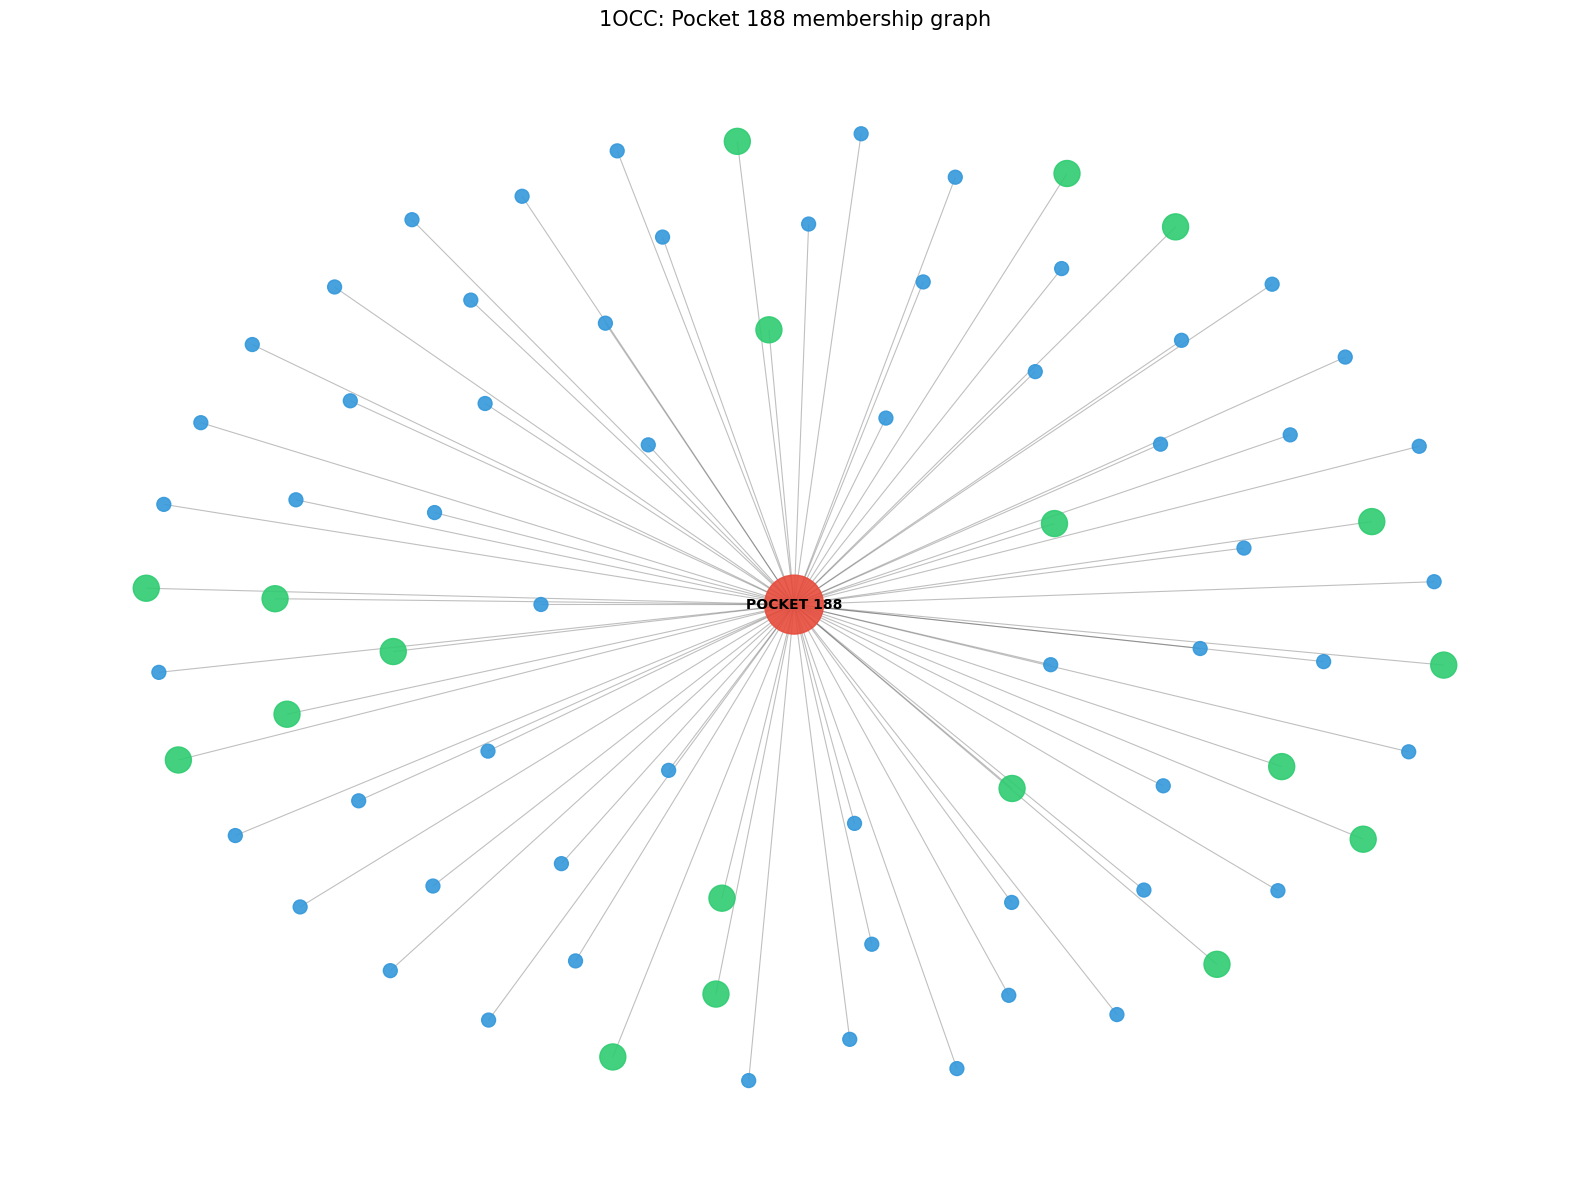


GRAPH SUMMARY
---------------------------------------------------------------------------
Selected pocket:     188
Graph nodes:         77
Graph edges:         76
ATOM nodes:          57
RESIDUE nodes:       19
POCKET nodes:        1

NOTE: Это локальная схема членства выбранного кармана в графе, а не полная визуализация всех 808236 рёбер единого графа CELL9.


## 10.4. Heatmap характеристик карманов

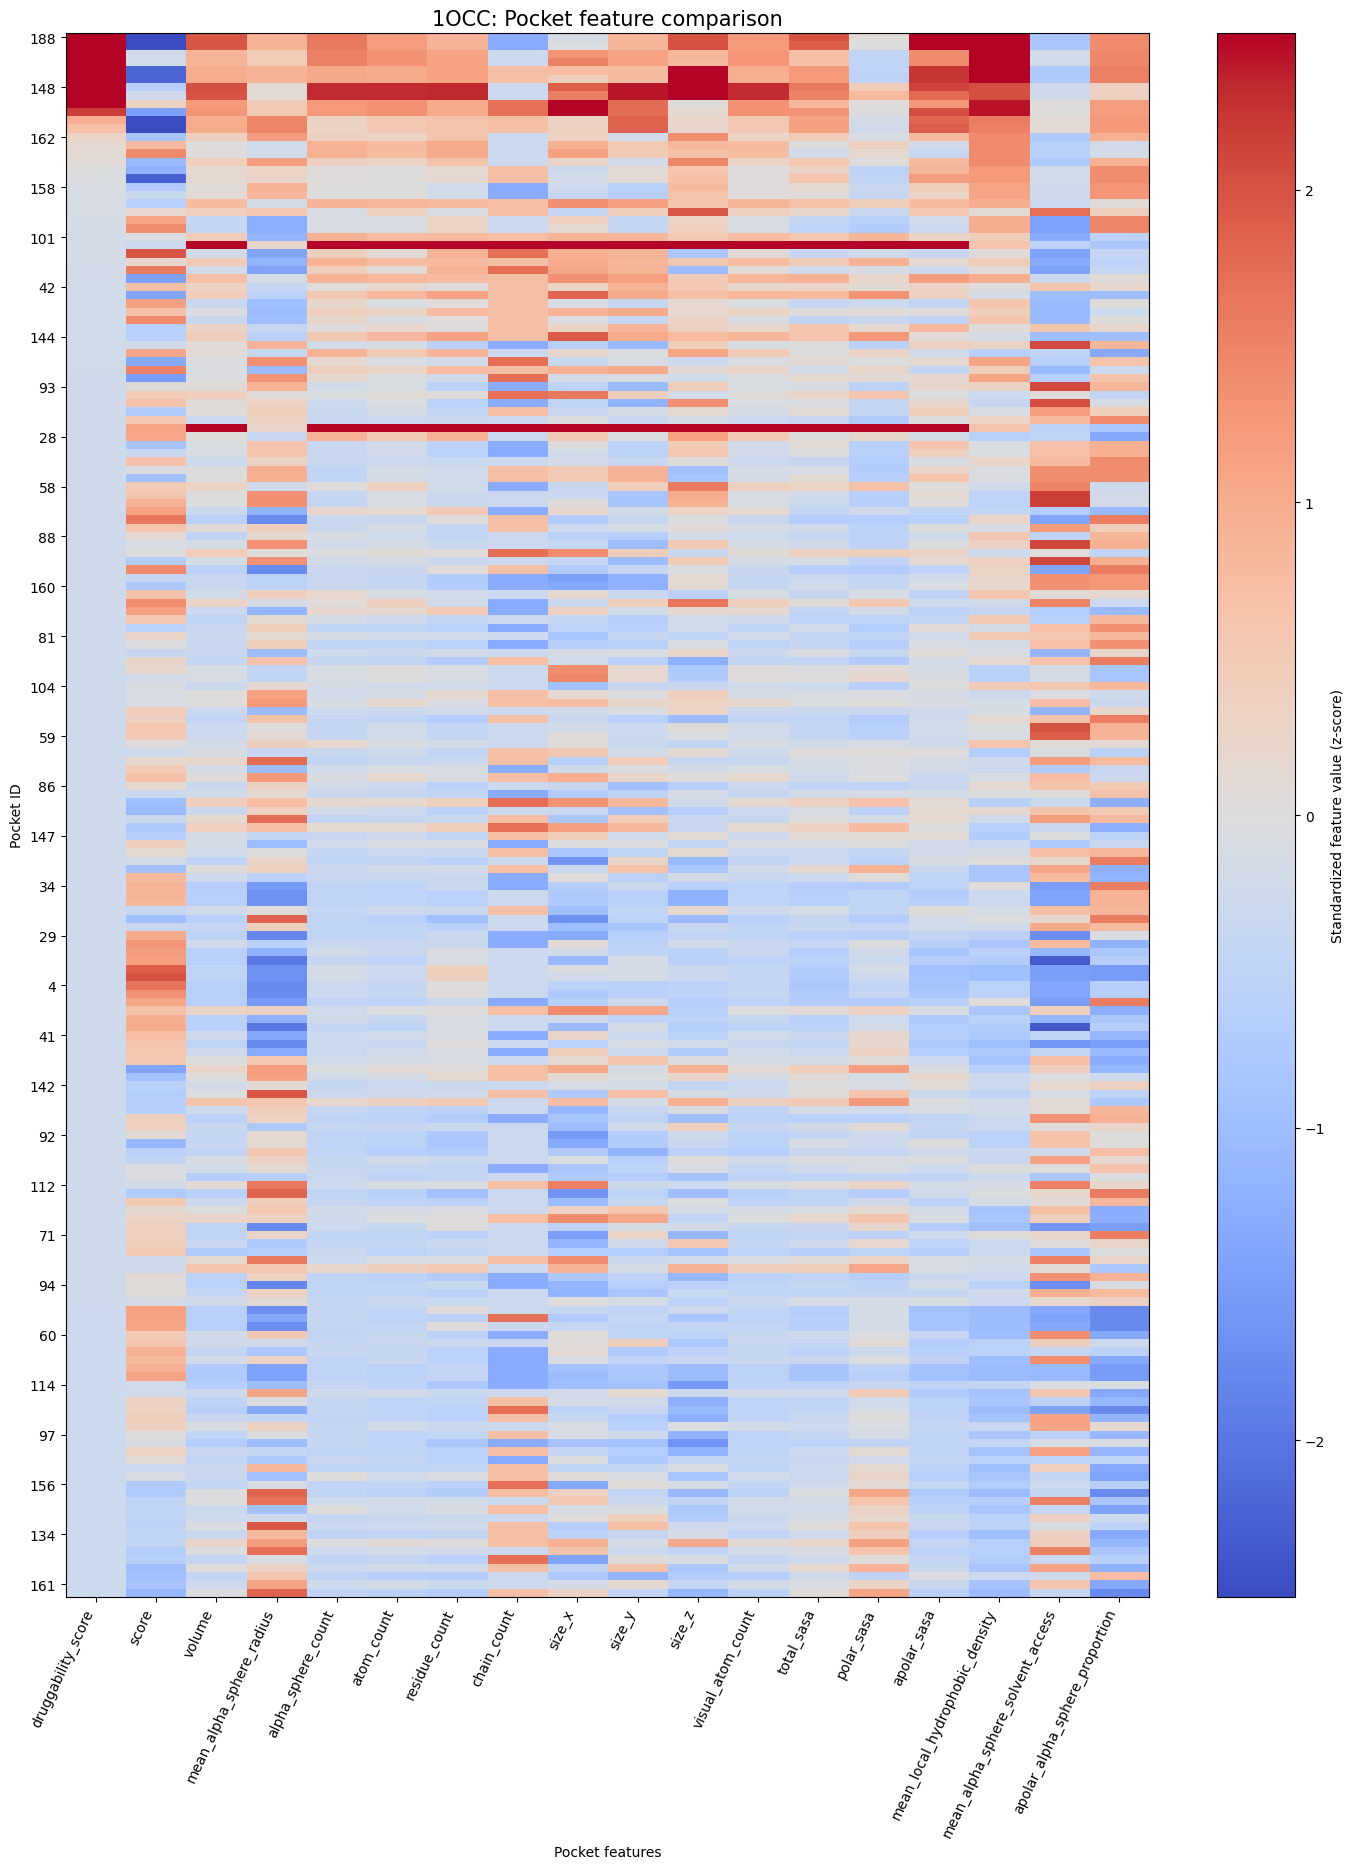

## 10.5. Распределение характеристик карманов

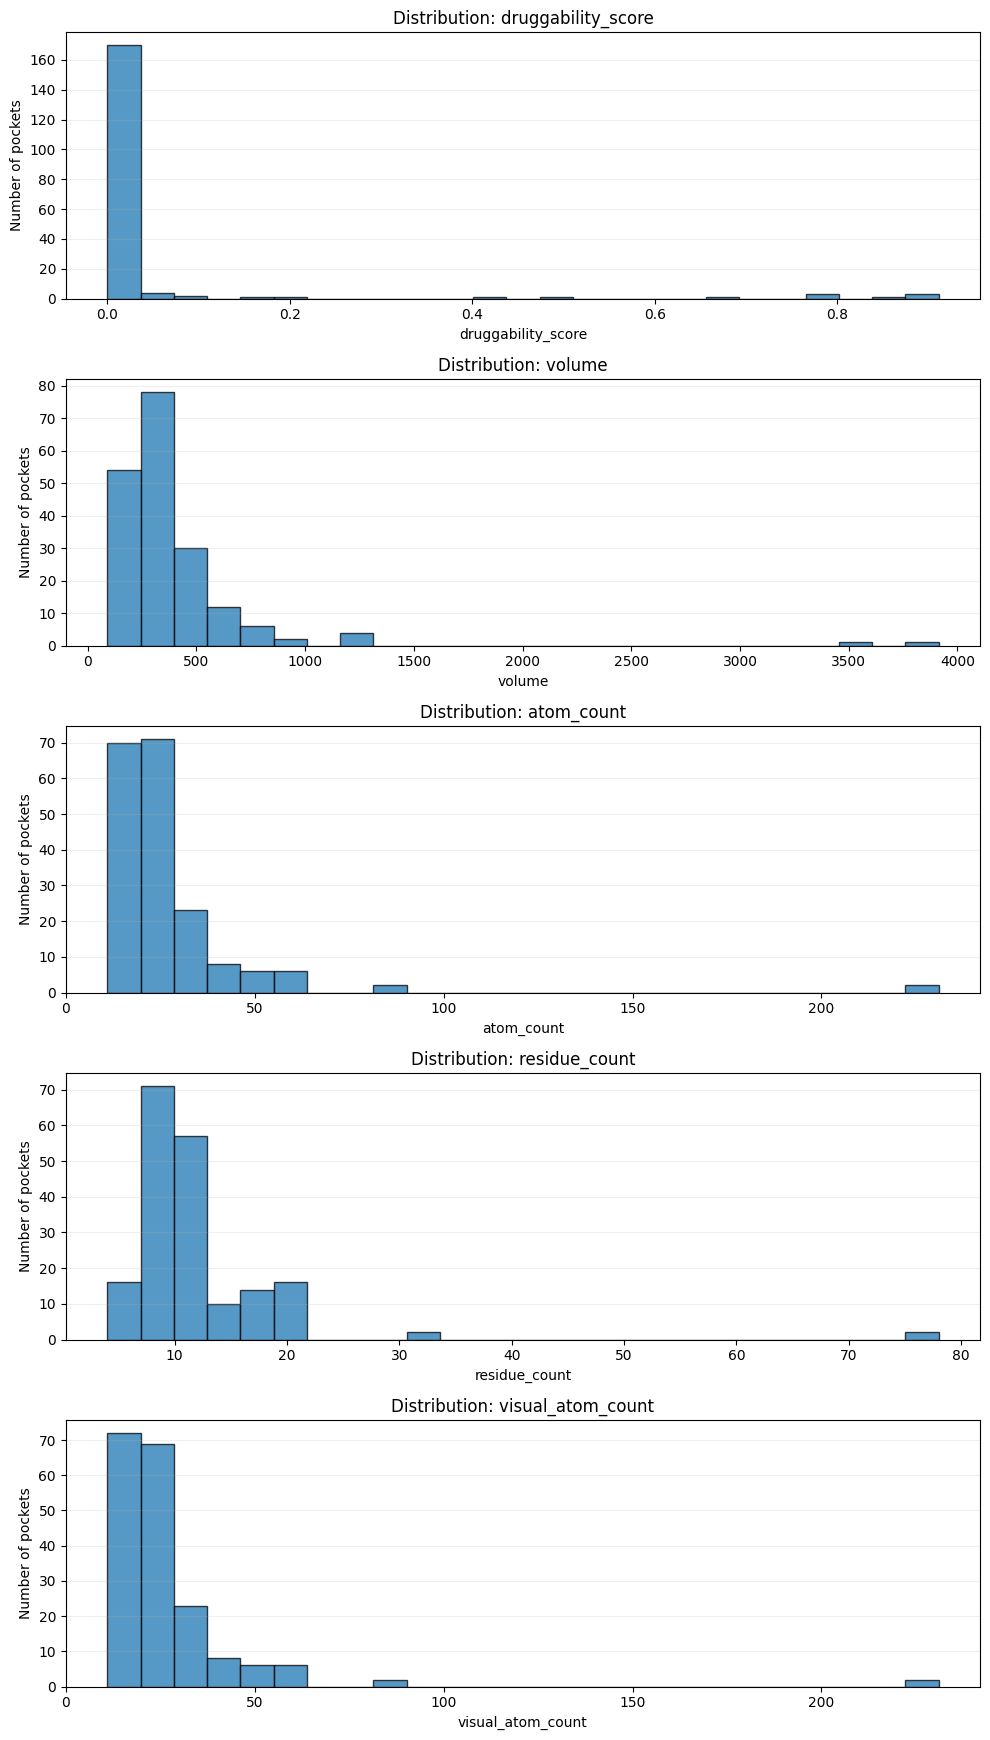

## 10.6. Сохранение результатов визуализации


CELL 10 COMPLETED

VISUALIZATION SUMMARY
---------------------------------------------------------------------------
PDB ID:                       1OCC
Protein atoms:                28,472
Detected pockets:             188
Pocket atom memberships:      5,167
Pocket residue memberships:   2,192
Pockets with coordinates:     188
Ranking metric:               druggability_score

OUTPUT FILES
---------------------------------------------------------------------------
C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analysis\pocket_analysis\results\integration\1OCC\visualization\1OCC_pocket_visualization_centers.csv
C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analysis\pocket_analysis\results\integration\1OCC\visualization\1OCC_visualization_summary.json

All visualization data saved successfully.


In [32]:

# ============================================================
# CELL 10. UNIFIED PROTEIN–POCKET GRAPH VISUALIZATION
# ============================================================
#
# НАЗНАЧЕНИЕ:
#
# Визуализация результатов анализа белковой структуры
# и обнаруженных fpocket карманов.
#
# Блок 10.1:
#   3D-визуализация белковой структуры и найденных карманов.
#
# Блок 10.2:
#   Интерактивный выбор и просмотр отдельного кармана.
#
# Блок 10.3:
#   Визуализация связей POCKET–ATOM–RESIDUE.
#
# Блок 10.4:
#   Heatmap характеристик всех обнаруженных карманов.
#
# ИСПОЛЬЗУЕМ РЕЗУЛЬТАТЫ ПРЕДЫДУЩИХ ЯЧЕЕК:
#
#   protein_coordinates
#   df_pocket_graph_features
#   df_pocket_model_features
#   PDB_ID
#   POCKET_RESULTS_DIR
#
#   CELL7:
#       pocket_atom_mask.npz
#       pocket_residue_mask.npz
#
#   CELL9:
#       unified_protein_pocket_graph.npz
#       unified_graph_nodes.csv
#
# ВАЖНО:
#   Повторный запуск fpocket не требуется.
#   Повторное построение графа не требуется.
# ============================================================


import os
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from mpl_toolkits.mplot3d import Axes3D

from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)


# ============================================================
# 10.0. INITIALIZATION AND INPUT VALIDATION
# ============================================================

print("=" * 75)
print("CELL 10. UNIFIED PROTEIN–POCKET GRAPH VISUALIZATION")
print("=" * 75)


# ------------------------------------------------------------
# 1. Проверяем исходные переменные
# ------------------------------------------------------------

required_variables = [
    "PDB_ID",
    "protein_coordinates",
    "df_pocket_graph_features",
    "POCKET_RESULTS_DIR"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Не найдены необходимые переменные:\n"
        + "\n".join(missing_variables)
        + "\n\nПроверь выполнение CELL1–CELL9."
    )


# ------------------------------------------------------------
# 2. Подготавливаем координаты белка
# ------------------------------------------------------------

protein_xyz = np.asarray(
    protein_coordinates,
    dtype=np.float32
)

if protein_xyz.ndim != 2 or protein_xyz.shape[1] != 3:
    raise ValueError(
        "protein_coordinates должен иметь размерность (N, 3). "
        f"Получено: {protein_xyz.shape}"
    )

if not np.isfinite(protein_xyz).all():
    raise ValueError(
        "В координатах белка обнаружены NaN или Inf."
    )


# ------------------------------------------------------------
# 3. Подготавливаем таблицу карманов
# ------------------------------------------------------------

df_vis_pockets = df_pocket_graph_features.copy()

if "pocket_id" not in df_vis_pockets.columns:
    raise ValueError(
        "В df_pocket_graph_features отсутствует pocket_id."
    )

df_vis_pockets["pocket_id"] = pd.to_numeric(
    df_vis_pockets["pocket_id"],
    errors="coerce"
)

df_vis_pockets = (
    df_vis_pockets
    .dropna(subset=["pocket_id"])
    .copy()
)

df_vis_pockets["pocket_id"] = (
    df_vis_pockets["pocket_id"].astype(int)
)

df_vis_pockets = (
    df_vis_pockets
    .drop_duplicates(subset=["pocket_id"])
    .sort_values("pocket_id")
    .reset_index(drop=True)
)

N_POCKETS = len(df_vis_pockets)
N_ATOMS = len(protein_xyz)

if N_POCKETS == 0:
    raise ValueError("Таблица карманов пуста.")

print("\nINPUT DATA")
print("-" * 75)

print(f"PDB ID:                  {PDB_ID}")
print(f"Protein atoms:           {N_ATOMS:,}")
print(f"Detected pockets:        {N_POCKETS:,}")
print(f"Pocket feature columns:  {len(df_vis_pockets.columns)}")


# ------------------------------------------------------------
# 4. Определяем директорию интеграции
# ------------------------------------------------------------

POCKET_RESULTS_DIR = Path(POCKET_RESULTS_DIR)

INTEGRATION_DIR = (
    POCKET_RESULTS_DIR
    / "integration"
    / str(PDB_ID)
)

# В некоторых версиях проекта интеграционная папка
# может находиться непосредственно в results.

if not INTEGRATION_DIR.exists():

    candidates = [
        POCKET_RESULTS_DIR / str(PDB_ID),
        POCKET_RESULTS_DIR / "integration" / str(PDB_ID)
    ]

    for candidate in candidates:
        if candidate.exists():
            INTEGRATION_DIR = candidate
            break


# ------------------------------------------------------------
# 5. Поиск файлов масок
# ------------------------------------------------------------

def find_project_file(filename, search_root):

    """
    Поиск файла по имени внутри проекта.

    Сначала проверяется ожидаемая директория,
    затем выполняется ограниченный поиск по проекту.
    """

    direct_path = search_root / filename

    if direct_path.exists():
        return direct_path

    project_root = search_root.parent

    matches = list(
        project_root.rglob(filename)
    )

    if matches:
        return matches[0]

    raise FileNotFoundError(
        f"Не найден файл: {filename}\n"
        f"Директория поиска: {project_root}"
    )


ATOM_MASK_PATH = find_project_file(
    f"{PDB_ID}_pocket_atom_mask.npz",
    INTEGRATION_DIR
)

RESIDUE_MASK_PATH = find_project_file(
    f"{PDB_ID}_pocket_residue_mask.npz",
    INTEGRATION_DIR
)


# ------------------------------------------------------------
# 6. Универсальная загрузка матрицы масок
# ------------------------------------------------------------

def load_mask_matrix(path, expected_columns, expected_rows):
    """
    Загружает матрицу масок из NPZ.

    Ожидаемая размерность:
        pocket_mask: (N_pockets, N_atoms)
        residue_mask: (N_pockets, N_residues)

    Название массива внутри NPZ не предполагается заранее.
    """

    archive = np.load(path, allow_pickle=False)

    candidates = []

    for key in archive.files:

        arr = archive[key]

        if arr.ndim == 2:
            candidates.append((key, arr))

    if not candidates:
        raise ValueError(
            f"В файле {path.name} нет двумерных массивов."
        )

    selected = None

    for key, arr in candidates:

        if arr.shape == (
            expected_rows,
            expected_columns
        ):
            selected = (key, arr)
            break

        if arr.shape == (
            expected_columns,
            expected_rows
        ):
            selected = (key, arr.T)
            break

    if selected is None:

        available_shapes = {
            key: arr.shape
            for key, arr in candidates
        }

        raise ValueError(
            f"Не удалось определить матрицу масок в {path.name}.\n"
            f"Ожидается: ({expected_rows}, {expected_columns})\n"
            f"Найдено: {available_shapes}"
        )

    key, mask = selected

    mask = np.asarray(mask, dtype=bool)

    archive.close()

    print(
        f"Loaded mask: {path.name}, "
        f"array={key}, shape={mask.shape}"
    )

    return mask


# ------------------------------------------------------------
# 7. Загружаем маски карманов
# ------------------------------------------------------------

atom_mask = load_mask_matrix(
    ATOM_MASK_PATH,
    expected_columns=N_ATOMS,
    expected_rows=N_POCKETS
)


# Количество остатков берём из маски,
# так как таблица может содержать дополнительные метаданные.

residue_archive = np.load(
    RESIDUE_MASK_PATH,
    allow_pickle=False
)

residue_arrays = [
    residue_archive[key]
    for key in residue_archive.files
    if residue_archive[key].ndim == 2
]

if not residue_arrays:
    residue_archive.close()

    raise ValueError(
        "В residue mask отсутствует двумерный массив."
    )

N_RESIDUES = max(
    arr.shape[1] if arr.shape[0] == N_POCKETS
    else arr.shape[0]
    for arr in residue_arrays
)

residue_archive.close()

residue_mask = load_mask_matrix(
    RESIDUE_MASK_PATH,
    expected_columns=N_RESIDUES,
    expected_rows=N_POCKETS
)


if atom_mask.shape[0] != N_POCKETS:
    raise ValueError("Количество строк atom_mask не совпадает с числом карманов.")

if residue_mask.shape[0] != N_POCKETS:
    raise ValueError("Количество строк residue_mask не совпадает с числом карманов.")


# ------------------------------------------------------------
# 8. Проверяем соответствие порядка pocket_id и масок
# ------------------------------------------------------------

# В CELL7 строки масок создавались в порядке pocket_ids.
# Обычно это тот же порядок, что и в таблице после сортировки.
#
# Для дополнительной проверки ищем список pocket_id
# в NPZ-файлах, если он был сохранён.

def extract_saved_pocket_ids(path):

    archive = np.load(path, allow_pickle=False)

    result = None

    for key in archive.files:

        arr = archive[key]

        if (
            arr.ndim == 1
            and len(arr) == N_POCKETS
            and "pocket" in key.lower()
            and "id" in key.lower()
        ):
            result = np.asarray(arr, dtype=int)
            break

    archive.close()

    return result


saved_pocket_ids = extract_saved_pocket_ids(
    ATOM_MASK_PATH
)

if saved_pocket_ids is not None:

    mask_pocket_ids = saved_pocket_ids

    if not np.array_equal(
        mask_pocket_ids,
        df_vis_pockets["pocket_id"].to_numpy()
    ):
        raise ValueError(
            "Порядок pocket_id в таблице и масках различается. "
            "Нельзя безопасно строить визуализацию."
        )

else:

    mask_pocket_ids = (
        df_vis_pockets["pocket_id"].to_numpy()
    )

    print(
        "\nNOTE: В NPZ не найден отдельный массив pocket_id. "
        "Используется порядок строк CELL7."
    )


print("\nMASK VALIDATION")
print("-" * 75)

print("Atom mask:    ", atom_mask.shape)
print("Residue mask: ", residue_mask.shape)

print(
    "Atom memberships:   ",
    int(atom_mask.sum())
)

print(
    "Residue memberships:",
    int(residue_mask.sum())
)


# ------------------------------------------------------------
# 9. Вычисляем геометрические центры карманов
# ------------------------------------------------------------

pocket_centers = np.full(
    (N_POCKETS, 3),
    np.nan,
    dtype=np.float32
)

pocket_atom_counts = atom_mask.sum(axis=1)

for i in range(N_POCKETS):

    indices = np.flatnonzero(atom_mask[i])

    if len(indices) > 0:

        pocket_centers[i] = protein_xyz[
            indices
        ].mean(axis=0)


# Эти центры вычислены как среднее координат
# белковых атомов, принадлежащих карману.
#
# Это не обязательно совпадает с центром fpocket
# или геометрическим центром alpha spheres.


df_vis_pockets["visual_atom_count"] = (
    pocket_atom_counts
)

df_vis_pockets["visual_center_x"] = (
    pocket_centers[:, 0]
)

df_vis_pockets["visual_center_y"] = (
    pocket_centers[:, 1]
)

df_vis_pockets["visual_center_z"] = (
    pocket_centers[:, 2]
)


# ------------------------------------------------------------
# 10. Определяем рейтинг карманов
# ------------------------------------------------------------

if "druggability_score" in df_vis_pockets.columns:

    ranking_column = "druggability_score"

elif "score" in df_vis_pockets.columns:

    ranking_column = "score"

else:

    ranking_column = "visual_atom_count"

df_vis_pockets[ranking_column] = pd.to_numeric(
    df_vis_pockets[ranking_column],
    errors="coerce"
)

df_vis_pockets = (
    df_vis_pockets
    .sort_values(
        ranking_column,
        ascending=False
    )
    .reset_index(drop=True)
)

top_pocket_ids = (
    df_vis_pockets["pocket_id"]
    .head(min(12, N_POCKETS))
    .tolist()
)

print("\nTOP POCKETS")
print("-" * 75)

display(
    df_vis_pockets[
        [
            "pocket_id",
            ranking_column,
            "visual_atom_count"
        ]
    ].head(10)
)


# ============================================================
# 10.1. 3D PROTEIN AND POCKET VISUALIZATION
# ============================================================

display(
    Markdown(
        "## 10.1. 3D-визуализация белка и найденных карманов"
    )
)


# ------------------------------------------------------------
# Используем Plotly для интерактивного 3D-графика
# ------------------------------------------------------------

try:

    import plotly.graph_objects as go

    from plotly.colors import qualitative

    PLOTLY_AVAILABLE = True

except ImportError:

    PLOTLY_AVAILABLE = False

    print(
        "Plotly не установлен. "
        "Блок 10.1 будет пропущен."
    )


if PLOTLY_AVAILABLE:

    # Для отображения белка используем подвыборку атомов,
    # чтобы не перегружать браузер.

    MAX_PROTEIN_POINTS = 10000

    rng = np.random.default_rng(42)

    if N_ATOMS > MAX_PROTEIN_POINTS:

        background_indices = np.sort(
            rng.choice(
                N_ATOMS,
                size=MAX_PROTEIN_POINTS,
                replace=False
            )
        )

    else:

        background_indices = np.arange(N_ATOMS)


    fig_protein = go.Figure()


    # --------------------------------------------------------
    # Белок: все атомы или подвыборка
    # --------------------------------------------------------

    fig_protein.add_trace(
        go.Scatter3d(
            x=protein_xyz[background_indices, 0],
            y=protein_xyz[background_indices, 1],
            z=protein_xyz[background_indices, 2],
            mode="markers",
            name="Protein atoms",
            marker=dict(
                size=1.5,
                color="lightgray",
                opacity=0.18
            ),
            hoverinfo="skip"
        )
    )


    # --------------------------------------------------------
    # Карманы: показываем 12 наиболее высокоранговых
    # --------------------------------------------------------

    palette = qualitative.Plotly

    for rank, pocket_id in enumerate(top_pocket_ids):

        row_index = int(
            np.where(
                mask_pocket_ids == pocket_id
            )[0][0]
        )

        atom_indices = np.flatnonzero(
            atom_mask[row_index]
        )

        if len(atom_indices) == 0:
            continue

        xyz = protein_xyz[atom_indices]

        pocket_row = df_vis_pockets.loc[
            df_vis_pockets["pocket_id"] == pocket_id
        ].iloc[0]

        score_value = pocket_row[ranking_column]

        fig_protein.add_trace(
            go.Scatter3d(
                x=xyz[:, 0],
                y=xyz[:, 1],
                z=xyz[:, 2],
                mode="markers",
                name=f"Pocket {pocket_id}",
                marker=dict(
                    size=4,
                    color=palette[
                        rank % len(palette)
                    ],
                    opacity=0.9
                ),
                text=[
                    f"Pocket ID: {pocket_id}<br>"
                    f"Atom index: {idx}<br>"
                    f"{ranking_column}: {score_value:.3f}"
                    if pd.notna(score_value)
                    else f"Pocket ID: {pocket_id}"
                    for idx in atom_indices
                ],
                hovertemplate="%{text}<extra></extra>"
            )
        )


    # --------------------------------------------------------
    # Центры карманов
    # --------------------------------------------------------

    valid_centers = np.isfinite(
        pocket_centers
    ).all(axis=1)

    center_ids = mask_pocket_ids[
        valid_centers
    ]

    center_xyz = pocket_centers[
        valid_centers
    ]

    fig_protein.add_trace(
        go.Scatter3d(
            x=center_xyz[:, 0],
            y=center_xyz[:, 1],
            z=center_xyz[:, 2],
            mode="markers",
            name="Pocket centers",
            marker=dict(
                size=4,
                color="black",
                symbol="diamond",
                opacity=0.8
            ),
            text=[
                f"Pocket center: {pocket_id}"
                for pocket_id in center_ids
            ],
            hovertemplate="%{text}<extra></extra>"
        )
    )


    fig_protein.update_layout(
        title=(
            f"{PDB_ID}: Protein structure "
            f"and top {len(top_pocket_ids)} fpocket pockets"
        ),
        scene=dict(
            xaxis_title="X (Å)",
            yaxis_title="Y (Å)",
            zaxis_title="Z (Å)",
            aspectmode="data"
        ),
        width=1000,
        height=750,
        legend=dict(
            itemsizing="constant"
        ),
        margin=dict(
            l=0,
            r=0,
            b=0,
            t=60
        )
    )

    fig_protein.show()


# ============================================================
# 10.2. INTERACTIVE POCKET VIEWER
# ============================================================

display(
    Markdown(
        "## 10.2. Интерактивный просмотр отдельного кармана"
    )
)


if PLOTLY_AVAILABLE:

    # --------------------------------------------------------
    # Формируем интерактивный график с переключением карманов
    # --------------------------------------------------------

    MAX_VIEW_POCKETS = min(30, N_POCKETS)

    viewer_pocket_ids = (
        df_vis_pockets["pocket_id"]
        .head(MAX_VIEW_POCKETS)
        .tolist()
    )

    fig_viewer = go.Figure()


    # Фоновая структура белка

    fig_viewer.add_trace(
        go.Scatter3d(
            x=protein_xyz[background_indices, 0],
            y=protein_xyz[background_indices, 1],
            z=protein_xyz[background_indices, 2],
            mode="markers",
            name="Protein",
            marker=dict(
                size=1.5,
                color="lightgray",
                opacity=0.12
            ),
            hoverinfo="skip",
            visible=True
        )
    )


    # Центр выбранного кармана и его атомы

    visibility_by_pocket = []

    for i, pocket_id in enumerate(viewer_pocket_ids):

        row_index = int(
            np.where(
                mask_pocket_ids == pocket_id
            )[0][0]
        )

        atom_indices = np.flatnonzero(
            atom_mask[row_index]
        )

        xyz = protein_xyz[atom_indices]

        pocket_center = pocket_centers[row_index]

        pocket_row = df_vis_pockets.loc[
            df_vis_pockets["pocket_id"] == pocket_id
        ].iloc[0]

        score_value = pocket_row[ranking_column]

        visible = (i == 0)

        fig_viewer.add_trace(
            go.Scatter3d(
                x=xyz[:, 0],
                y=xyz[:, 1],
                z=xyz[:, 2],
                mode="markers",
                name=f"Pocket {pocket_id}",
                marker=dict(
                    size=5,
                    color="red",
                    opacity=0.95
                ),
                text=[
                    f"Pocket: {pocket_id}<br>"
                    f"Atom index: {idx}"
                    for idx in atom_indices
                ],
                hovertemplate="%{text}<extra></extra>",
                visible=visible
            )
        )


        fig_viewer.add_trace(
            go.Scatter3d(
                x=[pocket_center[0]],
                y=[pocket_center[1]],
                z=[pocket_center[2]],
                mode="markers",
                name=f"Center {pocket_id}",
                marker=dict(
                    size=8,
                    color="black",
                    symbol="diamond"
                ),
                text=[
                    f"Pocket {pocket_id}<br>"
                    f"{ranking_column}: {score_value:.3f}"
                    if pd.notna(score_value)
                    else f"Pocket {pocket_id}"
                ],
                hovertemplate="%{text}<extra></extra>",
                visible=visible
            )
        )


    # --------------------------------------------------------
    # Формируем кнопки переключения
    # --------------------------------------------------------

    buttons = []

    for i, pocket_id in enumerate(viewer_pocket_ids):

        visibility = [
            True
        ] + [
            False
        ] * (2 * MAX_VIEW_POCKETS)

        visibility[1 + 2 * i] = True
        visibility[2 + 2 * i] = True

        buttons.append(
            dict(
                label=f"Pocket {pocket_id}",
                method="update",
                args=[
                    {
                        "visible": visibility
                    },
                    {
                        "title": (
                            f"{PDB_ID}: Pocket {pocket_id}"
                        )
                    }
                ]
            )
        )


    fig_viewer.update_layout(
        title=(
            f"{PDB_ID}: Pocket {viewer_pocket_ids[0]}"
        ),
        updatemenus=[
            dict(
                type="dropdown",
                direction="down",
                x=0.02,
                y=1.12,
                buttons=buttons,
                showactive=True
            )
        ],
        scene=dict(
            xaxis_title="X (Å)",
            yaxis_title="Y (Å)",
            zaxis_title="Z (Å)",
            aspectmode="data"
        ),
        width=950,
        height=700,
        margin=dict(
            l=0,
            r=0,
            b=0,
            t=100
        )
    )

    fig_viewer.show()

    print(
        f"Интерактивный просмотр подготовлен "
        f"для {MAX_VIEW_POCKETS} карманов."
    )


# ============================================================
# 10.3. POCKET–ATOM–RESIDUE GRAPH VISUALIZATION
# ============================================================

display(
    Markdown(
        "## 10.3. Граф связей POCKET–ATOM–RESIDUE"
    )
)


# ------------------------------------------------------------
# Для графа используем NetworkX
# ------------------------------------------------------------

try:

    import networkx as nx

    NETWORKX_AVAILABLE = True

except ImportError:

    NETWORKX_AVAILABLE = False

    print(
        "NetworkX не установлен. "
        "Блок 10.3 будет пропущен."
    )


if NETWORKX_AVAILABLE:

    # Выбираем наиболее высокоранговый карман.

    selected_pocket_id = int(
        df_vis_pockets.iloc[0]["pocket_id"]
    )

    selected_row = int(
        np.where(
            mask_pocket_ids == selected_pocket_id
        )[0][0]
    )

    selected_atom_indices = np.flatnonzero(
        atom_mask[selected_row]
    )

    selected_residue_indices = np.flatnonzero(
        residue_mask[selected_row]
    )


    # --------------------------------------------------------
    # Ограничиваем размер графа для читаемости
    # --------------------------------------------------------

    MAX_GRAPH_ATOMS = 80
    MAX_GRAPH_RESIDUES = 60

    selected_atom_indices = (
        selected_atom_indices[:MAX_GRAPH_ATOMS]
    )

    selected_residue_indices = (
        selected_residue_indices[:MAX_GRAPH_RESIDUES]
    )


    G = nx.Graph()


    # --------------------------------------------------------
    # Создаём узел POCKET
    # --------------------------------------------------------

    G.add_node(
        f"P_{selected_pocket_id}",
        node_type="POCKET",
        label=f"Pocket {selected_pocket_id}"
    )


    # --------------------------------------------------------
    # Создаём узлы ATOM
    # --------------------------------------------------------

    for atom_idx in selected_atom_indices:

        atom_node = f"A_{atom_idx}"

        G.add_node(
            atom_node,
            node_type="ATOM",
            label=f"Atom {atom_idx}"
        )

        G.add_edge(
            f"P_{selected_pocket_id}",
            atom_node,
            relation="POCKET_ATOM"
        )


    # --------------------------------------------------------
    # Создаём узлы RESIDUE
    # --------------------------------------------------------

    for residue_idx in selected_residue_indices:

        residue_node = f"R_{residue_idx}"

        G.add_node(
            residue_node,
            node_type="RESIDUE",
            label=f"Residue {residue_idx}"
        )

        G.add_edge(
            f"P_{selected_pocket_id}",
            residue_node,
            relation="POCKET_RESIDUE"
        )


    # --------------------------------------------------------
    # Визуализация
    # --------------------------------------------------------

    plt.figure(figsize=(16, 12))

    pos = nx.spring_layout(
        G,
        seed=42,
        k=0.8,
        iterations=80
    )


    node_colors = []

    node_sizes = []

    for node in G.nodes:

        node_type = G.nodes[node]["node_type"]

        if node_type == "POCKET":

            node_colors.append("#E74C3C")
            node_sizes.append(1800)

        elif node_type == "ATOM":

            node_colors.append("#3498DB")
            node_sizes.append(100)

        else:

            node_colors.append("#2ECC71")
            node_sizes.append(350)


    nx.draw_networkx_edges(
        G,
        pos,
        alpha=0.25,
        width=0.8
    )

    nx.draw_networkx_nodes(
        G,
        pos,
        node_color=node_colors,
        node_size=node_sizes,
        alpha=0.9
    )


    # Подписываем только центральный узел,
    # чтобы избежать перегруженности изображения.

    nx.draw_networkx_labels(
        G,
        pos,
        labels={
            f"P_{selected_pocket_id}":
            f"POCKET {selected_pocket_id}"
        },
        font_size=10,
        font_weight="bold"
    )


    plt.title(
        f"{PDB_ID}: Pocket {selected_pocket_id} "
        f"membership graph",
        fontsize=15
    )

    plt.axis("off")
    plt.tight_layout()
    plt.show()


    print("\nGRAPH SUMMARY")
    print("-" * 75)

    print(f"Selected pocket:     {selected_pocket_id}")
    print(f"Graph nodes:         {G.number_of_nodes():,}")
    print(f"Graph edges:         {G.number_of_edges():,}")

    print(
        f"ATOM nodes:          "
        f"{sum(G.nodes[n]['node_type'] == 'ATOM' for n in G.nodes):,}"
    )

    print(
        f"RESIDUE nodes:       "
        f"{sum(G.nodes[n]['node_type'] == 'RESIDUE' for n in G.nodes):,}"
    )

    print("POCKET nodes:        1")


    print(
        "\nNOTE: Это локальная схема членства выбранного кармана "
        "в графе, а не полная визуализация всех 808236 рёбер "
        "единого графа CELL9."
    )


# ============================================================
# 10.4. POCKET FEATURE HEATMAP
# ============================================================

display(
    Markdown(
        "## 10.4. Heatmap характеристик карманов"
    )
)


# ------------------------------------------------------------
# Выбираем числовые характеристики
# ------------------------------------------------------------

df_heatmap = df_vis_pockets.copy()

numeric_columns = (
    df_heatmap
    .select_dtypes(include=[np.number])
    .columns
    .tolist()
)


# ------------------------------------------------------------
# Исключаем идентификаторы и технические поля
# ------------------------------------------------------------

excluded_columns = {
    "pocket_id",
    "visual_center_x",
    "visual_center_y",
    "visual_center_z",
    "total_atom_records",
    "protein_atom_records",
    "matched_atom_records",
    "unmatched_atom_records",
    "excluded_hetatm_records",
    "mapping_fraction",
    "mapped_atom_count",
    "mapped_residue_count"
}

excluded_prefixes = (
    "mapping_",
    "unmatched_",
    "excluded_",
    "matched_"
)

heatmap_columns = []

for col in numeric_columns:

    if col in excluded_columns:
        continue

    if col.startswith(excluded_prefixes):
        continue

    if df_heatmap[col].nunique(dropna=True) <= 1:
        continue

    heatmap_columns.append(col)


# Сначала используем наиболее полезные признаки,
# если они присутствуют в таблице.

preferred_columns = [
    "druggability_score",
    "score",
    "volume",
    "sasa",
    "mean_alpha_sphere_radius",
    "mean_alpha_sphere",
    "alpha_sphere_count",
    "atom_count",
    "residue_count",
    "chain_count",
    "size_x",
    "size_y",
    "size_z",
    "visual_atom_count"
]

ordered_columns = [
    col for col in preferred_columns
    if col in heatmap_columns
]

ordered_columns += [
    col for col in heatmap_columns
    if col not in ordered_columns
]

# Не перегружаем heatmap большим числом признаков.

MAX_HEATMAP_FEATURES = 18

heatmap_columns = ordered_columns[
    :MAX_HEATMAP_FEATURES
]


if len(heatmap_columns) >= 2:

    heatmap_data = (
        df_heatmap[
            ["pocket_id"] + heatmap_columns
        ]
        .set_index("pocket_id")
        .copy()
    )

    # Нормализация каждого признака:
    # z-score позволяет сравнивать характеристики
    # с разными единицами измерения.

    heatmap_std = heatmap_data.std(
        axis=0,
        ddof=0
    )

    valid_features = (
        heatmap_std.replace(0, np.nan)
        .dropna()
        .index
    )

    heatmap_data = heatmap_data[
        valid_features
    ]

    heatmap_data = (
        heatmap_data
        .fillna(heatmap_data.median())
    )

    heatmap_std = heatmap_data.std(
        axis=0,
        ddof=0
    ).replace(0, 1)

    heatmap_z = (
        heatmap_data - heatmap_data.mean()
    ) / heatmap_std

    # Сортируем карманы по druggability,
    # если показатель существует.

    if "druggability_score" in df_heatmap.columns:

        ordered_ids = (
            df_heatmap
            .sort_values(
                "druggability_score",
                ascending=False
            )["pocket_id"]
            .tolist()
        )

        heatmap_z = heatmap_z.reindex(
            ordered_ids
        )


    # --------------------------------------------------------
    # Строим heatmap
    # --------------------------------------------------------

    fig_width = max(
        12,
        len(heatmap_z.columns) * 0.8
    )

    fig_height = max(
        8,
        min(20, len(heatmap_z) * 0.10)
    )

    plt.figure(
        figsize=(fig_width, fig_height)
    )

    plt.imshow(
        heatmap_z.to_numpy(),
        aspect="auto",
        interpolation="nearest",
        cmap="coolwarm",
        vmin=-2.5,
        vmax=2.5
    )

    plt.colorbar(
        label="Standardized feature value (z-score)"
    )

    plt.xticks(
        ticks=np.arange(len(heatmap_z.columns)),
        labels=heatmap_z.columns,
        rotation=65,
        ha="right"
    )

    # Для большого числа карманов
    # показываем только часть подписей по оси Y.

    y_step = max(
        1,
        len(heatmap_z) // 30
    )

    y_positions = np.arange(
        0,
        len(heatmap_z),
        y_step
    )

    y_labels = [
        str(heatmap_z.index[i])
        for i in y_positions
    ]

    plt.yticks(
        y_positions,
        y_labels
    )

    plt.xlabel("Pocket features")
    plt.ylabel("Pocket ID")

    plt.title(
        f"{PDB_ID}: Pocket feature comparison",
        fontsize=15
    )

    plt.tight_layout()
    plt.show()


else:

    print(
        "Недостаточно числовых признаков "
        "для построения heatmap."
    )


# ============================================================
# 10.5. POCKET SIZE AND DRUGGABILITY DISTRIBUTIONS
# ============================================================

display(
    Markdown(
        "## 10.5. Распределение характеристик карманов"
    )
)


# ------------------------------------------------------------
# Подготавливаем показатели для гистограмм
# ------------------------------------------------------------

distribution_columns = []

for col in [
    "druggability_score",
    "volume",
    "atom_count",
    "residue_count",
    "visual_atom_count"
]:

    if col in df_vis_pockets.columns:

        distribution_columns.append(col)


if distribution_columns:

    n_plots = len(distribution_columns)

    fig, axes = plt.subplots(
        n_plots,
        1,
        figsize=(10, 3.5 * n_plots)
    )

    if n_plots == 1:
        axes = [axes]

    for ax, col in zip(
        axes,
        distribution_columns
    ):

        values = pd.to_numeric(
            df_vis_pockets[col],
            errors="coerce"
        ).dropna()

        ax.hist(
            values,
            bins=25,
            edgecolor="black",
            alpha=0.75
        )

        ax.set_title(
            f"Distribution: {col}"
        )

        ax.set_xlabel(col)
        ax.set_ylabel("Number of pockets")

        ax.grid(
            alpha=0.2,
            axis="y"
        )

    plt.tight_layout()
    plt.show()


# ============================================================
# 10.6. SAVE VISUALIZATION DATA AND SUMMARY
# ============================================================

display(
    Markdown(
        "## 10.6. Сохранение результатов визуализации"
    )
)


VISUALIZATION_DIR = (
    INTEGRATION_DIR
    / "visualization"
)

VISUALIZATION_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# 1. Сохраняем таблицу с центрами карманов
# ------------------------------------------------------------

CENTERS_PATH = (
    VISUALIZATION_DIR
    / f"{PDB_ID}_pocket_visualization_centers.csv"
)

df_vis_pockets.to_csv(
    CENTERS_PATH,
    index=False
)


# ------------------------------------------------------------
# 2. Сохраняем компактное описание визуализации
# ------------------------------------------------------------

visualization_summary = {

    "pdb_id": str(PDB_ID),

    "protein_atom_count": int(N_ATOMS),

    "pocket_count": int(N_POCKETS),

    "atom_mask_shape": list(
        atom_mask.shape
    ),

    "residue_mask_shape": list(
        residue_mask.shape
    ),

    "total_pocket_atom_memberships": int(
        atom_mask.sum()
    ),

    "total_pocket_residue_memberships": int(
        residue_mask.sum()
    ),

    "pockets_with_coordinates": int(
        np.isfinite(pocket_centers).all(axis=1).sum()
    ),

    "ranking_column": str(ranking_column),

    "top_pocket_ids": [
        int(x) for x in top_pocket_ids
    ],

    "visualization_blocks": [

        "3D protein and pocket visualization",

        "Interactive pocket viewer",

        "Pocket-atom-residue membership graph",

        "Pocket feature heatmap",

        "Pocket feature distributions"

    ],

    "interpretation_notes": [

        "Pocket centers are calculated as mean coordinates "
        "of protein atoms belonging to each pocket.",

        "The 3D protein background may use an atom subsample.",

        "The local membership graph is a simplified visualization "
        "and does not display every edge of the unified graph.",

        "Druggability score is a computational descriptor "
        "and does not establish biological binding or efficacy."

    ]

}


SUMMARY_PATH = (
    VISUALIZATION_DIR
    / f"{PDB_ID}_visualization_summary.json"
)

with open(
    SUMMARY_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        visualization_summary,
        f,
        ensure_ascii=False,
        indent=4
    )


# ------------------------------------------------------------
# 3. Итог
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CELL 10 COMPLETED")
print("=" * 75)

print("\nVISUALIZATION SUMMARY")
print("-" * 75)

print(f"PDB ID:                       {PDB_ID}")
print(f"Protein atoms:                {N_ATOMS:,}")
print(f"Detected pockets:             {N_POCKETS:,}")

print(
    f"Pocket atom memberships:      "
    f"{int(atom_mask.sum()):,}"
)

print(
    f"Pocket residue memberships:   "
    f"{int(residue_mask.sum()):,}"
)

print(
    f"Pockets with coordinates:     "
    f"{visualization_summary['pockets_with_coordinates']:,}"
)

print(
    f"Ranking metric:               "
    f"{ranking_column}"
)

print("\nOUTPUT FILES")
print("-" * 75)

print(CENTERS_PATH)
print(SUMMARY_PATH)

print("\nAll visualization data saved successfully.")
print("=" * 75)


In [37]:

# ============================================================
# CELL 11. CREATE UNIFIED PROTEIN-POCKET DATASET
# ============================================================
#
# НАЗНАЧЕНИЕ:
#
# Создание единого структурированного набора данных,
# объединяющего:
#
# 1. Метаданные исходной структуры белка.
# 2. Атомные признаки белка.
# 3. Признаки аминокислотных остатков.
# 4. Глобальные признаки белка.
# 5. Геометрические признаки карманов.
# 6. Признаки карманов для машинного обучения.
# 7. Маски принадлежности атомов и остатков карманам.
# 8. Объединённый граф ATOM + RESIDUE + POCKET из CELL9.
#
# РЕЗУЛЬТАТ:
#
# 1. NPZ — единый файл с числовыми массивами и метаданными.
# 2. JSON — подробное описание датасета, программы,
#    времени создания и контрольной суммы SHA256.
#
# ВАЖНО:
# Для объединённого графа используется файл CELL9:
#
# 1OCC_unified_protein_pocket_graph.npz
#
# Не используется protein_graph из CELL3, поскольку
# это исходный граф белка, а не граф белок-карман.
#
# ============================================================


# ============================================================
# 11.1. IMPORTS
# ============================================================

import os
import sys
import json
import hashlib
import platform
import subprocess

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd


# ============================================================
# 11.2. CHECK REQUIRED VARIABLES
# ============================================================

required_variables = [
    "PDB_ID",
    "POCKET_RESULTS_DIR",
    "POCKET_GEOMETRY_DIR",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        "Не найдены необходимые переменные: "
        f"{missing_variables}\n"
        "Сначала выполни CELL1–CELL10."
    )

PDB_ID = str(PDB_ID)

POCKET_RESULTS_DIR = Path(POCKET_RESULTS_DIR)
POCKET_GEOMETRY_DIR = Path(POCKET_GEOMETRY_DIR)

# Основная папка интеграции
INTEGRATION_DIR = (
    POCKET_RESULTS_DIR
    / "integration"
    / PDB_ID
)

# Папка объединённого графа CELL9
UNIFIED_GRAPH_DIR = (
    INTEGRATION_DIR
    / "unified_protein_pocket_graph"
)

UNIFIED_GRAPH_PATH = (
    UNIFIED_GRAPH_DIR
    / f"{PDB_ID}_unified_protein_pocket_graph.npz"
)

# Папка единого датасета
UNIFIED_DATASET_DIR = (
    INTEGRATION_DIR
    / "unified_dataset"
)

UNIFIED_DATASET_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Итоговые файлы
DATASET_PATH = (
    UNIFIED_DATASET_DIR
    / f"{PDB_ID}_structure_dataset.npz"
)

METADATA_PATH = (
    UNIFIED_DATASET_DIR
    / f"{PDB_ID}_structure_dataset_metadata.json"
)

# Файлы CELL6
GEOMETRY_FEATURES_PATH = (
    POCKET_GEOMETRY_DIR
    / f"{PDB_ID}_pocket_geometry_features.csv"
)

# Файлы CELL7
POCKET_MODEL_FEATURES_PATH = (
    INTEGRATION_DIR
    / f"{PDB_ID}_pocket_model_features.csv"
)

POCKET_GRAPH_FEATURES_PATH = (
    INTEGRATION_DIR
    / f"{PDB_ID}_pocket_graph_features.csv"
)

# Файлы масок CELL7
ATOM_MASK_PATH = (
    INTEGRATION_DIR
    / f"{PDB_ID}_pocket_atom_mask.npz"
)

RESIDUE_MASK_PATH = (
    INTEGRATION_DIR
    / f"{PDB_ID}_pocket_residue_mask.npz"
)

# Исходная структура
SOURCE_STRUCTURE_PATH = Path(
    globals().get(
        "SOURCE_STRUCTURE_PATH",
        globals().get(
            "ORIGINAL_STRUCTURE_PATH",
            ""
        )
    )
) if (
    globals().get("SOURCE_STRUCTURE_PATH")
    or globals().get("ORIGINAL_STRUCTURE_PATH")
) else None

print("=" * 75)
print("CELL 11. UNIFIED PROTEIN-POCKET DATASET")
print("=" * 75)

print("PDB ID:", PDB_ID)
print("Integration directory:", INTEGRATION_DIR)
print("Dataset directory:", UNIFIED_DATASET_DIR)


# ============================================================
# 11.3. HELPER FUNCTIONS
# ============================================================

def dataframe_to_numeric_matrix(df, exclude_columns=None):
    """
    Преобразование DataFrame в числовую матрицу.

    Исключаются:
    - идентификаторы;
    - текстовые столбцы;
    - явно указанные служебные поля.

    Возвращаются:
    - числовая матрица;
    - названия признаков.
    """

    if df is None:
        return (
            np.empty((0, 0), dtype=np.float32),
            []
        )

    if isinstance(df, pd.Series):
        df = df.to_frame().T

    if not isinstance(df, pd.DataFrame):
        df = pd.DataFrame(df)

    exclude_columns = set(
        exclude_columns or []
    )

    numeric_df = df.select_dtypes(
        include=[np.number, "bool"]
    ).copy()

    numeric_df = numeric_df.drop(
        columns=[
            col for col in numeric_df.columns
            if col in exclude_columns
        ],
        errors="ignore"
    )

    # Преобразование в float32 для экономии памяти
    matrix = numeric_df.to_numpy(
        dtype=np.float32,
        copy=True
    )

    return matrix, list(numeric_df.columns)


def dataframe_to_json(df):
    """
    Сохранение DataFrame в JSON-совместимом формате.
    """

    if df is None:
        return []

    if isinstance(df, pd.Series):
        df = df.to_frame().T

    if not isinstance(df, pd.DataFrame):
        df = pd.DataFrame(df)

    return json.loads(
        df.replace(
            {np.nan: None}
        ).to_json(
            orient="records",
            force_ascii=False
        )
    )


def load_mask_array(path, expected_rows=None, expected_cols=None):
    """
    Загрузка NPZ-маски.

    Функция не предполагает заранее конкретное имя
    массива внутри NPZ.

    Ищет двумерный массив, соответствующий ожидаемым
    размерам.
    """

    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(
            f"Не найден файл маски:\n{path}"
        )

    with np.load(
        path,
        allow_pickle=False
    ) as data:

        candidates = []

        for key in data.files:

            arr = data[key]

            if arr.ndim != 2:
                continue

            if (
                expected_rows is not None
                and arr.shape[0] != expected_rows
            ):
                continue

            if (
                expected_cols is not None
                and arr.shape[1] != expected_cols
            ):
                continue

            candidates.append(
                (key, arr.copy())
            )

        if not candidates:
            raise ValueError(
                f"В файле {path.name} не найдена "
                "подходящая двумерная маска.\n"
                f"Доступные массивы: {data.files}"
            )

        if len(candidates) > 1:
            print(
                f"Предупреждение: в {path.name} "
                "найдено несколько подходящих массивов. "
                "Используется первый."
            )

        key, mask = candidates[0]

    return mask, key


def calculate_sha256(path, chunk_size=1024 * 1024):
    """
    Вычисление SHA256 файла потоковым способом.
    Не загружает весь файл в оперативную память.
    """

    sha256 = hashlib.sha256()

    with open(path, "rb") as file:

        while True:

            chunk = file.read(chunk_size)

            if not chunk:
                break

            sha256.update(chunk)

    return sha256.hexdigest()


def get_git_commit():
    """
    Получение Git commit, если проект находится
    в Git-репозитории.
    """

    try:

        result = subprocess.run(
            ["git", "rev-parse", "HEAD"],
            capture_output=True,
            text=True,
            timeout=3,
            check=True
        )

        return result.stdout.strip()

    except Exception:
        return None


def json_safe(value):
    """
    Преобразование объектов в JSON-совместимые значения.
    """

    if isinstance(value, Path):
        return str(value)

    if isinstance(value, np.ndarray):
        return value.tolist()

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, dict):
        return {
            str(k): json_safe(v)
            for k, v in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [
            json_safe(v)
            for v in value
        ]

    if isinstance(value, (str, int, float, bool)) or value is None:
        return value

    return str(value)


# ============================================================
# 11.4. LOAD UNIFIED GRAPH FROM CELL9
# ============================================================
#
# Загружаем объединённый граф белок–карманы.
#
# В CELL9:
# edge_index_all — все связи графа
# edge_type_all  — типы всех связей
#
# Внутри CELL11 создаём совместимые переменные:
# edge_index и edge_type.
#
# Это позволяет не менять остальной код CELL11.
# ============================================================

print("\n" + "=" * 75)
print("11.4. LOAD UNIFIED PROTEIN-POCKET GRAPH")
print("=" * 75)

if not UNIFIED_GRAPH_PATH.exists():

    raise FileNotFoundError(
        "Не найден объединённый граф CELL9:\n"
        f"{UNIFIED_GRAPH_PATH}"
    )

with np.load(
    UNIFIED_GRAPH_PATH,
    allow_pickle=False
) as graph:

    # --------------------------------------------------------
    # Проверяем обязательные массивы CELL9
    # --------------------------------------------------------

    required_graph_arrays = [
        "X_node",
        "node_type",
        "node_local_id",
        "node_global_id",
        "node_feature_mask",
        "position",
        "position_mask",
        "edge_index_all",
        "edge_type_all",
        "X_atom",
        "X_residue",
        "X_pocket",
        "pos_atom",
        "pos_residue",
        "X_global",
        "atom_node_ids",
        "residue_node_ids",
        "pocket_ids"
    ]

    missing_arrays = [
        key
        for key in required_graph_arrays
        if key not in graph.files
    ]

    if missing_arrays:

        raise KeyError(
            "В объединённом графе CELL9 отсутствуют массивы:\n"
            f"{missing_arrays}\n\n"
            f"Доступные массивы:\n{graph.files}"
        )

    # --------------------------------------------------------
    # Загружаем все массивы
    # --------------------------------------------------------

    graph_data = {
        key: graph[key].copy()
        for key in graph.files
    }


# ------------------------------------------------------------
# Совместимые имена для дальнейшего кода CELL11
# ------------------------------------------------------------

X_node = graph_data["X_node"]

node_type = graph_data["node_type"]

node_local_id = graph_data["node_local_id"]

node_global_id = graph_data["node_global_id"]

node_feature_mask = graph_data["node_feature_mask"]

position = graph_data["position"]

position_mask = graph_data["position_mask"]

# ВАЖНО:
# Используем реальные имена массивов из CELL9.

edge_index = graph_data["edge_index_all"]

edge_type = graph_data["edge_type_all"]

X_global_graph = graph_data["X_global"]


# ------------------------------------------------------------
# Проверка размерностей
# ------------------------------------------------------------

if X_node.ndim != 2:
    raise ValueError(
        f"X_node должен быть двумерным, получено: {X_node.shape}"
    )

if position.shape != (X_node.shape[0], 3):
    raise ValueError(
        "Размерность position не соответствует X_node: "
        f"{position.shape} против {X_node.shape}"
    )

if node_type.shape[0] != X_node.shape[0]:
    raise ValueError(
        "Количество node_type не соответствует числу узлов."
    )

if node_feature_mask.shape != X_node.shape:
    raise ValueError(
        "Размерность node_feature_mask не соответствует X_node."
    )

if edge_index.ndim != 2 or edge_index.shape[0] != 2:
    raise ValueError(
        f"Некорректная форма edge_index: {edge_index.shape}"
    )

if edge_type.shape[0] != edge_index.shape[1]:
    raise ValueError(
        "Количество типов связей не соответствует числу связей."
    )

if edge_index.size:

    if edge_index.min() < 0:
        raise ValueError(
            "edge_index содержит отрицательные индексы."
        )

    if edge_index.max() >= X_node.shape[0]:
        raise ValueError(
            "edge_index содержит индексы за пределами графа."
        )


# ------------------------------------------------------------
# Итоговая информация
# ------------------------------------------------------------

print("Unified graph loaded successfully.")

print("\nGRAPH ARRAYS")
print("-" * 75)

for key, value in graph_data.items():

    print(
        f"{key:30s}",
        value.shape,
        value.dtype
    )

print("\nMAIN GRAPH")
print("-" * 75)

print("Nodes:", X_node.shape[0])
print("Node features:", X_node.shape[1])

print("Edges:", edge_index.shape[1])

print("Node types:", np.unique(node_type).tolist())

print("Edge types:", np.unique(edge_type).tolist())

print("\nGraph validation: PASSED")

# ============================================================
# 11.5. EXTRACT GRAPH ARRAYS
# ============================================================
#
# Извлечение массивов объединённого графа CELL9.
#
# ВАЖНО:
# В исходном NPZ CELL9 массивы связей называются:
#   edge_index_all
#   edge_type_all
#
# В едином датасете CELL11 используем сокращённые имена:
#   edge_index
#   edge_type
#
# Повторно загружаем массивы из graph_data,
# используя реальные имена CELL9.
# ============================================================

print("\n" + "=" * 75)
print("11.5. EXTRACT GRAPH ARRAYS")
print("=" * 75)


# ------------------------------------------------------------
# Основные признаки узлов
# ------------------------------------------------------------

X_node = graph_data["X_node"]

node_feature_mask = graph_data["node_feature_mask"]

position = graph_data["position"]

position_mask = graph_data["position_mask"]

node_type = graph_data["node_type"]

node_local_id = graph_data["node_local_id"]

node_global_id = graph_data["node_global_id"]


# ------------------------------------------------------------
# Связи графа
# ------------------------------------------------------------
# Используем реальные имена массивов из CELL9.

edge_index = graph_data["edge_index_all"]

edge_type = graph_data["edge_type_all"]


# ------------------------------------------------------------
# Глобальные признаки
# ------------------------------------------------------------

X_global_graph = graph_data["X_global"]


# ============================================================
# VALIDATION
# ============================================================

if X_node.ndim != 2:
    raise ValueError(
        f"X_node должен быть двумерным: {X_node.shape}"
    )


if position.shape != (X_node.shape[0], 3):
    raise ValueError(
        "Размерность position не соответствует X_node: "
        f"{position.shape}"
    )


if position_mask.shape != (X_node.shape[0],):
    raise ValueError(
        "Размерность position_mask некорректна: "
        f"{position_mask.shape}"
    )


if node_type.shape[0] != X_node.shape[0]:
    raise ValueError(
        "Количество node_type не соответствует X_node."
    )


if node_feature_mask.shape != X_node.shape:
    raise ValueError(
        "node_feature_mask должен иметь размерность X_node."
    )


if edge_index.ndim != 2 or edge_index.shape[0] != 2:
    raise ValueError(
        f"edge_index должен иметь форму (2, E): {edge_index.shape}"
    )


if edge_type.shape[0] != edge_index.shape[1]:
    raise ValueError(
        "Количество edge_type не соответствует edge_index."
    )


if edge_index.size:

    if edge_index.min() < 0:
        raise ValueError(
            "edge_index содержит отрицательные индексы."
        )

    if edge_index.max() >= X_node.shape[0]:
        raise ValueError(
            "edge_index содержит индексы за пределами графа."
        )


if node_local_id.shape[0] != X_node.shape[0]:
    raise ValueError(
        "node_local_id не соответствует числу узлов."
    )


if node_global_id.shape[0] != X_node.shape[0]:
    raise ValueError(
        "node_global_id не соответствует числу узлов."
    )


# ============================================================
# REPORT
# ============================================================

print("Graph arrays extracted successfully.")

print("\nGRAPH STRUCTURE")
print("-" * 75)

print("Nodes:", X_node.shape[0])
print("Node features:", X_node.shape[1])

print("Edges:", edge_index.shape[1])

print("Position:", position.shape)

print("Node types:", np.unique(node_type).tolist())

print("Edge types:", np.unique(edge_type).tolist())

print("Global features:", X_global_graph.shape)

print("\nGRAPH VALIDATION: PASSED")

# ============================================================
# 11.6. LOAD ATOM, RESIDUE AND GLOBAL FEATURES
# ============================================================

print("\n" + "=" * 75)
print("11.6. LOAD PROTEIN FEATURES")
print("=" * 75)

# Используем DataFrame, подготовленные в CELL3.
# Если переменные отсутствуют, пробуем загрузить CSV.

df_atom = globals().get("df_ml_atom_features")

if df_atom is None:

    atom_csv = (
        Path(globals().get("UNIFIED_DIR", ""))
        / f"{PDB_ID}_ml_atom_features.csv"
    )

    if not atom_csv.exists():
        raise FileNotFoundError(
            f"Не найден файл атомных признаков: {atom_csv}"
        )

    df_atom = pd.read_csv(atom_csv)


df_residue = globals().get("df_ml_residue_features")

if df_residue is None:

    residue_csv = (
        Path(globals().get("UNIFIED_DIR", ""))
        / f"{PDB_ID}_ml_residue_features.csv"
    )

    if not residue_csv.exists():
        raise FileNotFoundError(
            f"Не найден файл признаков остатков: {residue_csv}"
        )

    df_residue = pd.read_csv(residue_csv)


df_global = globals().get("df_ml_global_features")

if df_global is None:

    global_csv = (
        Path(globals().get("UNIFIED_DIR", ""))
        / f"{PDB_ID}_ml_global_features.csv"
    )

    if not global_csv.exists():
        raise FileNotFoundError(
            f"Не найден файл глобальных признаков: {global_csv}"
        )

    df_global = pd.read_csv(global_csv)


# Не включаем идентификаторы в числовые признаки:
# идентификаторы сохраняются отдельно в метаданных/CSV.

identifier_columns = {
    "atom_id",
    "residue_id",
    "serial",
    "index",
    "id",
    "pocket_id"
}

X_atom, atom_feature_names = dataframe_to_numeric_matrix(
    df_atom,
    exclude_columns=identifier_columns
)

X_residue, residue_feature_names = dataframe_to_numeric_matrix(
    df_residue,
    exclude_columns=identifier_columns
)

X_global_matrix, global_feature_names = dataframe_to_numeric_matrix(
    df_global,
    exclude_columns=identifier_columns
)

X_global = (
    X_global_matrix.reshape(-1)
    if X_global_matrix.size
    else np.empty(0, dtype=np.float32)
)

print("Atom features:", X_atom.shape)
print("Residue features:", X_residue.shape)
print("Global features:", X_global.shape)

# Проверяем соответствие числу узлов соответствующих типов.
# CELL9 использует:
# 0 = ATOM
# 1 = RESIDUE
# 2 = POCKET

atom_node_count = int(
    np.sum(node_type == 0)
)

residue_node_count = int(
    np.sum(node_type == 1)
)

pocket_node_count = int(
    np.sum(node_type == 2)
)

if X_atom.shape[0] != atom_node_count:
    raise ValueError(
        "Количество атомных признаков не совпадает "
        "с количеством ATOM-узлов графа.\n"
        f"X_atom: {X_atom.shape[0]}\n"
        f"ATOM nodes: {atom_node_count}"
    )

if X_residue.shape[0] != residue_node_count:
    raise ValueError(
        "Количество признаков остатков не совпадает "
        "с количеством RESIDUE-узлов графа.\n"
        f"X_residue: {X_residue.shape[0]}\n"
        f"RESIDUE nodes: {residue_node_count}"
    )


# ============================================================
# 11.7. LOAD POCKET FEATURES
# ============================================================

print("\n" + "=" * 75)
print("11.7. LOAD POCKET FEATURES")
print("=" * 75)

# Основной источник признаков карманов — CELL7.
# Геометрические признаки CELL6 добавляются при отсутствии
# соответствующих столбцов.

if POCKET_MODEL_FEATURES_PATH.exists():

    df_pocket = pd.read_csv(
        POCKET_MODEL_FEATURES_PATH
    )

    pocket_features_source = str(
        POCKET_MODEL_FEATURES_PATH
    )

elif "df_pocket_model_features" in globals():

    df_pocket = df_pocket_model_features.copy()

    pocket_features_source = (
        "DataFrame df_pocket_model_features from CELL7"
    )

else:

    raise FileNotFoundError(
        "Не найдены признаки карманов CELL7:\n"
        f"{POCKET_MODEL_FEATURES_PATH}"
    )


# Загружаем геометрию CELL6
if GEOMETRY_FEATURES_PATH.exists():

    df_geometry = pd.read_csv(
        GEOMETRY_FEATURES_PATH
    )

elif "df_pocket_geometry_features" in globals():

    df_geometry = df_pocket_geometry_features.copy()

elif "df_pocket_geometry" in globals():

    df_geometry = df_pocket_geometry.copy()

else:

    raise FileNotFoundError(
        "Не найден файл геометрических признаков CELL6:\n"
        f"{GEOMETRY_FEATURES_PATH}"
    )


# Объединяем по pocket_id только те столбцы геометрии,
# которых ещё нет в основном наборе признаков.

if "pocket_id" not in df_pocket.columns:
    raise KeyError(
        "В признаках CELL7 отсутствует pocket_id."
    )

if "pocket_id" not in df_geometry.columns:
    raise KeyError(
        "В геометрических признаках CELL6 отсутствует pocket_id."
    )

geometry_extra_columns = [
    col
    for col in df_geometry.columns
    if col == "pocket_id"
    or col not in df_pocket.columns
]

df_geometry_extra = df_geometry[
    geometry_extra_columns
].copy()

df_pocket = df_pocket.merge(
    df_geometry_extra,
    on="pocket_id",
    how="left",
    validate="one_to_one"
)

# Сортировка по pocket_id обеспечивает устойчивый порядок.
df_pocket = df_pocket.sort_values(
    "pocket_id"
).reset_index(drop=True)

pocket_ids = df_pocket["pocket_id"].to_numpy()

# pocket_id — идентификатор, а не числовой признак.
X_pocket, pocket_feature_names = dataframe_to_numeric_matrix(
    df_pocket,
    exclude_columns=identifier_columns
)

# Маска отсутствующих значений
pocket_missing_mask = (
    ~np.isfinite(X_pocket)
)

# Заменяем NaN и Inf нулями.
# Исходная информация о пропусках остаётся в маске.
X_pocket = np.nan_to_num(
    X_pocket,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
).astype(np.float32)

if X_pocket.shape[0] != pocket_node_count:

    raise ValueError(
        "Количество строк признаков карманов "
        "не совпадает с числом POCKET-узлов графа.\n"
        f"X_pocket: {X_pocket.shape[0]}\n"
        f"POCKET nodes: {pocket_node_count}\n"
        "Проверь порядок и соответствие pocket_id."
    )

print("Pocket features:", X_pocket.shape)
print("Pocket IDs:", len(pocket_ids))
print("Missing values:", int(pocket_missing_mask.sum()))
print("Feature source:", pocket_features_source)


# ============================================================
# 11.8. LOAD POCKET MEMBERSHIP MASKS
# ============================================================

print("\n" + "=" * 75)
print("11.8. LOAD POCKET MASKS")
print("=" * 75)

pocket_atom_mask, atom_mask_key = load_mask_array(
    ATOM_MASK_PATH,
    expected_rows=len(pocket_ids),
    expected_cols=X_atom.shape[0]
)

pocket_residue_mask, residue_mask_key = load_mask_array(
    RESIDUE_MASK_PATH,
    expected_rows=len(pocket_ids),
    expected_cols=X_residue.shape[0]
)

pocket_atom_mask = pocket_atom_mask.astype(bool)
pocket_residue_mask = pocket_residue_mask.astype(bool)

print("Atom mask:", pocket_atom_mask.shape)
print("Residue mask:", pocket_residue_mask.shape)
print("Atom mask key:", atom_mask_key)
print("Residue mask key:", residue_mask_key)

# Проверяем наличие связей
print(
    "Atom-pocket memberships:",
    int(pocket_atom_mask.sum())
)

print(
    "Residue-pocket memberships:",
    int(pocket_residue_mask.sum())
)


# ============================================================
# 11.9. BUILD DATASET METADATA
# ============================================================

print("\n" + "=" * 75)
print("11.9. BUILD DATASET METADATA")
print("=" * 75)

created_utc = datetime.now(
    timezone.utc
)

created_local = datetime.now().astimezone()

# Информация об исходной структуре
source_metadata = {
    "pdb_id": PDB_ID,
    "source_file": None,
    "source_path": None,
    "source_format": None,
    "source_file_size_bytes": None,
    "source_file_modified": None
}

if (
    SOURCE_STRUCTURE_PATH is not None
    and SOURCE_STRUCTURE_PATH.exists()
):

    source_stat = SOURCE_STRUCTURE_PATH.stat()

    source_metadata.update({

        "source_file": SOURCE_STRUCTURE_PATH.name,

        "source_path": str(
            SOURCE_STRUCTURE_PATH.resolve()
        ),

        "source_format": SOURCE_STRUCTURE_PATH.suffix.lower(),

        "source_file_size_bytes": int(
            source_stat.st_size
        ),

        "source_file_modified": datetime.fromtimestamp(
            source_stat.st_mtime,
            timezone.utc
        ).isoformat()

    })


# Версии библиотек
library_versions = {}

for package_name in [
    "numpy",
    "pandas",
    "biopython",
    "scipy",
    "networkx",
    "plotly",
    "rdkit"
]:

    try:

        from importlib.metadata import version

        library_versions[package_name] = version(
            package_name
        )

    except Exception:

        library_versions[package_name] = None


# Сводная информация о структуре
protein_metadata = {

    "pdb_id": PDB_ID,

    "atom_count": int(X_atom.shape[0]),

    "residue_count": int(X_residue.shape[0]),

    "pocket_count": int(X_pocket.shape[0]),

    "atom_feature_count": int(X_atom.shape[1]),

    "residue_feature_count": int(X_residue.shape[1]),

    "global_feature_count": int(X_global.shape[0]),

    "pocket_feature_count": int(X_pocket.shape[1]),

    "graph_node_count": int(X_node.shape[0]),

    "graph_edge_count": int(edge_index.shape[1]),

    "graph_node_feature_count": int(X_node.shape[1]),

    "graph_edge_type_count": int(
        len(np.unique(edge_type))
    ),

    "atom_pocket_memberships": int(
        pocket_atom_mask.sum()
    ),

    "residue_pocket_memberships": int(
        pocket_residue_mask.sum()
    )

}


# Описание архитектуры графа
graph_type_metadata = {

    "node_types": {
        "0": "ATOM",
        "1": "RESIDUE",
        "2": "POCKET"
    },

    "edge_types": {
        "0": "ATOM_ATOM",
        "1": "RESIDUE_RESIDUE",
        "2": "ATOM_RESIDUE",
        "3": "POCKET_ATOM",
        "4": "POCKET_RESIDUE"
    },

    "node_feature_storage": (
        "Common padded feature matrix. "
        "For model training, use separate type-specific encoders."
    ),

    "global_features_storage": (
        "X_global is stored separately and is not a graph node."
    )

}


# Сведения о программе
program_metadata = {

    "program_name": (
        "Protein Structure and Pocket Analysis Pipeline"
    ),

    "program_version": "1.0.0",

    "dataset_format": "NPZ",

    "dataset_format_version": "1.0",

    "creation_cell": "CELL11",

    "python_version": sys.version,

    "platform": platform.platform(),

    "machine": platform.machine(),

    "processor": platform.processor(),

    "library_versions": library_versions,

    "git_commit": get_git_commit()

}


# Источники данных
data_sources = {

    "protein_features": (
        "PDB Protein Structure Analyzer / unified representation"
    ),

    "pocket_geometry": (
        "fpocket geometric pocket analysis / CELL6"
    ),

    "pocket_integration": (
        "Protein-Pocket Integration / CELL7"
    ),

    "pocket_overlap": (
        "Pocket overlap analysis / CELL8"
    ),

    "unified_graph": (
        "Unified Protein-Pocket Graph / CELL9"
    ),

    "visualization": (
        "Protein-Pocket Visualization / CELL10"
    )

}


metadata = {

    "metadata_schema_version": "1.0",

    "dataset_name": (
        f"{PDB_ID}_structure_dataset"
    ),

    "created_at_utc": created_utc.isoformat(),

    "created_at_local": created_local.isoformat(),

    "local_timezone": str(
        created_local.tzinfo
    ),

    "source_structure": source_metadata,

    "protein": protein_metadata,

    "graph": graph_type_metadata,

    "program": program_metadata,

    "data_sources": data_sources,

    "feature_names": {

        "atom": atom_feature_names,

        "residue": residue_feature_names,

        "global": global_feature_names,

        "pocket": pocket_feature_names

    },

    "array_descriptions": {

        "X_atom": (
            "Числовые признаки атомов белка."
        ),

        "X_residue": (
            "Числовые признаки аминокислотных остатков."
        ),

        "X_global": (
            "Глобальные признаки всей структуры белка."
        ),

        "X_pocket": (
            "Числовые и геометрические признаки карманов."
        ),

        "pocket_ids": (
            "Идентификаторы карманов в порядке строк X_pocket."
        ),

        "pocket_missing_mask": (
            "Маска отсутствующих значений X_pocket."
        ),

        "pocket_atom_mask": (
            "Матрица принадлежности атомов карманам."
        ),

        "pocket_residue_mask": (
            "Матрица принадлежности остатков карманам."
        ),

        "X_node": (
            "Признаки узлов объединённого графа CELL9."
        ),

        "node_feature_mask": (
            "Маска доступности признаков узлов."
        ),

        "position": (
            "Трёхмерные координаты узлов графа."
        ),

        "node_type": (
            "Типы узлов: ATOM, RESIDUE, POCKET."
        ),

        "edge_index": (
            "Индексы связей объединённого графа."
        ),

        "edge_type": (
            "Типы связей объединённого графа."
        ),

        "X_global_graph": (
            "Глобальные признаки из графа CELL9."
        )

    }

}


# ============================================================
# 11.10. QUALITY CHECKS
# ============================================================

print("\n" + "=" * 75)
print("11.10. DATASET QUALITY CHECKS")
print("=" * 75)

quality_checks = {

    "atom_features_finite": bool(
        np.isfinite(X_atom).all()
    ),

    "residue_features_finite": bool(
        np.isfinite(X_residue).all()
    ),

    "global_features_finite": bool(
        np.isfinite(X_global).all()
    ),

    "pocket_features_finite": bool(
        np.isfinite(X_pocket).all()
    ),

    "graph_features_finite": bool(
        np.isfinite(X_node).all()
    ),

    "graph_positions_finite": bool(
        np.isfinite(position).all()
    ),

    "node_feature_mask_shape_valid": bool(
        node_feature_mask.shape == X_node.shape
    ),

    "graph_edge_index_valid": bool(
        edge_index.size == 0
        or (
            edge_index.min() >= 0
            and edge_index.max() < X_node.shape[0]
        )
    ),

    "atom_mask_shape_valid": bool(
        pocket_atom_mask.shape
        == (len(pocket_ids), X_atom.shape[0])
    ),

    "residue_mask_shape_valid": bool(
        pocket_residue_mask.shape
        == (len(pocket_ids), X_residue.shape[0])
    ),

    "pocket_ids_unique": bool(
        len(np.unique(pocket_ids)) == len(pocket_ids)
    ),

    "graph_node_types_valid": bool(
        set(np.unique(node_type).tolist()).issubset(
            {0, 1, 2}
        )
    )

}

for check_name, result in quality_checks.items():

    print(
        f"{check_name:40s}",
        "OK" if result else "FAILED"
    )

failed_checks = [
    name
    for name, result in quality_checks.items()
    if not result
]

if failed_checks:

    raise ValueError(
        "Проверки качества не пройдены:\n"
        + "\n".join(failed_checks)
    )


# ============================================================
# 11.11. PREPARE ALL ARRAYS
# ============================================================

print("\n" + "=" * 75)
print("11.11. PREPARE DATASET ARRAYS")
print("=" * 75)

# Основные массивы
dataset_arrays = {

    # Метаданные внутри NPZ
    "metadata_json": np.asarray(
        json.dumps(
            json_safe(metadata),
            ensure_ascii=False
        )
    ),

    "quality_checks_json": np.asarray(
        json.dumps(
            json_safe(quality_checks),
            ensure_ascii=False
        )
    ),

    # Атомы
    "X_atom": X_atom.astype(np.float32),

    # Остатки
    "X_residue": X_residue.astype(np.float32),

    # Глобальные признаки
    "X_global": X_global.astype(np.float32),

    # Карманы
    "X_pocket": X_pocket.astype(np.float32),

    "pocket_ids": pocket_ids,

    "pocket_missing_mask": pocket_missing_mask.astype(bool),

    # Связи карманов с белком
    "pocket_atom_mask": pocket_atom_mask,

    "pocket_residue_mask": pocket_residue_mask,

    # Объединённый граф
    "X_node": X_node,

    "node_feature_mask": node_feature_mask,

    "position": position,

    "node_type": node_type,

    "edge_index": edge_index,

    "edge_type": edge_type,

    "X_global_graph": X_global_graph,

    # Названия признаков
    "atom_feature_names": np.asarray(
        atom_feature_names,
        dtype=str
    ),

    "residue_feature_names": np.asarray(
        residue_feature_names,
        dtype=str
    ),

    "global_feature_names": np.asarray(
        global_feature_names,
        dtype=str
    ),

    "pocket_feature_names": np.asarray(
        pocket_feature_names,
        dtype=str
    )

}


# Сохраняем дополнительные массивы CELL9.
# Это позволяет не потерять данные, которые CELL9
# могла записать дополнительно к основным массивам.

for key, value in graph_data.items():

    if key in dataset_arrays:
        continue

    if isinstance(value, np.ndarray):

        dataset_arrays[
            f"graph_{key}"
        ] = value


# ============================================================
# 11.12. OPTIONAL NODE METADATA
# ============================================================

# Если CELL9 создала таблицу узлов, сохраняем её
# в виде JSON-строки внутри NPZ.

node_metadata_candidates = [

    "df_unified_graph_nodes",

    "df_graph_nodes",

    "df_unified_nodes"

]

node_metadata_df = None

for variable_name in node_metadata_candidates:

    if variable_name in globals():

        candidate = globals()[variable_name]

        if isinstance(candidate, pd.DataFrame):

            node_metadata_df = candidate.copy()
            break


if node_metadata_df is None:

    node_metadata_csv = (
        UNIFIED_GRAPH_DIR
        / f"{PDB_ID}_unified_graph_nodes.csv"
    )

    if node_metadata_csv.exists():

        node_metadata_df = pd.read_csv(
            node_metadata_csv
        )


if node_metadata_df is not None:

    dataset_arrays["node_metadata_json"] = np.asarray(
        json.dumps(
            dataframe_to_json(node_metadata_df),
            ensure_ascii=False
        )
    )

    print(
        "Node metadata rows:",
        len(node_metadata_df)
    )

else:

    print(
        "Node metadata CSV/DataFrame не найден. "
        "Основные признаки и связи графа сохранены."
    )


# ============================================================
# 11.13. SAVE UNIFIED DATASET
# ============================================================

print("\n" + "=" * 75)
print("11.13. SAVE UNIFIED DATASET")
print("=" * 75)

# Сохраняем NPZ.
# Все метаданные уже находятся внутри архива.
# Контрольная сумма будет записана в отдельный JSON,
# чтобы избежать проблемы самоссылочного SHA256.

np.savez_compressed(
    DATASET_PATH,
    **dataset_arrays
)

if not DATASET_PATH.exists():

    raise IOError(
        "Файл датасета не был создан."
    )

dataset_size_bytes = DATASET_PATH.stat().st_size

dataset_sha256 = calculate_sha256(
    DATASET_PATH
)

print("Dataset saved:", DATASET_PATH)
print(
    "File size:",
    f"{dataset_size_bytes / (1024 ** 2):.2f} MB"
)
print("SHA256:", dataset_sha256)


# ============================================================
# 11.14. BUILD EXTERNAL METADATA FILE
# ============================================================

metadata_external = json_safe(metadata)

metadata_external["dataset_file"] = {

    "filename": DATASET_PATH.name,

    "relative_path": str(
        DATASET_PATH.relative_to(
            UNIFIED_DATASET_DIR
        )
    ),

    "size_bytes": int(
        dataset_size_bytes
    ),

    "size_mb": round(
        dataset_size_bytes / (1024 ** 2),
        3
    ),

    "sha256": dataset_sha256

}

metadata_external["archive_arrays"] = {

    key: {

        "shape": list(value.shape),

        "dtype": str(value.dtype)

    }

    for key, value in dataset_arrays.items()
    if isinstance(value, np.ndarray)
}

metadata_external["quality_checks"] = quality_checks

with open(
    METADATA_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        metadata_external,
        file,
        ensure_ascii=False,
        indent=4
    )

print("\nMetadata saved:", METADATA_PATH)


# ============================================================
# 11.15. RELOAD AND VERIFY DATASET
# ============================================================

print("\n" + "=" * 75)
print("11.15. RELOAD AND VERIFY DATASET")
print("=" * 75)

with np.load(
    DATASET_PATH,
    allow_pickle=False
) as saved_dataset:

    saved_keys = list(
        saved_dataset.files
    )

    required_saved_arrays = [

        "metadata_json",

        "X_atom",

        "X_residue",

        "X_global",

        "X_pocket",

        "pocket_ids",

        "pocket_atom_mask",

        "pocket_residue_mask",

        "X_node",

        "node_feature_mask",

        "position",

        "node_type",

        "edge_index",

        "edge_type",

        "X_global_graph"

    ]

    missing_saved_arrays = [

        key
        for key in required_saved_arrays
        if key not in saved_keys

    ]

    if missing_saved_arrays:

        raise RuntimeError(
            "После сохранения отсутствуют массивы:\n"
            f"{missing_saved_arrays}"
        )

    # Проверка размерностей
    assert saved_dataset["X_atom"].shape == X_atom.shape

    assert saved_dataset["X_residue"].shape == X_residue.shape

    assert saved_dataset["X_pocket"].shape == X_pocket.shape

    assert saved_dataset["X_node"].shape == X_node.shape

    assert saved_dataset["edge_index"].shape == edge_index.shape

    # Проверка метаданных внутри NPZ
    saved_metadata = json.loads(
        str(saved_dataset["metadata_json"].item())
    )

    assert saved_metadata["dataset_name"] == (
        f"{PDB_ID}_structure_dataset"
    )

    # Проверка контрольной суммы
    verified_sha256 = calculate_sha256(
        DATASET_PATH
    )

    assert verified_sha256 == dataset_sha256


# ============================================================
# 11.16. FINAL REPORT
# ============================================================

print("\n" + "=" * 75)
print("CELL 11 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("\nDATASET")
print("-" * 75)

print("PDB ID:", PDB_ID)

print("Dataset file:", DATASET_PATH.name)

print("Metadata file:", METADATA_PATH.name)

print(
    "Dataset size:",
    f"{dataset_size_bytes / (1024 ** 2):.2f} MB"
)

print("\nPROTEIN DATA")
print("-" * 75)

print("Atoms:", X_atom.shape[0])
print("Atom features:", X_atom.shape[1])

print("Residues:", X_residue.shape[0])
print("Residue features:", X_residue.shape[1])

print("Global features:", X_global.shape[0])

print("\nPOCKET DATA")
print("-" * 75)

print("Pockets:", X_pocket.shape[0])
print("Pocket features:", X_pocket.shape[1])

print(
    "Atom-pocket memberships:",
    int(pocket_atom_mask.sum())
)

print(
    "Residue-pocket memberships:",
    int(pocket_residue_mask.sum())
)

print("\nUNIFIED GRAPH")
print("-" * 75)

print("Nodes:", X_node.shape[0])
print("Node features:", X_node.shape[1])

print("Edges:", edge_index.shape[1])

print("Node types:", np.unique(node_type).tolist())

print("Edge types:", np.unique(edge_type).tolist())

print("\nMETADATA")
print("-" * 75)

print("Program:", program_metadata["program_name"])

print("Program version:", program_metadata["program_version"])

print("Python:", platform.python_version())

print("Created UTC:", created_utc.isoformat())

print("SHA256:", dataset_sha256)

print("\nQUALITY")
print("-" * 75)

print(
    f"Passed checks: "
    f"{sum(quality_checks.values())}/"
    f"{len(quality_checks)}"
)

print("Archive arrays:", len(saved_keys))

print("\nOUTPUT DIRECTORY")
print(UNIFIED_DATASET_DIR)

print("=" * 75)


CELL 11. UNIFIED PROTEIN-POCKET DATASET
PDB ID: 1OCC
Integration directory: C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analysis\pocket_analysis\results\integration\1OCC
Dataset directory: C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analysis\pocket_analysis\results\integration\1OCC\unified_dataset

11.4. LOAD UNIFIED PROTEIN-POCKET GRAPH
Unified graph loaded successfully.

GRAPH ARRAYS
---------------------------------------------------------------------------
X_node                         (32220, 85) float32
node_type                      (32220,) int8
node_local_id                  (32220,) int64
node_global_id                 (32220,) int64
node_feature_mask              (32220, 85) bool
position                       (32220, 3) float32
position_mask                  (32220,) bool
edge_index_all                 (2, 808236) int64
edge_type_all                  (808236,) int8
edge_index_atom_global         (2, 695400) int64
edge_index_residue_global      (2, 41174) int64
edge_index_atom_resi

1OCC_unified_protein_pocket_graph.npz

В нём сохранены:
Массив	Содержание
X_node	Признаки всех узлов графа
node_feature_mask	Маска значимых признаков узлов
position	3D-координаты узлов
position_mask	Маска наличия координат
node_type	Тип узла: ATOM, RESIDUE, POCKET
edge_index	Связи между узлами
edge_type	Типы связей
X_global	Глобальные признаки белка
atom_edge_attr	Атрибуты пространственных связей атомов
residue_edge_attr	Атрибуты пространственных связей остатков

2. Дополнительные файлы для модели
Вместе с главным файлом нужно сохранить следующие данные.
Файл	Для чего нужен
1OCC_unified_protein_pocket_manifest.json	Описание структуры графа, типов узлов и признаков
1OCC_unified_graph_nodes.csv	Таблица узлов и их идентификаторов
1OCC_unified_graph_edge_summary.csv	Статистика типов связей
1OCC_pocket_graph_features.csv	Признаки 188 карманов
1OCC_pocket_atom_mask.npz	Принадлежность атомов карманам
1OCC_pocket_residue_mask.npz	Принадлежность остатков карманам
1OCC_pocket_geometry_features.csv	Геометрические признаки карманов